# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Project (Solo)

**Student:** Mourinho Hernanto
**Date:** October 19, 2026
**GitHub Repository:** https://github.com/Haryapandhita/ITAI2373-NewsBot-Midterm

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Business, Entertainment, Politics, Sport, Tech)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [ ]:
# Install required packages (run this cell first!)
!pip install -q spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)                       # needed by word_tokenize in newer NLTK
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)                         # WordNet data some NLTK versions need for lemmatizing
nltk.download('vader_lexicon', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)  # needed by pos_tag in newer NLTK

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 48.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ All packages installed successfully!


### 📥 Dataset download (Kaggle API)
The BBC News dataset is downloaded with Kaggle's API token, stored in **Colab Secrets** as `KAGGLE_API_TOKEN` (never printed, never committed to GitHub).
Colab deletes `/content` whenever the runtime is reset, so this cell must be re-run in every new session.
Files produced: `BBC News Train.csv` (labelled, used in this project), `BBC News Test.csv` (no labels, not used), `BBC News Sample Solution.csv` (not used).

In [ ]:
import os

for fname in ['BBC News Train.csv', 'BBC News Test.csv']:
    fpath = os.path.join('/content', fname)
    status = f"✅ found ({os.path.getsize(fpath) / 1e6:.2f} MB)" if os.path.exists(fpath) else "❌ missing"
    print(f"{fname}: {status}")

assert os.path.exists('/content/BBC News Train.csv'), (
    "Train CSV missing – re-run the download cell. Check the KAGGLE_API_TOKEN secret "
    "and that you accepted the competition rules on Kaggle."
)

BBC News Train.csv: ✅ found (3.35 MB)
BBC News Test.csv: ✅ found (1.71 MB)


In [ ]:
# Import all necessary libraries
import os
import time
import pickle
import joblib
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

# ================= PROJECT CONFIGURATION =================
SAMPLE_MODE = False     # True = fast test run on a small sample; set False for FINAL results
SAMPLE_SIZE = 200      # articles used when SAMPLE_MODE is True (stratified by category)
RANDOM_STATE = 42      # used everywhere for reproducibility
np.random.seed(RANDOM_STATE)

USE_DRIVE = False      # True = keep caches/models/figures on Google Drive (survive runtime resets)
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/ITAI2373-NewsBot-Midterm')
else:
    PROJECT_DIR = Path('/content/ITAI2373-NewsBot-Midterm')

TRAIN_CSV = Path('/content/BBC News Train.csv')
CACHE_DIR = PROJECT_DIR / 'data' / 'cache'       # intermediate results (pickles)
MODEL_DIR = PROJECT_DIR / 'models'               # saved classifier pipeline
FIG_DIR   = PROJECT_DIR / 'results' / 'figures'  # exported charts for the README/report
for folder in (CACHE_DIR, MODEL_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RUN_TAG = 'sample' if SAMPLE_MODE else 'full'    # keeps sample and full caches separate


# ================= SAVE / LOAD HELPERS =================
def save_object(obj, name):
    """Pickle any Python object to CACHE_DIR/<name>_<RUN_TAG>.pkl."""
    path = CACHE_DIR / f"{name}_{RUN_TAG}.pkl"
    with open(path, 'wb') as f:
        pickle.dump(obj, f)
    print(f"💾 Saved {path.name}")
    return path


def load_object(name):
    """Load a pickled object saved with save_object(); returns None if it doesn't exist or is unreadable."""
    path = CACHE_DIR / f"{name}_{RUN_TAG}.pkl"
    if not path.exists():
        return None
    try:
        with open(path, 'rb') as f:
            return pickle.load(f)
    except Exception as e:
        print(f"⚠️ Could not read {path.name} ({e}); it will be recomputed.")
        return None


def cached(name, compute_fn, force=False):
    """Return a cached result if available, otherwise run compute_fn(), save and return it.

    Use for slow steps (e.g. the spaCy pass):  results = cached('spacy_features', lambda: run_spacy(df))
    Set force=True to recompute after changing the code that produces the result.
    """
    if not force:
        obj = load_object(name)
        if obj is not None:
            print(f"📂 Loaded cached '{name}' ({RUN_TAG})")
            return obj
    start = time.time()
    obj = compute_fn()
    print(f"⏱️ '{name}' computed in {time.time() - start:.1f}s")
    save_object(obj, name)
    return obj


def save_figure(name, fig=None):
    """Save the current (or given) matplotlib figure to results/figures/<name>.png. Call BEFORE plt.show()."""
    fig = fig or plt.gcf()
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f"🖼️ Figure saved: {path.name}")


print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")
print(f"⚙️ SAMPLE_MODE={SAMPLE_MODE} | RANDOM_STATE={RANDOM_STATE} | outputs in {PROJECT_DIR}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0
⚙️ SAMPLE_MODE=False | RANDOM_STATE=42 | outputs in /content/ITAI2373-NewsBot-Midterm


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [ ]:
# Load your dataset: BBC News Classification (Kaggle "learn-ai-bbc")
# Only the TRAIN file is used – "BBC News Test.csv" has no labels.
#
# Manual-upload fallback (only if the Kaggle download cell fails):
#   from google.colab import files
#   uploaded = files.upload()                      # choose "BBC News Train.csv"
#   TRAIN_CSV = Path('/content/BBC News Train.csv')

EXPECTED_COLUMNS = {'ArticleId', 'Text', 'Category'}
TITLE_WORDS = 8   # pseudo-title length (display only)


def load_bbc_dataset(path):
    """Load the BBC train CSV and rename columns to the names this notebook uses.

    ArticleId -> article_id, Text -> content, Category -> category
    """
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found – re-run the Kaggle download cell first.")
    raw = pd.read_csv(path)
    print(f"📋 Columns in file: {list(raw.columns)}")
    missing_cols = EXPECTED_COLUMNS - set(raw.columns)
    if missing_cols:
        raise KeyError(f"Expected columns {missing_cols} not found – check the file and adapt the mapping.")
    data = raw.rename(columns={'ArticleId': 'article_id', 'Text': 'content', 'Category': 'category'})
    data['content'] = data['content'].fillna('').astype(str).str.strip()
    data['category'] = data['category'].astype(str).str.strip().str.title()   # 'tech' -> 'Tech'
    return data


def make_pseudo_title(text, n_words=TITLE_WORDS):
    """Approximate the headline with the first n words (BBC text starts with the headline, no separator)."""
    return ' '.join(str(text).split()[:n_words])


df_raw = load_bbc_dataset(TRAIN_CSV)
n_raw = len(df_raw)

# 1) Drop empty texts
n_empty = (df_raw['content'] == '').sum()
df_full = df_raw[df_raw['content'] != '']

# 2) Drop exact duplicates
n_exact_duplicates = df_full['content'].duplicated().sum()
df_full = df_full.drop_duplicates(subset='content', keep='first')

# 3) Drop near-duplicates: same first 20 words = same story, lightly edited (checked in M1-h)
opening20 = df_full['content'].str.split().str[:20].str.join(' ')
n_near_duplicates = opening20.duplicated(keep='first').sum()
df_full = df_full[~opening20.duplicated(keep='first')].reset_index(drop=True)
n_duplicates = n_exact_duplicates + n_near_duplicates   # used by the validation cell

# Columns the rest of the notebook expects
df_full['title'] = df_full['content'].apply(make_pseudo_title)   # display/demo only, NOT a model feature
df_full['full_text'] = df_full['content']                         # headline is already inside the text

print(f"\n📊 Rows in file: {n_raw} | empty removed: {n_empty} | exact duplicates removed: {n_exact_duplicates} "
      f"| near-duplicates removed: {n_near_duplicates}")
print(f"📈 Clean dataset shape: {df_full.shape}")
print("\n🏷️ Articles per category:")
print(df_full['category'].value_counts())

df_full.head()

📋 Columns in file: ['ArticleId', 'Text', 'Category']

📊 Rows in file: 1490 | empty removed: 0 | exact duplicates removed: 50 | near-duplicates removed: 8
📈 Clean dataset shape: (1432, 5)

🏷️ Articles per category:
category
Sport            342
Business         335
Politics         266
Entertainment    261
Tech             228
Name: count, dtype: int64


,article_id,content,category,title,full_text
0,1833,worldcom ex-boss launches defence lawyers defe...,Business,worldcom ex-boss launches defence lawyers defe...,worldcom ex-boss launches defence lawyers defe...
1,154,german business confidence slides german busin...,Business,german business confidence slides german busin...,german business confidence slides german busin...
2,1101,bbc poll indicates economic gloom citizens in ...,Business,bbc poll indicates economic gloom citizens in a,bbc poll indicates economic gloom citizens in ...
3,1976,lifestyle governs mobile choice faster bett...,Tech,lifestyle governs mobile choice faster better ...,lifestyle governs mobile choice faster bett...
4,917,enron bosses in $168m payout eighteen former e...,Business,enron bosses in $168m payout eighteen former e...,enron bosses in $168m payout eighteen former e...


In [ ]:
def validate_dataset(data, n_duplicates_removed):
    """Check the project's dataset requirements and print a pass/fail table."""
    sw = set(stopwords.words('english'))
    word_counts = data['content'].str.split().str.len()

    # English check: in English prose roughly 30-50% of tokens are common stopwords
    sample_tokens = ' '.join(data['content'].head(200)).lower().split()
    stopword_share = np.mean([t in sw for t in sample_tokens]) if sample_tokens else 0

    n_articles = len(data)
    n_cats = data['category'].nunique()
    n_missing = int(data[['article_id', 'content', 'category']].isna().sum().sum())
    dup_left = int(data['content'].duplicated().sum())
    id_dups = int(data['article_id'].duplicated().sum())

    checks = [
        ("500–2,000 articles",           500 <= n_articles <= 2000, f"{n_articles} articles"),
        ("At least 4 categories",        n_cats >= 4,               f"{n_cats}: {sorted(data['category'].unique())}"),
        ("Substantial text (median ≥ 100 words)", word_counts.median() >= 100,
                                         f"median {word_counts.median():.0f}, min {word_counts.min()}, max {word_counts.max()}"),
        ("English text (stopword share ≥ 25%)", stopword_share >= 0.25, f"{stopword_share:.1%} of tokens"),
        ("Clear labels (one per article, no blanks)", data['category'].ne('').all() and id_dups == 0,
                                         f"{id_dups} duplicate IDs"),
        ("No missing values",            n_missing == 0,            f"{n_missing} missing cells"),
        ("Duplicates removed",           dup_left == 0,             f"{n_duplicates_removed} removed, {dup_left} left"),
    ]

    print("✅ DATASET REQUIREMENT CHECK")
    print("=" * 75)
    for name, passed, detail in checks:
        print(f"{'✅' if passed else '❌'} {name:<42} {detail}")
    all_ok = all(p for _, p, _ in checks)
    print("=" * 75)
    print("🎉 All requirements met." if all_ok else "⚠️ Some requirements failed – review before continuing.")
    return all_ok


dataset_ok = validate_dataset(df_full, n_duplicates)

✅ DATASET REQUIREMENT CHECK
✅ 500–2,000 articles                         1432 articles
✅ At least 4 categories                      5: ['Business', 'Entertainment', 'Politics', 'Sport', 'Tech']
✅ Substantial text (median ≥ 100 words)      median 337, min 90, max 3345
✅ English text (stopword share ≥ 25%)        42.1% of tokens
✅ Clear labels (one per article, no blanks)  0 duplicate IDs
✅ No missing values                          0 missing cells
✅ Duplicates removed                         58 removed, 0 left
🎉 All requirements met.


In [ ]:
def text_format_report(texts):
    """Inspect casing and punctuation of the raw text – spaCy NER/POS and VADER depend on both."""
    joined = ' '.join(texts)
    letters = [c for c in joined if c.isalpha()]
    upper_share = sum(c.isupper() for c in letters) / max(len(letters), 1)

    # Compute every metric first (keeps the f-strings free of quotes/backslashes)
    any_upper     = texts.str.contains(r'[A-Z]').mean()
    avg_commas    = texts.str.count(',').mean()
    avg_periods   = texts.str.count(r'\.').mean()
    avg_apos      = texts.str.count("'").mean()
    double_spaces = texts.str.contains('  ', regex=False).mean()
    non_ascii     = texts.apply(lambda t: any(ord(c) > 127 for c in t)).mean()

    print("🔎 RAW TEXT FORMAT CHECK")
    print("=" * 60)
    print(f"Uppercase share of all letters:      {upper_share:.3%}")
    print(f"Articles containing any uppercase:   {any_upper:.1%}")
    print(f"Avg commas per article:              {avg_commas:.1f}")
    print(f"Avg periods per article:             {avg_periods:.1f}")
    print(f"Avg apostrophes per article:         {avg_apos:.1f}")
    print(f"Articles with double spaces:         {double_spaces:.1%}  (sign of stripped punctuation)")
    print(f"Articles with non-ASCII chars (£ …): {non_ascii:.1%}")
    print("\n📝 First 300 characters of article 0:")
    print(repr(texts.iloc[0][:300]))
    return upper_share


upper_share = text_format_report(df_full['content'])
IS_LOWERCASED = upper_share < 0.01
print(f"\n➡️ IS_LOWERCASED = {IS_LOWERCASED}")

🔎 RAW TEXT FORMAT CHECK
Uppercase share of all letters:      0.000%
Articles containing any uppercase:   0.0%
Avg commas per article:              0.0
Avg periods per article:             19.3
Avg apostrophes per article:         0.0
Articles with double spaces:         100.0%  (sign of stripped punctuation)
Articles with non-ASCII chars (£ …): 29.3%

📝 First 300 characters of article 0:
'worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at th'

➡️ IS_LOWERCASED = True


In [ ]:
# Working dataset used by ALL later cells:
#   SAMPLE_MODE=True  -> stratified sample (same category proportions), fast for testing
#   SAMPLE_MODE=False -> full cleaned dataset for final results
if SAMPLE_MODE and SAMPLE_SIZE < len(df_full):
    df, _ = train_test_split(df_full, train_size=SAMPLE_SIZE,
                             stratify=df_full['category'], random_state=RANDOM_STATE)
    df = df.sort_values('article_id').reset_index(drop=True)
else:
    df = df_full.copy()

print(f"🧪 Working dataset ({RUN_TAG}): {len(df)} articles")
print(df['category'].value_counts())

🧪 Working dataset (full): 1432 articles
category
Sport            342
Business         335
Politics         266
Entertainment    261
Tech             228
Name: count, dtype: int64


📊 DATASET OVERVIEW
Total articles (full clean dataset): 1432
Working set used by later cells (full): 1432
Unique categories: 5
Categories: ['Business', 'Entertainment', 'Politics', 'Sport', 'Tech']
Date / source: not available – single source (BBC), no publication dates in this file

📈 CATEGORY DISTRIBUTION
               articles  percent
category                        
Sport               342     23.9
Business            335     23.4
Politics            266     18.6
Entertainment       261     18.2
Tech                228     15.9

Imbalance ratio (largest / smallest class): 1.50
🖼️ Figure saved: m1_category_distribution.png


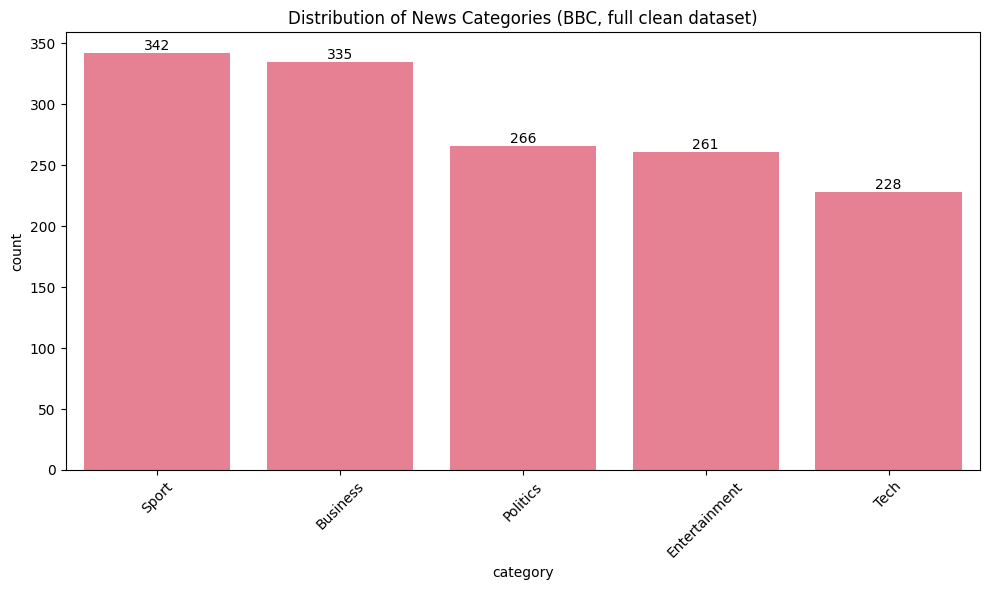

In [ ]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles (full clean dataset): {len(df_full)}")
print(f"Working set used by later cells ({RUN_TAG}): {len(df)}")
print(f"Unique categories: {df_full['category'].nunique()}")
print(f"Categories: {sorted(df_full['category'].unique().tolist())}")
print("Date / source: not available – single source (BBC), no publication dates in this file")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df_full['category'].value_counts()
category_pct = (category_counts / category_counts.sum() * 100).round(1)
print(pd.DataFrame({'articles': category_counts, 'percent': category_pct}))
imbalance_ratio = category_counts.max() / category_counts.min()
print(f"\nImbalance ratio (largest / smallest class): {imbalance_ratio:.2f}")

# Visualize category distribution
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df_full, x='category', order=category_counts.index)
ax.bar_label(ax.containers[0])          # show the count on top of each bar
plt.title('Distribution of News Categories (BBC, full clean dataset)')
plt.xticks(rotation=45)
plt.tight_layout()
save_figure('m1_category_distribution')
plt.show()

🕳️ MISSING VALUES PER COLUMN
article_id    0
content       0
category      0
title         0
full_text     0
dtype: int64
Empty or whitespace-only texts: 0

📏 WORDS PER ARTICLE BY CATEGORY
               count   mean  median    std    min     max
category                                                 
Business       335.0  334.0   304.0  134.0  145.0   902.0
Entertainment  261.0  335.0   271.0  207.0  144.0  2448.0
Politics       266.0  452.0   445.0  261.0   90.0  3345.0
Sport          342.0  337.0   296.0  186.0  116.0  1671.0
Tech           228.0  505.0   460.0  208.0  188.0  1549.0
🖼️ Figure saved: m1_text_length.png


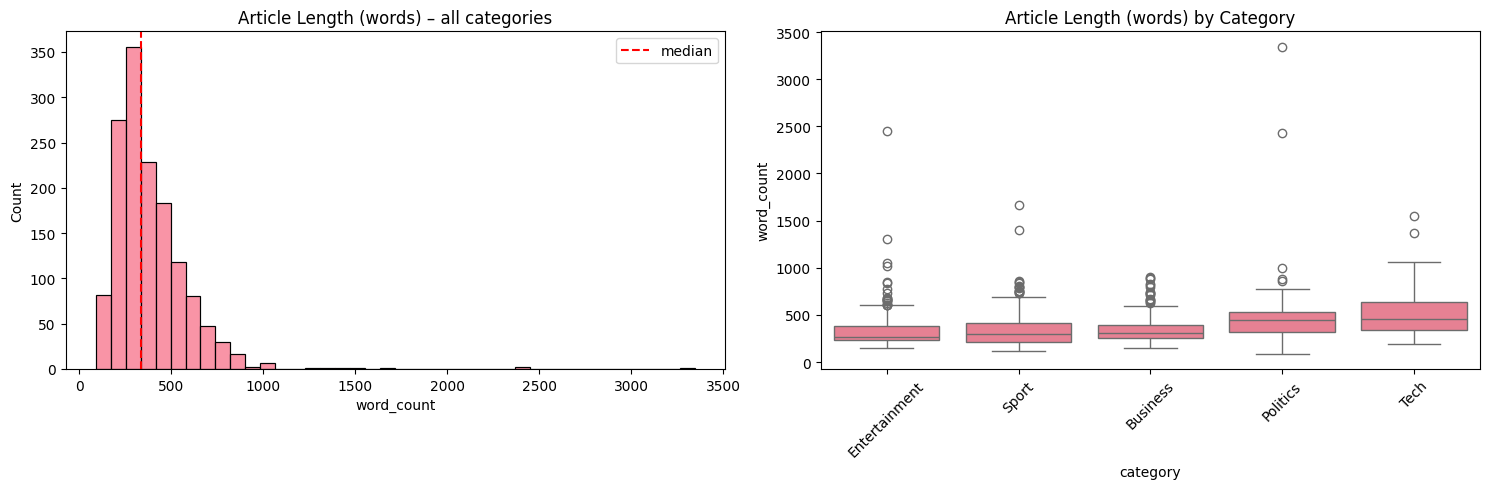

In [ ]:
# 💡 STUDENT TASK: missing values + text length distribution
print("🕳️ MISSING VALUES PER COLUMN")
print(df_full.isna().sum())
print(f"Empty or whitespace-only texts: {(df_full['content'].str.strip() == '').sum()}")

# Length features on the raw content
df_full['char_count'] = df_full['content'].str.len()
df_full['word_count'] = df_full['content'].str.split().str.len()

print("\n📏 WORDS PER ARTICLE BY CATEGORY")
length_stats = (df_full.groupby('category')['word_count']
                .describe()[['count', 'mean', '50%', 'std', 'min', 'max']]
                .rename(columns={'50%': 'median'}).round(0))
print(length_stats)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df_full['word_count'], bins=40, ax=axes[0])
axes[0].axvline(df_full['word_count'].median(), color='red', linestyle='--', label='median')
axes[0].set_title('Article Length (words) – all categories')
axes[0].legend()

order = length_stats['median'].sort_values().index
sns.boxplot(data=df_full, x='category', y='word_count', order=order, ax=axes[1])
axes[1].set_title('Article Length (words) by Category')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
save_figure('m1_text_length')
plt.show()

In [ ]:
def find_quality_issues(data):
    """Flag potential data quality problems and print a few examples of each."""
    q1, q3 = data['word_count'].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)          # IQR rule for unusually long articles
    first20 = data['content'].str.split().str[:20].str.join(' ')

    issues = {
        'Very short (< 100 words)': data[data['word_count'] < 100],
        f'Long outliers (> {upper:.0f} words, IQR rule)': data[data['word_count'] > upper],
        'Contains non-ASCII characters': data[data['content'].apply(lambda t: any(ord(c) > 127 for c in t))],
        'Contains URLs or HTML tags': data[data['content'].str.contains(r'http|www\.|<[^>]+>', regex=True)],
        'Possible near-duplicates (same first 20 words)': data[first20.duplicated(keep=False)],
    }

    print("🧪 DATA QUALITY ISSUES")
    print("=" * 60)
    for name, rows in issues.items():
        print(f"\n{name}: {len(rows)} articles")
        for _, r in rows.head(3).iterrows():
            print(f"   [{r['article_id']} | {r['category']}] {r['content'][:80]}...")

    # Which non-ASCII characters occur? (decides how Module 2 cleans them)
    non_ascii_chars = Counter(c for t in data['content'] for c in t if ord(c) > 127)
    print(f"\nMost common non-ASCII characters: {non_ascii_chars.most_common(10)}")
    print(f"\nReminder – text is lowercased: {IS_LOWERCASED}")
    return {name: len(rows) for name, rows in issues.items()}


quality_summary = find_quality_issues(df_full)

🧪 DATA QUALITY ISSUES

Very short (< 100 words): 1 articles
   [324 | Politics] blunkett hints at election call ex-home secretary david blunkett has given fresh...

Long outliers (> 788 words, IQR rule): 47 articles
   [342 | Entertainment] u2 s desire to be number one u2  who have won three prestigious grammy awards fo...
   [702 | Tech] peer-to-peer nets  here to stay  peer-to-peer (p2p) networks are here to stay  a...
   [1026 | Sport] henman to face saulnier test british number one tim henman will face france s cy...

Contains non-ASCII characters: 419 articles
   [1833 | Business] worldcom ex-boss launches defence lawyers defending former worldcom chief bernie...
   [917 | Business] enron bosses in $168m payout eighteen former enron directors have agreed a $168m...
   [1866 | Entertainment] fockers fuel festive film chart comedy meet the fockers topped the festive box o...

Contains URLs or HTML tags: 2 articles
   [1588 | Sport] wenger signs new deal arsenal manager arsene wenger

In [ ]:
# Inspect near-duplicates and URL matches before deciding what to do with them
first20 = df_full['content'].str.split().str[:20].str.join(' ')
dup_mask = first20.duplicated(keep=False)

print("🔁 NEAR-DUPLICATE GROUPS")
if not dup_mask.any():
    print("   None left – the near-duplicate pairs were removed in M1-a ✅")
else:
    dup_groups = df_full[dup_mask].assign(opening=first20[dup_mask]).sort_values('opening')
    for opening, grp in dup_groups.groupby('opening'):
        print(f"\n'{opening[:60]}...'")
        for _, r in grp.iterrows():
            print(f"   id={r['article_id']:<5} {r['category']:<14} {r['word_count']:>4} words")
        words_a, words_b = set(grp['content'].iloc[0].split()), set(grp['content'].iloc[1].split())
        jaccard = len(words_a & words_b) / len(words_a | words_b)
        print(f"   word overlap (Jaccard, 1.0 = identical vocabulary): {jaccard:.2f}")

print("\n🌐 URL / HTML MATCHES IN CONTEXT")
url_rows = df_full[df_full['content'].str.contains(r'http|www\.|<[^>]+>', regex=True)]
for _, r in url_rows.iterrows():
    m = re.search(r'.{0,40}(?:http|www\.|<[^>]+>).{0,40}', r['content'])
    print(f"   id={r['article_id']}: ...{m.group(0) if m else '?'}...")

🔁 NEAR-DUPLICATE GROUPS
   None left – the near-duplicate pairs were removed in M1-a ✅

🌐 URL / HTML MATCHES IN CONTEXT
   id=1588: ...ar-old frenchman told arsenal s website www.arsenal.com:  my intention has always be...
   id=912: ...h could be close enough to the official www.dec.org.uk address to confuse some peopl...


## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [ ]:
# Initialize preprocessing tools
import unicodedata

lemmatizer = WordNetLemmatizer()
# NLTK's list contains 'won' (from "won't"); in news 'won' usually means WIN, so we keep it
stop_words = set(stopwords.words('english')) - {'won'}

# A contraction must be followed by whitespace, punctuation or end of text
_END = r"(?=[\s.,;:!?)\"]|$)"

# BBC text has apostrophes stripped ("don t", "it s"); new articles have them ("don't").
# expand_contractions() first turns apostrophes into spaces so both forms look the same.
CONTRACTION_PATTERNS = [
    (r"\bwon t" + _END, "will not"),
    (r"\bcan t" + _END, "cannot"),
    (r"\bain t" + _END, "is not"),
    (r"\b(\w+)n t" + _END, r"\1 not"),                                   # don t -> do not
    (r"\bi m" + _END, "i am"),
    (r"\b(you|we|they|who|what) re" + _END, r"\1 are"),
    (r"\b(i|you|we|they|could|would|should|might|must) ve" + _END, r"\1 have"),
    (r"\b(i|you|he|she|it|we|they|that|there) ll" + _END, r"\1 will"),
    (r"\b(i|you|he|she|we|they) d" + _END, r"\1 would"),
    (r"(?<=\w) s" + _END, ""),                                           # world s -> world
]

# Option B: money amounts become tokens so TF-IDF can still "see" money talk
CURRENCY_PATTERNS = [
    (r"£\s?\d[\d.,]*\s?(?:bn|m|k|billion|million|thousand)?\b", " currency_gbp "),
    (r"\$\s?\d[\d.,]*\s?(?:bn|m|k|billion|million|thousand)?\b", " currency_usd "),
    (r"€\s?\d[\d.,]*\s?(?:bn|m|k|billion|million|thousand)?\b", " currency_eur "),
    (r"[£$€]", " "),
]


def expand_contractions(text):
    """Repair contractions in both forms ("don't" and BBC-style "don t"). Casing and punctuation are kept."""
    if text is None or pd.isna(text):
        return ""
    text = re.sub(r"[’‘`´]", "'", str(text))     # curly/odd apostrophes -> '
    text = text.replace("'", " ")                  # "don't" -> "don t" (same as BBC form)
    for pattern, replacement in CONTRACTION_PATTERNS:
        text = re.sub(pattern, replacement, text, flags=re.IGNORECASE)
    return text


def clean_text(text):
    """
    Comprehensive text cleaning function

    Handles: contractions, HTML tags and entities, URLs and e-mails, currency amounts
    (-> tokens), non-ASCII characters (é -> e), digits/punctuation, extra whitespace.
    Returns a lowercase string of letters (plus currency tokens), or "" for empty input.
    """
    if text is None or pd.isna(text):
        return ""

    text = expand_contractions(text).lower()

    text = re.sub(r'<[^>]+>', ' ', text)                       # HTML tags
    text = re.sub(r'&[a-z]+;|&#\d+;', ' ', text)               # HTML entities (&amp; &#39;)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)              # URLs
    text = re.sub(r'\S+@\S+', ' ', text)                       # e-mail addresses
    for pattern, replacement in CURRENCY_PATTERNS:             # £168m -> currency_gbp
        text = re.sub(pattern, replacement, text)
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('ascii')  # café -> cafe
    text = re.sub(r'[^a-z_\s]', ' ', text)                     # digits, punctuation, hyphens -> space
    text = re.sub(r'\s+', ' ', text).strip()                   # extra whitespace
    return text


def preprocess_text(text, remove_stopwords=True, lemmatize=True, min_len=3):
    """
    Complete preprocessing pipeline: clean -> tokenize -> remove stop words -> lemmatize -> drop short tokens.
    Returns the processed text as one string ("" if nothing meaningful is left).
    """
    text = clean_text(text)
    if not text:
        return ""

    tokens = word_tokenize(text)
    if remove_stopwords:
        tokens = [t for t in tokens if t not in stop_words]
    if lemmatize:
        tokens = [lemmatizer.lemmatize(t) for t in tokens]
    tokens = [t for t in tokens if len(t) >= min_len]
    return ' '.join(tokens)


# Test the preprocessing functions, including edge cases
test_cases = {
    'Starter example': "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews",
    'BBC style': df['content'].iloc[0][:160],
    'Contractions + money': "They don't think Microsoft's £2.5bn deal won't pass – it's 'Café' news.",
    'Sport "won"': "arsenal won the match 3-1 and the manager s plan worked",
    'Empty string': "",
    'None value': None,
    'Only symbols': "!!! 123 $$$",
}
for name, sample in test_cases.items():
    print(f"\n🔹 {name}")
    print(f"   original:     {sample!r}")
    print(f"   cleaned:      {clean_text(sample)!r}")
    print(f"   preprocessed: {preprocess_text(sample)!r}")


🔹 Starter example
   original:     'Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews'
   cleaned:      'apple inc announced record quarterly earnings today visit for more info technews'
   preprocessed: 'apple inc announced record quarterly earnings today visit info technews'

🔹 BBC style
   original:     'worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower a'
   cleaned:      'worldcom ex boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower a'
   preprocessed: 'worldcom bos launch defence lawyer defending former worldcom chief bernie ebbers battery fraud charge called company whistleblower'

🔹 Contractions + money
   original:     "They don't think Microsoft's £2.5bn deal won't pass – it's 'Café' news."
   cleaned:      'they do not 

In [ ]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")

# Version 1 – RAW (contractions repaired only): keeps punctuation and word order
#             -> used for NER, POS tagging, dependency parsing, sentiment
df['full_text'] = df['content'].apply(expand_contractions)
# Version 2 – CLEAN: lowercase letters + currency tokens -> inspection and word statistics
df['content_clean'] = df['content'].apply(clean_text)
# Version 3 – PROCESSED: clean + stop words removed + lemmatized -> TF-IDF and classification
df['full_text_processed'] = df['content'].apply(preprocess_text)

# Note: the starter's title_clean / title_processed / content_processed columns are dropped –
# the title is only a pseudo-title, and content_processed would be identical to full_text_processed.

n_empty_processed = (df['full_text_processed'] == '').sum()
print(f"✅ Preprocessing complete! Articles with empty processed text: {n_empty_processed}")

# Show before and after examples
print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1} ({df.iloc[i]['category']}):")
    print(f"Original:  {df.iloc[i]['content'][:100]}...")
    print(f"Raw (V1):  {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

🧹 Preprocessing all articles...
✅ Preprocessing complete! Articles with empty processed text: 0

📝 BEFORE AND AFTER EXAMPLES

Example 1 (Business):
Original:  worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a ba...
Raw (V1):  worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a ba...
Processed: worldcom bos launch defence lawyer defending former worldcom chief bernie ebbers battery fraud charg...

Example 2 (Business):
Original:  german business confidence slides german business confidence fell in february knocking hopes of a sp...
Raw (V1):  german business confidence slides german business confidence fell in february knocking hopes of a sp...
Processed: german business confidence slide german business confidence fell february knocking hope speedy recov...

Example 3 (Business):
Original:  bbc poll indicates economic gloom citizens in a majority of nations surveyed in a bbc world service ...
R

### 📄 Text versions used in this notebook

| Column | What it contains | Used by | Why this version |
|---|---|---|---|
| `full_text` | Original text, contractions repaired, punctuation and word order kept | NER, POS, dependency parsing, VADER sentiment | These tools need sentence structure, punctuation and (where available) casing. VADER also needs negations like "not" intact. |
| `content_clean` | Lowercase letters + currency tokens | Word statistics | Shows the effect of cleaning alone |
| `full_text_processed` | Cleaned, stop words removed, lemmatized | TF-IDF, classification | Removes noise and merges word forms (e.g. "elections" → "election") so features are fewer and more meaningful |

Limitation: the BBC text is already lowercased, so `full_text` cannot restore capital letters for NER and POS tagging.

📏 BEFORE vs AFTER PREPROCESSING
            1. raw (lowercased)  2. cleaned  3. processed  \
avg_words                 384.0       376.2         210.5   
avg_chars                2227.3      2150.3        1494.1   
vocab_size              35585.0     23536.0       20637.0   

            change raw→processed %  
avg_words                    -45.2  
avg_chars                    -32.9  
vocab_size                   -42.0  

💷 Currency tokens: gbp=881, usd=812, eur=0
🖼️ Figure saved: m2_top_words.png


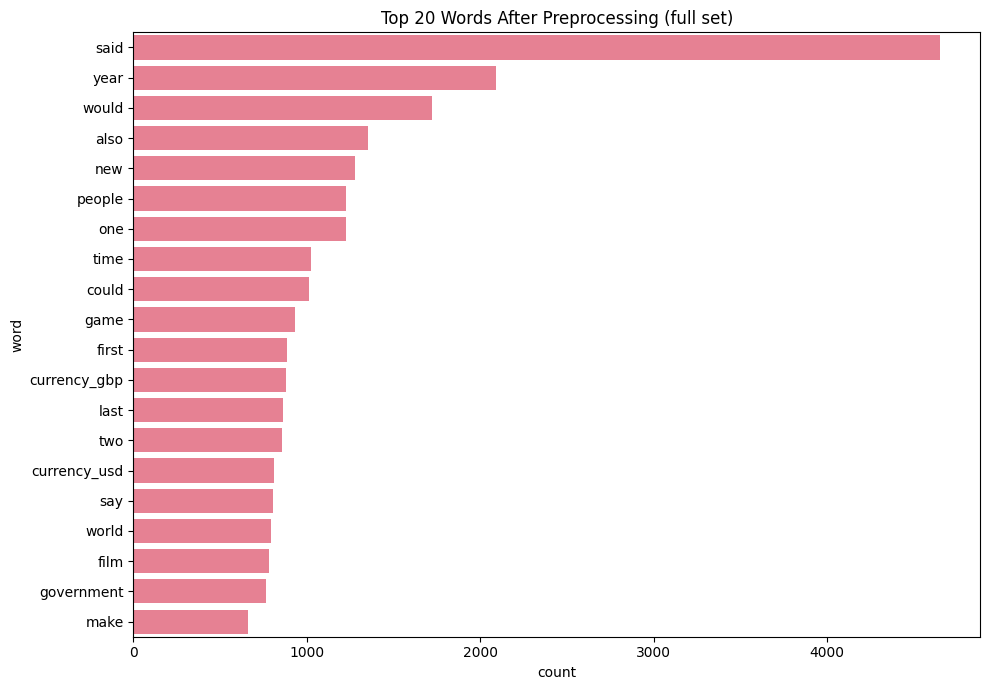

In [ ]:
# 💡 STUDENT TASK: analyze the preprocessing results
def text_stats(series):
    """Average words, average characters and vocabulary size of a text column (whitespace tokens)."""
    tokens = series.str.split()
    vocab = {t for toks in tokens for t in toks}
    return {'avg_words': tokens.str.len().mean(),
            'avg_chars': series.str.len().mean(),
            'vocab_size': len(vocab)}

stats_table = pd.DataFrame({
    '1. raw (lowercased)': text_stats(df['content'].str.lower()),
    '2. cleaned': text_stats(df['content_clean']),
    '3. processed': text_stats(df['full_text_processed']),
})
stats_table['change raw→processed %'] = (stats_table['3. processed'] / stats_table['1. raw (lowercased)'] - 1) * 100
print("📏 BEFORE vs AFTER PREPROCESSING")
print(stats_table.round(1))

# Most common words after preprocessing
word_freq = Counter(' '.join(df['full_text_processed']).split())
top_words = pd.DataFrame(word_freq.most_common(20), columns=['word', 'count'])
print(f"\n💷 Currency tokens: gbp={word_freq['currency_gbp']}, usd={word_freq['currency_usd']}, eur={word_freq['currency_eur']}")

plt.figure(figsize=(10, 7))
sns.barplot(data=top_words, y='word', x='count')
plt.title(f'Top 20 Words After Preprocessing ({RUN_TAG} set)')
plt.tight_layout()
save_figure('m2_top_words')
plt.show()

### 🔍 Preprocessing Findings (my interpretation)

**Size reduction (full dataset, 1,432 articles):**

| Step | Avg words | Vocabulary |
|---|---|---|
| Raw (lowercased) | 384.0 | 35,585 |
| Cleaned | 376.2 (−2.0%) | 23,536 (−33.9%) |
| Processed | 210.5 (−44.0% vs cleaned) | 20,637 (−12.3% vs cleaned) |

Cleaning removed few words but many vocabulary entries because punctuation attached to words (e.g. "time." and "time,") and numbers created many separate unique tokens. Removing them merged these variants while leaving most meaningful words intact.

Stop-word removal and lemmatization removed 44.0% of the words but only 12.3% of the vocabulary because stop words are a small set of distinct words that occur very frequently, so removing them deletes many tokens but few vocabulary entries.

A smaller vocabulary helps TF-IDF and classification because it reduces the number of features, lowers computational costs, and helps models focus on more meaningful words.

**Top words:** The five most frequent are said, year, would, also, new. Words like said, year, also and would could appear in any category, while game, film and government seem linked to specific categories.

**Currency tokens:** 881 £ amounts and 812 $ amounts (no € in the dataset).
Converting amounts to tokens was useful because it preserves information about the currency mentioned without keeping different numerical amounts as separate features.

**Lemmatization limitation:** "said" and "say" remain separate words because the lemmatizer may not correctly identify their relationship without appropriate part-of-speech information. This matters somewhat because it creates separate features for words with the same base meaning, although the overall impact may be small compared with the benefits of preprocessing.

**Design decisions:** I kept "won" because NLTK's stop-word list includes it (from "won't"), but in news it usually means "win", which matters especially for Sport articles. Currency tokens retain financial information while reducing numerical noise. I kept raw and processed text versions because NER, POS tagging, dependency parsing and VADER need punctuation, word order and negations such as "not", while TF-IDF and classification work better on cleaned, normalized text.

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [ ]:
# TF-IDF parameter optimization (5-fold cross-validated accuracy)
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold

# Generic news words that appear in every category (from Module 2 top words) – edit if you like
NEWS_STOPWORDS = ['said', 'say', 'also', 'would', 'could', 'one', 'two',
                  'year', 'last', 'first', 'mr', 'told', 'make']

BASE_TFIDF = dict(ngram_range=(1, 2), min_df=2, max_df=0.8, max_features=5000,
                  sublinear_tf=False, stop_words=None)          # = starter notebook settings

TFIDF_CONFIGS = {
    'starter baseline':                       {},
    'unigrams only':                          dict(ngram_range=(1, 1)),
    'max_df 0.5':                             dict(max_df=0.5),
    'custom news stopwords':                  dict(stop_words=NEWS_STOPWORDS),
    'sublinear_tf':                           dict(sublinear_tf=True),
    'min_df 5':                               dict(min_df=5),
    '10k features + sublinear':               dict(max_features=10000, sublinear_tf=True),
    'combined (0.5 + stopwords + sublinear)': dict(max_df=0.5, stop_words=NEWS_STOPWORDS, sublinear_tf=True),
}


def evaluate_tfidf_configs(texts, labels, configs, cv_folds=5):
    """Score each TF-IDF setting with a TF-IDF -> LinearSVC pipeline using stratified k-fold CV.

    The vectorizer is inside the pipeline, so in every fold it is fitted on the training part only.
    """
    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for name, overrides in configs.items():
        params = {**BASE_TFIDF, **overrides}
        pipe = Pipeline([('tfidf', TfidfVectorizer(**params)),
                         ('clf', LinearSVC(random_state=RANDOM_STATE))])
        start = time.time()
        scores = cross_val_score(pipe, texts, labels, cv=cv, scoring='accuracy')
        vocab_size = len(TfidfVectorizer(**params).fit(texts).vocabulary_)
        rows.append({'config': name, 'cv_accuracy': scores.mean(), 'cv_std': scores.std(),
                     'vocab_size': vocab_size, 'seconds': time.time() - start, 'params': params})
        print(f"  {name:<40} acc={scores.mean():.4f} ± {scores.std():.4f}")
    # Best = highest accuracy; ties broken by the smaller vocabulary
    return (pd.DataFrame(rows)
            .sort_values(['cv_accuracy', 'vocab_size'], ascending=[False, True])
            .reset_index(drop=True))


print("🔧 Comparing TF-IDF settings...")
tfidf_results = cached('tfidf_param_search',
                       lambda: evaluate_tfidf_configs(df['full_text_processed'], df['category'], TFIDF_CONFIGS))

print("\n🏆 TF-IDF PARAMETER COMPARISON (sorted by CV accuracy)")
print(tfidf_results.drop(columns='params').round(4).to_string(index=False))

BEST_TFIDF_PARAMS = tfidf_results.loc[0, 'params']
print(f"\n🥇 Best setting: {tfidf_results.loc[0, 'config']}")
print(f"   {BEST_TFIDF_PARAMS}")

🔧 Comparing TF-IDF settings...
  starter baseline                         acc=0.9658 ± 0.0139
  unigrams only                            acc=0.9658 ± 0.0150
  max_df 0.5                               acc=0.9665 ± 0.0144
  custom news stopwords                    acc=0.9679 ± 0.0155
  sublinear_tf                             acc=0.9749 ± 0.0122
  min_df 5                                 acc=0.9658 ± 0.0158
  10k features + sublinear                 acc=0.9735 ± 0.0107
  combined (0.5 + stopwords + sublinear)   acc=0.9721 ± 0.0115
⏱️ 'tfidf_param_search' computed in 89.6s
💾 Saved tfidf_param_search_full.pkl

🏆 TF-IDF PARAMETER COMPARISON (sorted by CV accuracy)
                                config  cv_accuracy  cv_std  vocab_size  seconds
                          sublinear_tf       0.9749  0.0122        5000  11.5477
              10k features + sublinear       0.9735  0.0107       10000  10.5449
combined (0.5 + stopwords + sublinear)       0.9721  0.0115        5000  12.8322
        

In [ ]:
# Create TF-IDF vectorizer with the best settings from the comparison above
# NOTE: fitted on ALL articles for DESCRIPTIVE analysis only (which terms characterise each category).
#       The Module 7 classifier fits its own vectorizer inside a Pipeline on training data only.
tfidf_vectorizer = TfidfVectorizer(**BEST_TFIDF_PARAMS)

print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])   # stays SPARSE
feature_names = tfidf_vectorizer.get_feature_names_out()

n_cells = tfidf_matrix.shape[0] * tfidf_matrix.shape[1]
print("✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / n_cells) * 100:.2f}%  (share of zero cells)")

# Instead of a huge dense DataFrame: show the top terms of one article (one row -> dense is cheap)
first_row = tfidf_matrix[0].toarray().ravel()
top_idx = first_row.argsort()[::-1][:10]
print(f"\n🔍 Top TF-IDF terms of article 0 ({df.loc[0, 'category']}):")
for i in top_idx:
    print(f"  {feature_names[i]}: {first_row[i]:.4f}")

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1432, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.42%  (share of zero cells)

🔍 Top TF-IDF terms of article 0 (Business):
  worldcom: 0.2962
  ebbers: 0.2706
  accounting: 0.2500
  cooper: 0.2242
  fraud: 0.1747
  mci: 0.1615
  auditor: 0.1591
  witness: 0.1529
  lawyer: 0.1478
  sullivan: 0.1437


In [ ]:
# Analyze most important terms per category
categories = sorted(df['category'].unique())
y_labels = df['category'].values

# Mean TF-IDF of every term within each category (5 rows x vocabulary – small enough to be dense)
category_means = pd.DataFrame(
    np.vstack([np.asarray(tfidf_matrix[y_labels == c].mean(axis=0)).ravel() for c in categories]),
    index=categories, columns=feature_names)


def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    Uses the mean TF-IDF score of each term across the category's articles
    and returns the n_terms highest as a pandas Series (term -> score).
    """
    if category not in category_means.index:
        raise ValueError(f"Unknown category '{category}'. Options: {categories}")
    return category_means.loc[category].nlargest(n_terms)


print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)
category_terms = {}
for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms
    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  currency_usd: 0.0497
  firm: 0.0380
  company: 0.0376
  market: 0.0356
  year: 0.0316
  share: 0.0304
  growth: 0.0294
  currency_gbp: 0.0284
  economy: 0.0281
  bank: 0.0277

📰 ENTERTAINMENT:
  film: 0.0646
  award: 0.0422
  star: 0.0404
  best: 0.0332
  show: 0.0328
  actor: 0.0320
  year: 0.0309
  music: 0.0301
  oscar: 0.0273
  band: 0.0262

📰 POLITICS:
  labour: 0.0492
  election: 0.0487
  party: 0.0441
  government: 0.0435
  blair: 0.0433
  minister: 0.0431
  tory: 0.0403
  would: 0.0394
  say: 0.0288
  plan: 0.0283

📰 SPORT:
  game: 0.0417
  win: 0.0346
  player: 0.0325
  match: 0.0322
  champion: 0.0301
  team: 0.0292
  england: 0.0282
  cup: 0.0274
  first: 0.0263
  final: 0.0262

📰 TECH:
  people: 0.0429
  user: 0.0409
  technology: 0.0386
  computer: 0.0354
  software: 0.0333
  mobile: 0.0318
  phone: 0.0311
  service: 0.0308
  net: 0.0305
  use: 0.0300


🖼️ Figure saved: m3_wordclouds.png


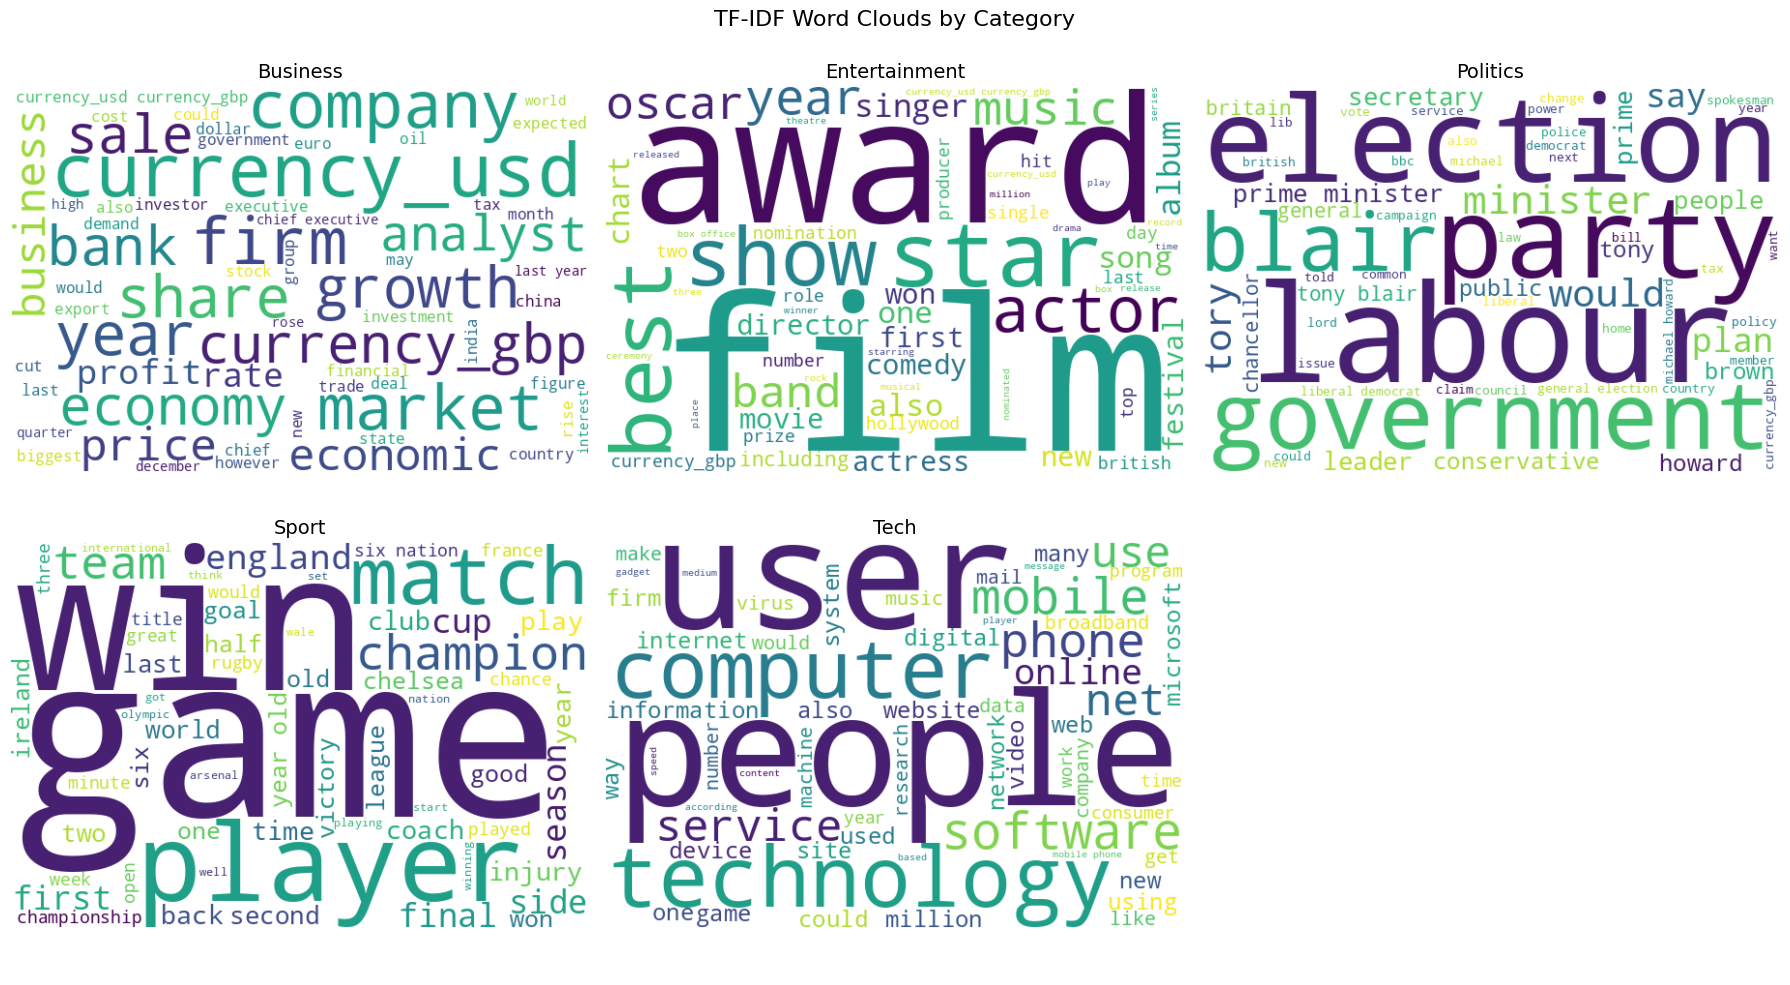

🖼️ Figure saved: m3_top_terms_bar.png


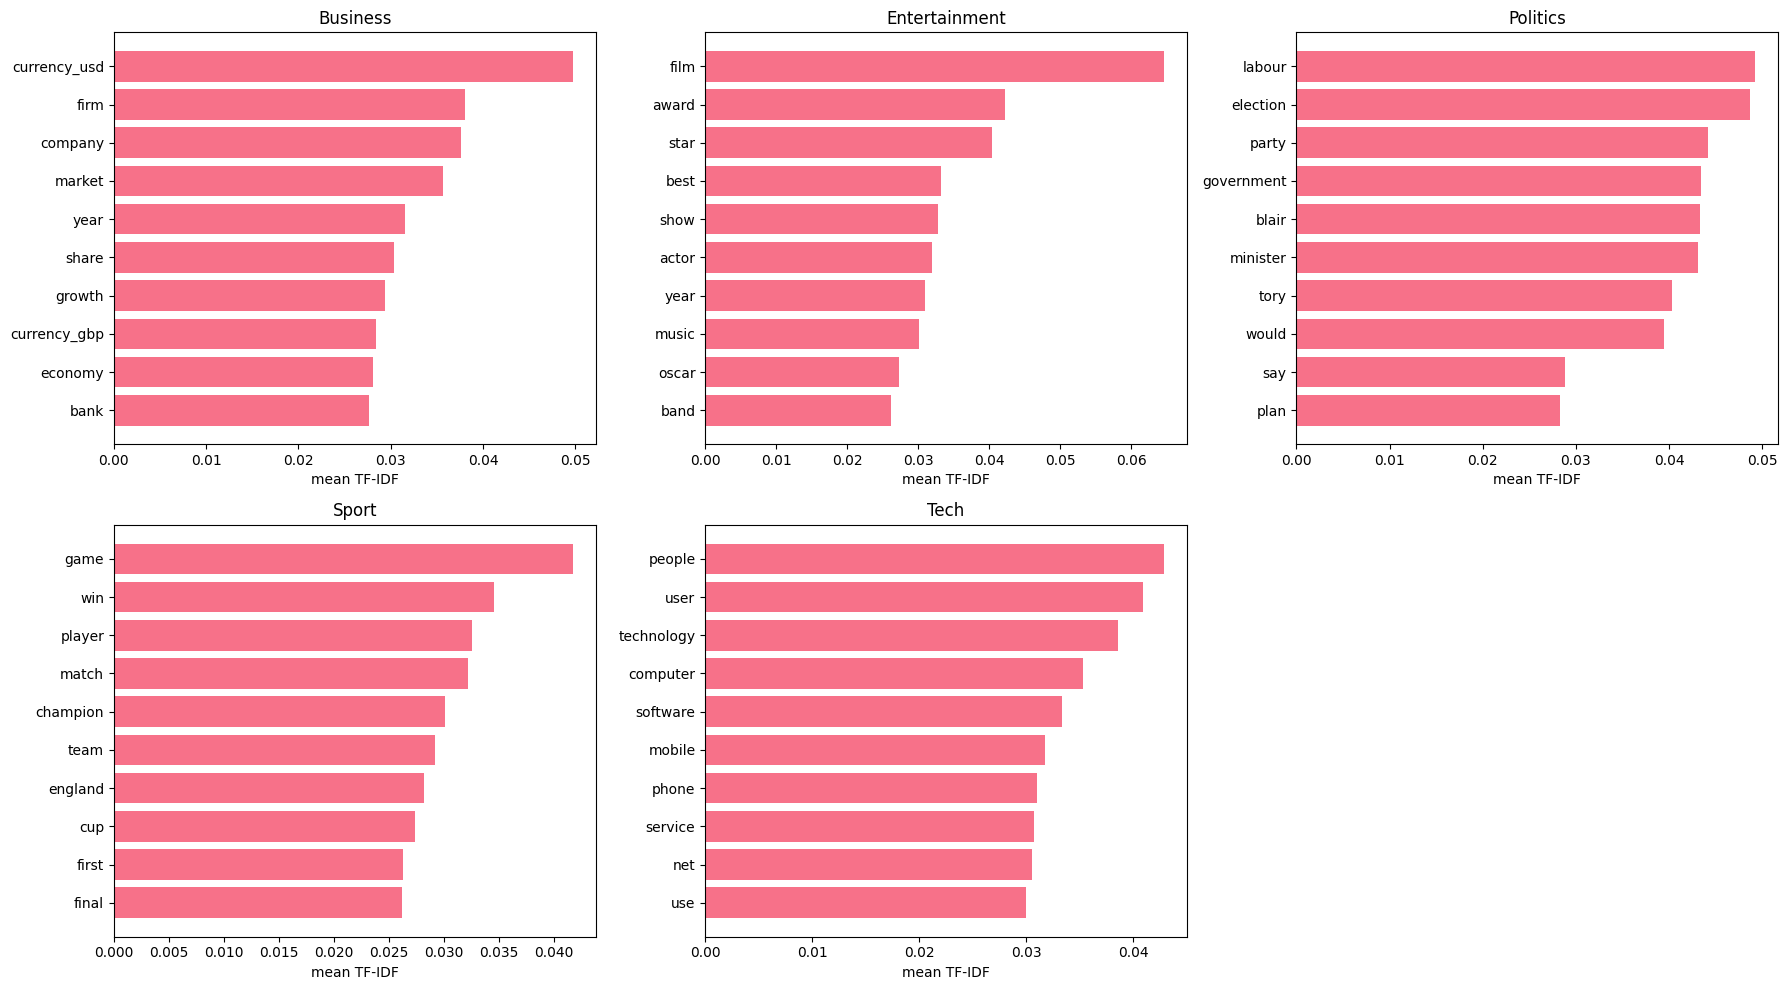

🖼️ Figure saved: m3_term_heatmap.png


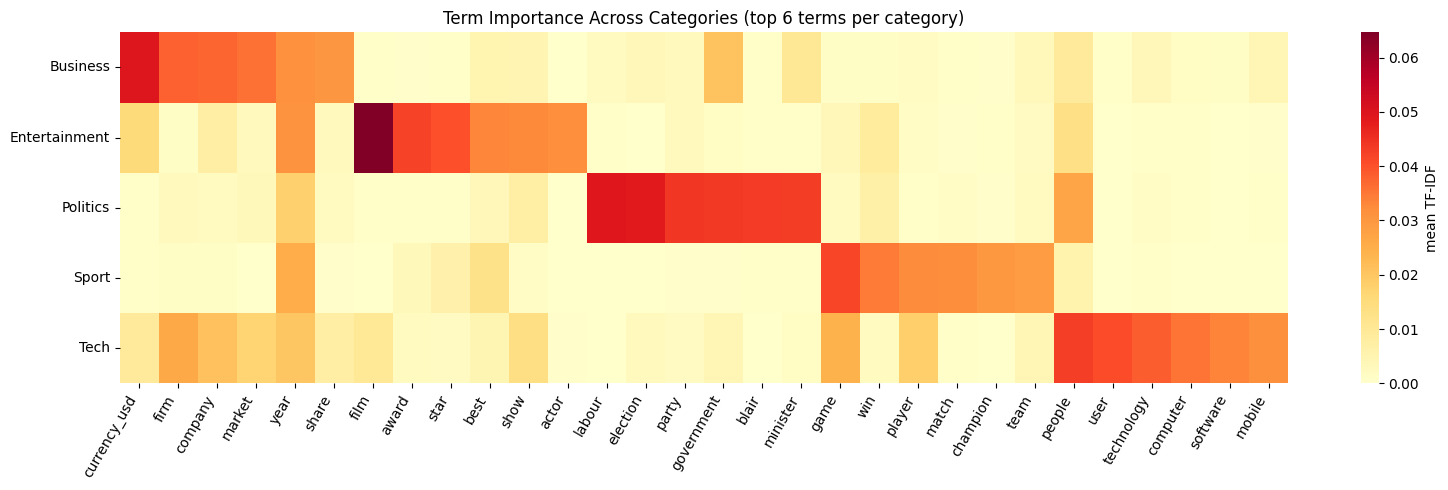

In [ ]:
# 💡 STUDENT TASK: TF-IDF visualizations (word clouds, bar charts, heatmap)
ncols = 3
nrows = int(np.ceil(len(categories) / ncols))

# 1) Word clouds – word size = mean TF-IDF in that category
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
axes = axes.ravel()
for ax, cat in zip(axes, categories):
    freqs = category_means.loc[cat].nlargest(60).to_dict()
    wc = WordCloud(width=600, height=400, background_color='white',
                   random_state=RANDOM_STATE).generate_from_frequencies(freqs)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(cat, fontsize=14)
    ax.axis('off')
for ax in axes[len(categories):]:
    ax.axis('off')
plt.suptitle('TF-IDF Word Clouds by Category', fontsize=16)
plt.tight_layout()
save_figure('m3_wordclouds', fig)
plt.show()

# 2) Bar charts of the top 10 terms per category
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
axes = axes.ravel()
for ax, cat in zip(axes, categories):
    top = category_means.loc[cat].nlargest(10)[::-1]
    ax.barh(top.index, top.values)
    ax.set_title(cat)
    ax.set_xlabel('mean TF-IDF')
for ax in axes[len(categories):]:
    ax.axis('off')
plt.tight_layout()
save_figure('m3_top_terms_bar', fig)
plt.show()

# 3) Heatmap: top 6 terms of each category, scored in ALL categories
heat_terms = list(dict.fromkeys(t for cat in categories for t in category_means.loc[cat].nlargest(6).index))
plt.figure(figsize=(16, 5))
sns.heatmap(category_means[heat_terms], cmap='YlOrRd', cbar_kws={'label': 'mean TF-IDF'})
plt.title('Term Importance Across Categories (top 6 terms per category)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
save_figure('m3_term_heatmap')
plt.show()

In [ ]:
# Feature importance with chi-square: which terms best DISTINGUISH the categories?
# chi2 expects COUNTS -> use raw term counts over the same vocabulary as the TF-IDF vectorizer
from sklearn.feature_selection import chi2

count_vectorizer = CountVectorizer(vocabulary=tfidf_vectorizer.vocabulary_,
                                   ngram_range=BEST_TFIDF_PARAMS['ngram_range'],
                                   stop_words=BEST_TFIDF_PARAMS['stop_words'])
count_matrix = count_vectorizer.fit_transform(df['full_text_processed'])
count_terms = count_vectorizer.get_feature_names_out()

chi_scores, p_values = chi2(count_matrix, y_labels)
chi_df = (pd.DataFrame({'term': count_terms, 'chi2': chi_scores, 'p_value': p_values})
          .sort_values('chi2', ascending=False))
print("📈 TOP 15 TERMS OVERALL (chi-square on term counts, all 5 categories)")
print(chi_df.head(15).to_string(index=False, formatters={'chi2': '{:.1f}'.format, 'p_value': '{:.2e}'.format}))
print(f"\nTerms significant at p < 0.05: {(chi_df['p_value'] < 0.05).sum()} of {len(chi_df)}")

# One-vs-rest: top terms per category, keeping only terms MORE common in that category than elsewhere
rows = []
for cat in categories:
    scores, _ = chi2(count_matrix, y_labels == cat)
    in_cat = np.asarray(count_matrix[y_labels == cat].mean(axis=0)).ravel()
    rest = np.asarray(count_matrix[y_labels != cat].mean(axis=0)).ravel()
    scores = np.where(in_cat > rest, np.nan_to_num(scores), 0)
    top_idx = scores.argsort()[::-1][:8]
    rows.append({'category': cat, 'top chi-square terms': ', '.join(count_terms[top_idx])})

print("\n🏷️ MOST DISTINCTIVE TERMS PER CATEGORY (one-vs-rest chi-square)")
print(pd.DataFrame(rows).to_string(index=False))

📈 TOP 15 TERMS OVERALL (chi-square on term counts, all 5 categories)
        term   chi2   p_value
        film 2580.0  0.00e+00
      labour 1945.5  0.00e+00
    election 1677.4  0.00e+00
       party 1641.4  0.00e+00
      mobile 1560.3  0.00e+00
       blair 1553.6  0.00e+00
  technology 1423.0 7.19e-307
        tory 1385.2 1.13e-298
        user 1374.4 2.47e-296
       phone 1355.9 2.54e-292
       award 1205.6 9.87e-260
currency_usd 1146.8 5.54e-247
    software 1144.7 1.55e-246
    minister 1113.8 7.85e-240
    computer 1108.2 1.27e-238

Terms significant at p < 0.05: 4215 of 5000

🏷️ MOST DISTINCTIVE TERMS PER CATEGORY (one-vs-rest chi-square)
     category                                                top chi-square terms
     Business    currency_usd, bank, growth, oil, economy, share, market, company
Entertainment                  film, award, best, actor, star, oscar, band, album
     Politics   labour, election, party, blair, tory, minister, government, brown
        Sport

### 🔍 TF-IDF Findings (my interpretation)

**Parameter comparison:** The best setting was the configuration with the highest cross-validation (CV) accuracy (sublinear_tf) with 97.5% CV accuracy (± 1.22 percentage points). The starter baseline reached 96.6%. Lowering `max_df` helped by 0.07 percentage points; the custom news stop-word list helped by 0.21 percentage points. Differences are not larger than the standard deviation (even the largest gain, +0.91 points for sublinear_tf, is smaller than the 1.1–1.6-point standard deviations), so the improvement may be due to variation between folds. I chose the configuration with the best CV accuracy because it provides the best classification performance during cross-validation.

**Top terms:** The top terms match my expectations for the five news categories because Business contains terms such as `company`, `market`, and `bank`; Entertainment contains `film`, `music`, and `award`; Politics contains `government`, `election`, and `minister`; Sport contains `game`, `champion`, and `match`; and Tech contains `mobile`, `user`, and `technology`. A surprising term was `people` in Tech, probably because technology news often discusses users and the impact of technology on people. The currency tokens are most important in Business, as shown by `currency_usd` and `currency_gbp` having high mean TF-IDF scores.

**Heatmap:** The categories with the most overlapping terms are Business and Tech (e.g. `firm`). I expect the classifier to confuse them in Module 7 because some business-related terms also appear in technology company news.

**TF-IDF vs chi-square:** Terms that are both prominent and distinctive include `market`, `bank`, and `growth` for Business; `film`, `award`, and `star` for Entertainment; `government`, `labour`, and `election` for Politics; `champion`, `win`, and `match` for Sport; and `mobile`, `user`, `technology`, and `net` for Tech. A term with a high mean TF-IDF but a lower chi-square score is `firm`, which means the word receives a relatively high TF-IDF weight but may also appear in multiple categories, making it less effective at distinguishing one category from another.

**Business value:** For my target users, these distinctive terms could be used for automatically categorizing news articles, improving search results, recommending relevant stories, and helping readers find news about topics they are interested in.

## ⚙️ Single spaCy Pass (feeds Modules 4, 5, 6 and 8)

Parsing text with spaCy is the slowest step in this notebook. Instead of calling `nlp(text)` separately in each module, every article is parsed **once** with `nlp.pipe()` (batched, much faster), and all linguistic features are extracted in that pass:
- **POS tags** (Module 4) – Penn Treebank tags (`NN`, `NNP`, `VBD`, `JJ`, `CD` …) plus writing-style metrics
- **Dependency parse** (Module 5) – relations, tree depth, passive voice, subject–verb–object triples
- **Named entities** (Module 8, and entity–sentiment in Module 6)

Results are cached to disk, so a Colab disconnect does not require re-parsing. The functions `analyze_pos_patterns()`, `extract_syntactic_features()` and `extract_entities()` from the starter notebook are defined here (moved up), because this pass needs all three. They accept raw text **or** an already-parsed Doc, so the NewsBot class can reuse them for new articles.

**Input:** `full_text` (raw text with punctuation, contractions repaired). **Limitation:** the BBC text is lowercased, so spaCy's small model will under-detect proper nouns and entities.

In [ ]:
# ===== Single spaCy pass – extraction functions (Modules 4, 5, 8) =====
from spacy.tokens import Doc


def _to_doc(text_or_doc):
    """Return a spaCy Doc: parse raw text, or pass an existing Doc through. None for empty input."""
    if isinstance(text_or_doc, Doc):
        return text_or_doc
    if text_or_doc is None or (not isinstance(text_or_doc, str) and pd.isna(text_or_doc)):
        return None
    text = str(text_or_doc).strip()
    return nlp(text) if text else None


def _content_tokens(doc):
    """Tokens that are real words/numbers (no punctuation, no whitespace)."""
    return [t for t in doc if not t.is_punct and not t.is_space]


# ---------- Module 4: POS ----------
def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text (spaCy version of the starter function)

    Uses spaCy's fine-grained Penn Treebank tags (token.tag_), the same tag set as NLTK's
    pos_tag, so the starter heatmap still works. Returns {tag: proportion of tokens}.
    Punctuation is excluded so proportions describe words only.
    """
    doc = _to_doc(text)
    if doc is None:
        return {}
    tags = [t.tag_ for t in _content_tokens(doc)]
    if not tags:
        return {}
    total = len(tags)
    return {tag: count / total for tag, count in Counter(tags).items()}


def compute_style_metrics(doc, ttr_window=100):
    """Writing-style metrics: POS shares (universal tags), sentence length, lexical diversity."""
    tokens = _content_tokens(doc)
    n = max(len(tokens), 1)
    upos = Counter(t.pos_ for t in tokens)
    sent_lengths = [len(_content_tokens(s)) for s in doc.sents]
    sent_lengths = [l for l in sent_lengths if l > 0]
    words = [t.lower_ for t in doc if t.is_alpha][:ttr_window]   # fixed window -> fair across lengths
    return {
        'n_sentences': len(sent_lengths),
        'avg_sentence_length': float(np.mean(sent_lengths)) if sent_lengths else 0.0,
        'lexical_diversity': len(set(words)) / len(words) if words else 0.0,
        'noun_share': (upos['NOUN'] + upos['PROPN']) / n,
        'propn_share': upos['PROPN'] / n,
        'verb_share': upos['VERB'] / n,
        'adj_share': upos['ADJ'] / n,
        'adv_share': upos['ADV'] / n,
        'num_share': upos['NUM'] / n,
        'noun_verb_ratio': (upos['NOUN'] + upos['PROPN']) / max(upos['VERB'], 1),
    }


# ---------- Module 5: syntax ----------
def _tree_depth(token):
    """Number of steps from a token up to its sentence root (= number of ancestors)."""
    return sum(1 for _ in token.ancestors)


def _phrase(token):
    """A noun with its compound modifiers, e.g. 'prime minister', 'tony blair'."""
    parts = [c for c in token.children if c.dep_ == 'compound'] + [token]
    return ' '.join(t.text for t in sorted(parts, key=lambda t: t.i)).lower()


def extract_svo(doc):
    """'Who did what to whom': (agent, action, patient) triples from the dependency parse.

    Active voice:  nsubj --verb--> dobj                 'blair announced election'
    Passive voice: agent (by ...) --verb--> nsubjpass   'firm was bought by google' -> (google, buy, firm)
    """
    triples = []
    for tok in doc:
        if tok.pos_ != 'VERB':
            continue
        subjects = [c for c in tok.children if c.dep_ in ('nsubj', 'nsubjpass')]
        objects = [c for c in tok.children if c.dep_ in ('dobj', 'attr', 'oprd')]
        agents = [g for c in tok.children if c.dep_ == 'agent' for g in c.children if g.dep_ == 'pobj']
        for s in subjects:
            if s.dep_ == 'nsubjpass':
                triples += [(_phrase(a), tok.lemma_.lower(), _phrase(s)) for a in agents]
            else:
                triples += [(_phrase(s), tok.lemma_.lower(), _phrase(o)) for o in objects]
    return triples


def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    Returns the starter's fields (dependency relations, noun phrases, verb phrases, subjects,
    objects) plus complexity measures (tree depth, passive voice share) and SVO triples.
    Accepts raw text or a spaCy Doc.
    """
    doc = _to_doc(text)
    if doc is None:
        return {}
    sents = [s for s in doc.sents if len(_content_tokens(s)) > 0]

    features = {
        'num_sentences': len(sents),
        'num_tokens': len(doc),
        'dependency_relations': [t.dep_ for t in _content_tokens(doc)],
        'noun_phrases': [chunk.text.lower() for chunk in doc.noun_chunks],
        'verb_phrases': [],
        'subjects': [t.text.lower() for t in doc if t.dep_ in ('nsubj', 'nsubjpass')],
        'objects': [t.text.lower() for t in doc if t.dep_ in ('dobj', 'iobj', 'pobj')],
    }
    for t in doc:   # verb phrase = verb lemma + particle/direct object ("take over firm")
        if t.pos_ == 'VERB':
            extra = [c.text for c in t.children if c.dep_ in ('prt', 'dobj')]
            if extra:
                features['verb_phrases'].append(' '.join([t.lemma_] + extra).lower())

    depths = [max(_tree_depth(t) for t in s) for s in sents]
    passive = sum(any(t.dep_ in ('nsubjpass', 'auxpass') for t in s) for s in sents)
    features['dependency_counts'] = dict(Counter(features['dependency_relations']))
    features['avg_tree_depth'] = float(np.mean(depths)) if depths else 0.0
    features['max_tree_depth'] = int(max(depths)) if depths else 0
    features['passive_sentence_share'] = passive / len(sents) if sents else 0.0
    features['svo_triples'] = extract_svo(doc)
    return features


# ---------- Module 8: named entities ----------
def extract_entities(text):
    """
    Extract named entities using spaCy

    Returns a list of {'text', 'label', 'start', 'end', 'description'} for every entity.
    Accepts raw text or a spaCy Doc.
    """
    doc = _to_doc(text)
    if doc is None:
        return []
    return [{'text': ent.text, 'label': ent.label_, 'start': ent.start_char,
             'end': ent.end_char, 'description': spacy.explain(ent.label_)} for ent in doc.ents]


# Quick test on two sentences (should finish instantly)
_test = extract_syntactic_features("the company was bought by google. blair announced a general election.")
print("✅ Functions ready.")
print(f"   Test SVO triples: {_test['svo_triples']}")
print(f"   Test tree depth (avg/max): {_test['avg_tree_depth']:.1f} / {_test['max_tree_depth']}")
print(f"   Test passive share: {_test['passive_sentence_share']:.2f}")

✅ Functions ready.
   Test SVO triples: [('google', 'buy', 'company'), ('blair', 'announce', 'election')]
   Test tree depth (avg/max): 2.0 / 2
   Test passive share: 0.50


In [ ]:
# ===== Single spaCy pass – run once over all articles and cache the results =====
def run_spacy_pass(texts, article_ids, batch_size=32):
    """Parse all texts with nlp.pipe() once and extract POS, style, syntax and entity features."""
    results = []
    start = time.time()
    for i, (doc, art_id) in enumerate(zip(nlp.pipe(texts, batch_size=batch_size), article_ids), 1):
        results.append({
            'article_id': art_id,
            'pos': analyze_pos_patterns(doc),
            'style': compute_style_metrics(doc),
            'syntax': extract_syntactic_features(doc),
            'entities': extract_entities(doc),
        })
        if i % 100 == 0:
            print(f"   {i}/{len(texts)} articles parsed ({time.time() - start:.0f}s)")
    return results


print(f"🔄 spaCy pass over {len(df)} articles ({RUN_TAG})...")
spacy_results = cached('spacy_features',
                       lambda: run_spacy_pass(df['full_text'].tolist(), df['article_id'].tolist()))

# Safety check: results must line up with df row by row
assert [r['article_id'] for r in spacy_results] == df['article_id'].tolist(), \
    "spaCy results do not match df – re-run with cached(..., force=True)"
print(f"✅ {len(spacy_results)} articles available for Modules 4, 5, 6 and 8")
if IS_LOWERCASED:
    print("⚠️ Text is lowercased: proper-noun tags (NNP/PROPN) and entities will be under-detected.")

🔄 spaCy pass over 1432 articles (full)...
   100/1432 articles parsed (11s)
   200/1432 articles parsed (18s)
   300/1432 articles parsed (24s)
   400/1432 articles parsed (32s)
   500/1432 articles parsed (38s)
   600/1432 articles parsed (45s)
   700/1432 articles parsed (50s)
   800/1432 articles parsed (56s)
   900/1432 articles parsed (64s)
   1000/1432 articles parsed (70s)
   1100/1432 articles parsed (76s)
   1200/1432 articles parsed (81s)
   1300/1432 articles parsed (89s)
   1400/1432 articles parsed (95s)
⏱️ 'spacy_features' computed in 97.2s
💾 Saved spacy_features_full.pkl
✅ 1432 articles available for Modules 4, 5, 6 and 8
⚠️ Text is lowercased: proper-noun tags (NNP/PROPN) and entities will be under-detected.


## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [ ]:
# Apply POS analysis to all articles
# (analyze_pos_patterns() now lives in the spaCy pass cell; results come from that single pass)
print("🏷️ Analyzing POS patterns...")

pos_results = []
for row, res in zip(df.itertuples(index=False), spacy_results):
    pos_analysis = dict(res['pos'])
    pos_analysis['category'] = row.category
    pos_analysis['article_id'] = row.article_id
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print("✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns) - 2} different POS tags")
print("\n📝 Sample POS analysis:")
print(pos_df.head())

🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
        NNP        NN       VBZ       NNS       VBG        JJ        IN  \
0  0.133779  0.170569  0.023411  0.110368  0.030100  0.053512  0.137124   
1  0.074534  0.189441  0.018634  0.074534  0.034161  0.090062  0.145963   
2  0.064706  0.141176  0.027451  0.084314  0.029412  0.068627  0.145098   
3  0.033333  0.138095  0.023810  0.112698  0.025397  0.074603  0.134921   
4  0.059783  0.192935  0.019022  0.076087  0.032609  0.081522  0.138587   

         DT       VBP       VBN  ...   UH   XX  ADD  POS    ,   LS  HYPH  NFP  \
0  0.070234  0.010033  0.040134  ...  0.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0   
1  0.093168  0.015528  0.034161  ...  0.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0   
2  0.101961  0.015686  0.035294  ...  0.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0   
3  0.066667  0.036508  0.022222  ...  0.0  0.0  0.0  0.0  0.0  0.0   0.0  0.0   
4  0.108696  0.010870  0.035326  ...

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
Business       0.1795  0.0750  0.0823  0.0006  0.0339  0.0406  0.0214  0.0327   
Entertainment  0.1961  0.0561  0.0990  0.0006  0.0286  0.0462  0.0209  0.0336   
Politics       0.1678  0.0675  0.0784  0.0013  0.0459  0.0469  0.0217  0.0332   
Sport          0.1659  0.0442  0.1029  0.0006  0.0390  0.0465  0.0185  0.0265   
Tech           0.1753  0.0880  0.0489  0.0005  0.0446  0.0297  0.0247  0.0307   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
Business       0.0148  0.0258  0.0729  0.0049  0.0035  0.0312  0.0020  0.0009   
Entertainment  0.0144  0.0220  0.0676  0.0024  0.0054  0.0315  0.0011  0.0015   
Politics       0.0181  0.0232  0.0718  0.0035  0

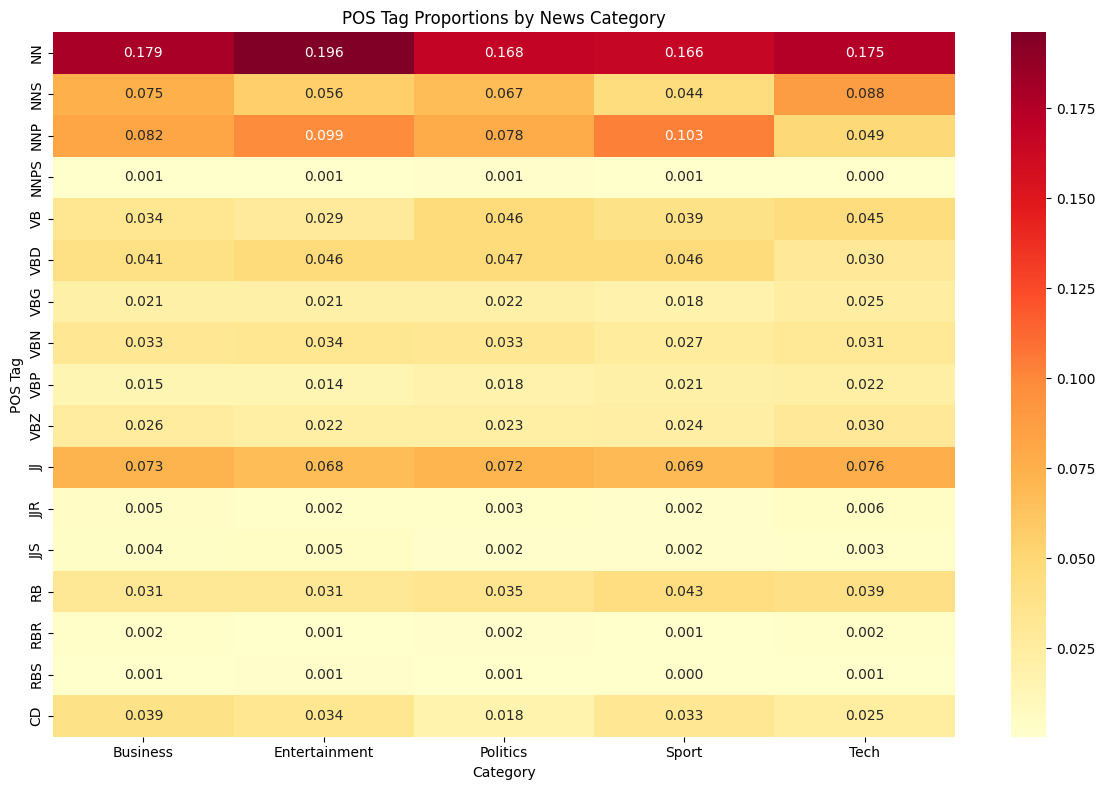


💡 ANALYSIS QUESTIONS:
1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
2. Which category uses the most action verbs (VB, VBD, VBG)?
3. Are there interesting patterns in adjective (JJ) usage?
4. How does number (CD) usage vary across categories?


In [ ]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions (article_id is not a POS tag -> dropped)
pos_by_category = pos_df.drop(columns='article_id').groupby('category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    save_figure('m4_pos_heatmap')
    plt.show()

    print("\n💡 ANALYSIS QUESTIONS:")
    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
    print("3. Are there interesting patterns in adjective (JJ) usage?")
    print("4. How does number (CD) usage vary across categories?")
else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

✍️ WRITING STYLE BY CATEGORY (means)
               noun_verb_ratio  noun_share  propn_share  verb_share  \
category                                                              
Business                 2.752       0.337        0.083       0.125   
Entertainment            3.040       0.351        0.100       0.121   
Politics                 2.336       0.314        0.080       0.137   
Sport                    2.625       0.312        0.103       0.126   
Tech                     2.374       0.312        0.049       0.134   

               adj_share  num_share  avg_sentence_length  lexical_diversity  
category                                                                     
Business           0.081      0.039               21.749              0.698  
Entertainment      0.075      0.034               21.348              0.704  
Politics           0.077      0.018               22.272              0.717  
Sport              0.072      0.033               19.579              0.725

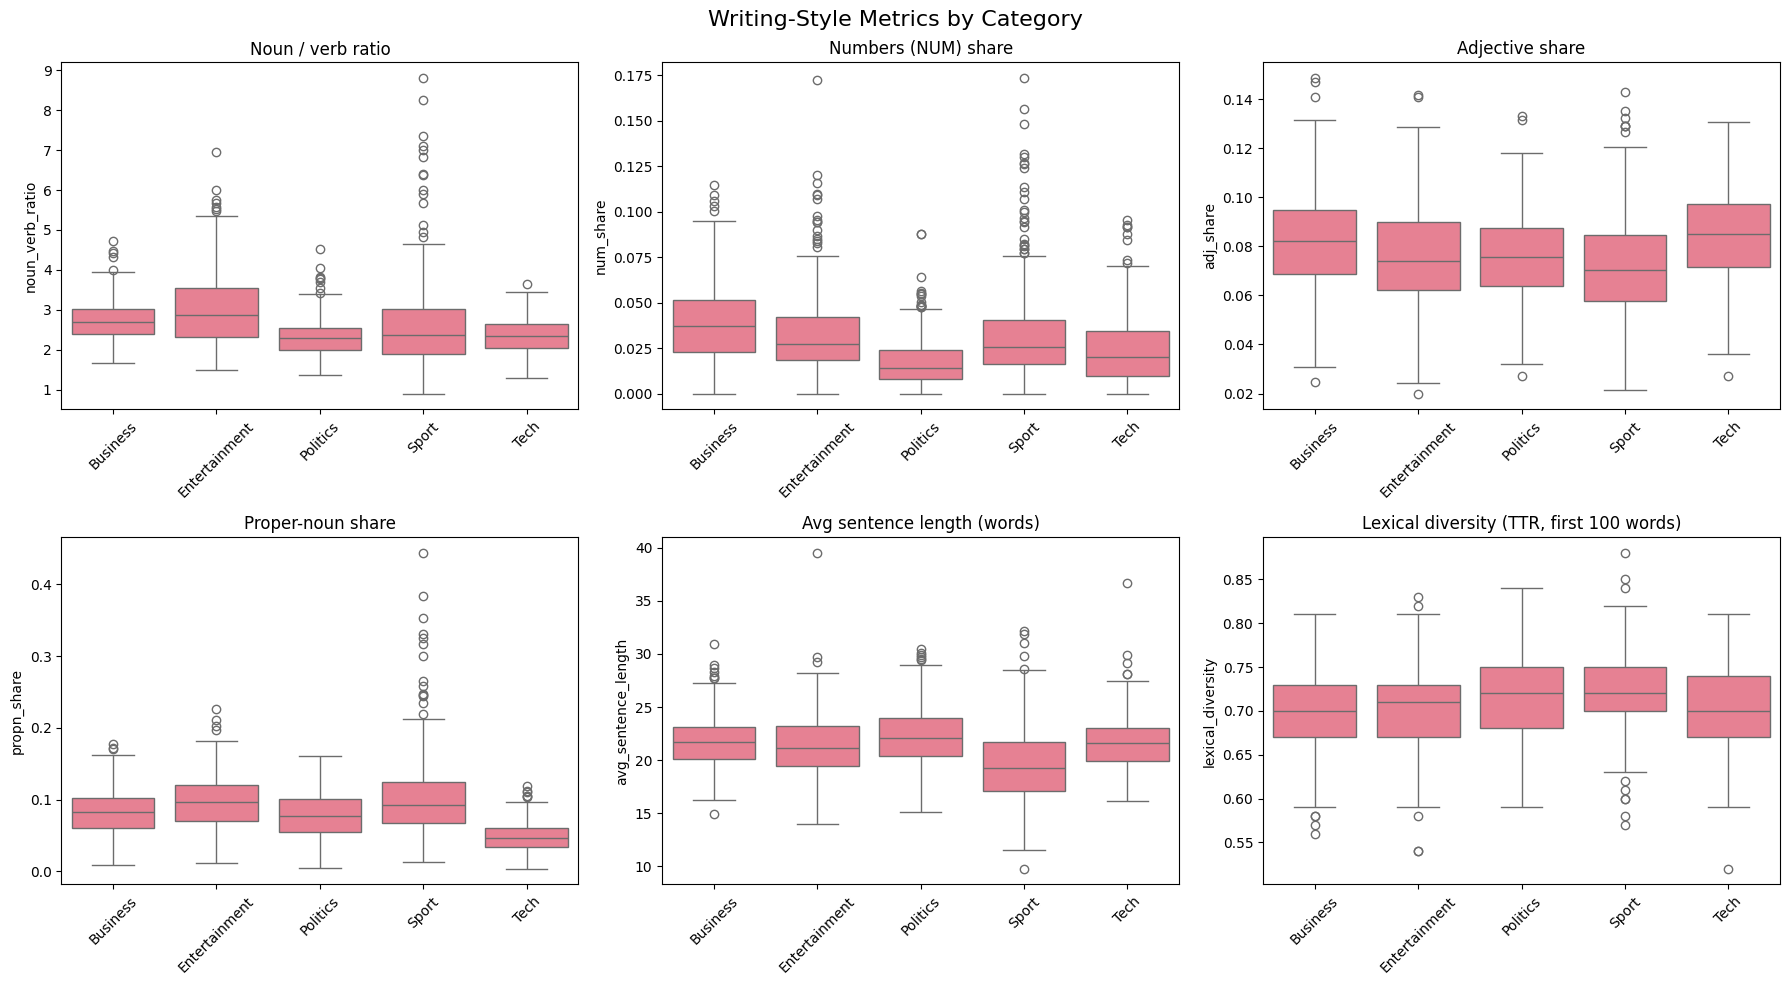

In [ ]:
# 💡 STUDENT TASK: noun/verb ratio, numbers, adjectives + writing-style metrics
style_df = pd.DataFrame([r['style'] for r in spacy_results])
style_df['category'] = df['category'].values

style_metrics = ['noun_verb_ratio', 'noun_share', 'propn_share', 'verb_share', 'adj_share',
                 'num_share', 'avg_sentence_length', 'lexical_diversity']
style_by_category = style_df.groupby('category')[style_metrics].mean()
print("✍️ WRITING STYLE BY CATEGORY (means)")
print(style_by_category.round(3))

plot_metrics = [('noun_verb_ratio', 'Noun / verb ratio'),
                ('num_share', 'Numbers (NUM) share'),
                ('adj_share', 'Adjective share'),
                ('propn_share', 'Proper-noun share'),
                ('avg_sentence_length', 'Avg sentence length (words)'),
                ('lexical_diversity', 'Lexical diversity (TTR, first 100 words)')]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (col, title) in zip(axes.ravel(), plot_metrics):
    sns.boxplot(data=style_df, x='category', y=col, order=categories, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
plt.suptitle('Writing-Style Metrics by Category', fontsize=16)
plt.tight_layout()
save_figure('m4_style_metrics', fig)
plt.show()

### 🔍 POS & Writing-Style Findings (my interpretation)

**1. Proper nouns (NNP/NNPS):** The highest share is in Sport (NNP 0.103), followed by Entertainment (0.099), Business (0.082) and Politics (0.078); Tech is lowest (0.049). NNPS is close to zero everywhere (max 0.001, Politics). However, lowercasing removes capitalization clues, making proper-noun tagging less reliable because names of people, places, and organizations may be mistaken for common nouns.

**2. Action verbs (VB, VBD, VBG):** Politics uses the most verbs (VB+VBD+VBG = 0.115), and Entertainment the fewest (0.096, practically tied with Business). Sport: 0.104, Tech: 0.099, Business: 0.096. Politics also has the highest past-tense share (VBD 0.0469), just ahead of Sport (0.0465) and Entertainment (0.0462). With spaCy's universal VERB tag, the order is Politics (0.137), Tech (0.134), Sport (0.126), Business (0.125), Entertainment (0.121). This doesn't fully fit the hypothesis that sports articles use more action verbs because Politics (on both measures) and Tech (on the universal VERB measure) have higher overall verb shares, and Sport's past-tense share (VBD 0.0465) is almost the same as Politics (0.0469), so past tense does not clearly support the idea that sports reports focus more on events that have already happened.

**3. Adjectives (JJ):** Tech has the highest adjective share (JJ 0.076; universal ADJ 0.084), and Entertainment the lowest (JJ 0.068). Entertainment has the most superlatives (JJS 0.005), Tech the most comparatives (JJR 0.006). Possibly because technology articles often describe and compare products, features, and performance, while entertainment articles focus more on people, events, and works such as films and music.

**4. Numbers (CD):** Business uses the most numbers (CD 0.039), followed by Entertainment (0.034), Sport (0.033), Tech (0.025) and Politics (0.018, the lowest). The hypothesis that business articles have more numbers is supported because Business has the highest proportion of numerical expressions, which may reflect its frequent reporting of prices, financial figures, market changes, and economic data.

**Writing style:** The noun/verb ratio ranges from 2.34 (Politics) to 3.04 (Entertainment). Average sentence length is longest in Politics (22.3 words) and shortest in Sport (19.6). Lexical diversity is highest in Sport (0.725) and lowest in Business (0.698).

**Usefulness for classification:** Based on the reported category differences, the number share (CD) looks like the most distinctive style feature because Business has the highest proportion of numbers, while Politics has the lowest (0.039 versus 0.018). This difference could help a classifier distinguish financial reporting from political news, and the boxplot supports it: the Politics box lies lower than the other categories, although it overlaps with the lower part of the Tech box.

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [ ]:
# Apply syntactic analysis to ALL articles
# (extract_syntactic_features() now lives in the spaCy pass cell; results come from that single pass)
print("🌳 Performing syntactic analysis...")

syntactic_results = []
for row, res in zip(df.itertuples(index=False), spacy_results):
    features = dict(res['syntax'])
    features['category'] = row.category
    features['article_id'] = row.article_id
    syntactic_results.append(features)

print(f"✅ Syntactic analysis complete for {len(syntactic_results)} articles!")

# Display results for the first 5 articles (same overview as the starter)
for i, result in enumerate(syntactic_results[:5]):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Avg / max tree depth: {result['avg_tree_depth']:.1f} / {result['max_tree_depth']}")
    print(f"  Passive sentences: {result['passive_sentence_share']:.0%}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")
    print(f"  Subjects: {result['subjects'][:3]}...")
    print(f"  Objects: {result['objects'][:3]}...")
    print(f"  SVO triples: {result['svo_triples'][:2]}...")

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete for 1432 articles!

📰 Article 1 (Business):
  Sentences: 14
  Tokens: 340
  Avg / max tree depth: 6.2 / 10
  Passive sentences: 7%
  Noun phrases: ['-', 'boss', 'defence lawyers']...
  Subjects: ['-', 'boss', 'cooper']...
  Objects: ['lawyers', 'ebbers', 'battery']...
  SVO triples: [('-', 'launch', 'defence lawyers'), ('boss', 'launch', 'defence lawyers')]...

📰 Article 2 (Business):
  Sentences: 16
  Tokens: 364
  Avg / max tree depth: 5.6 / 9
  Passive sentences: 12%
  Noun phrases: ['german business confidence', 'german business confidence', 'february']...
  Subjects: ['confidence', 'ifo', 'index']...
  Objects: ['confidence', 'february', 'hopes']...
  SVO triples: [('business confidence', 'slide', 'business confidence'), ('economy', 'call', 'dip')]...

📰 Article 3 (Business):
  Sentences: 23
  Tokens: 581
  Avg / max tree depth: 6.6 / 13
  Passive sentences: 26%
  Noun phrases: ['bbc poll', 'economic gloom citizens',

In [ ]:
# Visualize dependency parsing for ONE short sentence (a whole article is unreadable)
from spacy import displacy


def pick_short_sentence(texts, min_tokens=8, max_tokens=14):
    """Return the first sentence from the texts with a readable length (8-14 words)."""
    for text in texts:
        for sent in nlp(text[:1500]).sents:
            if min_tokens <= len(_content_tokens(sent)) <= max_tokens:
                return sent.text.strip()
    return "the company was bought by google."   # fallback


sample_sentence = pick_short_sentence(df['full_text'].head(20))
print(f"📝 Sample sentence: {sample_sentence}")
doc = nlp(sample_sentence)
render_options = {'compact': True, 'distance': 110}

print("\n🌳 Dependency Parse Visualization:")
try:
    displacy.render(doc, style="dep", jupyter=True, options=render_options)
    svg = displacy.render(doc, style="dep", jupyter=False, options=render_options)
    (FIG_DIR / 'm5_dependency_parse.svg').write_text(svg, encoding='utf-8')
    print("🖼️ Figure saved: m5_dependency_parse.svg")
except Exception as e:
    print(f"(displacy not available: {e})")

# Text version of the same parse (always printed – useful for your explanation)
print("\n🔗 Dependency Relations:")
for token in doc:
    if not token.is_space and not token.is_punct:
        print(f"  {token.text:<14} --{token.dep_:>10}--> {token.head.text:<14} ({spacy.explain(token.dep_)})")

📝 Sample sentence: mr ebbers has pleaded not guilty to charges of fraud and conspiracy.

🌳 Dependency Parse Visualization:


🖼️ Figure saved: m5_dependency_parse.svg

🔗 Dependency Relations:
  mr             --  compound--> ebbers         (compound)
  ebbers         --     nsubj--> pleaded        (nominal subject)
  has            --       aux--> pleaded        (auxiliary)
  pleaded        --      ROOT--> pleaded        (root)
  not            --       neg--> guilty         (negation modifier)
  guilty         --     acomp--> pleaded        (adjectival complement)
  to             --      prep--> guilty         (prepositional modifier)
  charges        --      pobj--> to             (object of preposition)
  of             --      prep--> charges        (prepositional modifier)
  fraud          --      pobj--> of             (object of preposition)
  and            --        cc--> fraud          (coordinating conjunction)
  conspiracy     --      conj--> fraud          (conjunct)


🧩 SYNTACTIC COMPLEXITY BY CATEGORY (means)
               avg_sentence_length  avg_tree_depth  max_tree_depth  \
category                                                             
Business                    21.749           6.287          10.510   
Entertainment               21.348           6.058          10.176   
Politics                    22.272           6.448          11.459   
Sport                       19.579           5.473           9.374   
Tech                        21.712           6.388          11.566   

               passive_sentence_share  noun_phrases_per_sentence  \
category                                                           
Business                        0.193                      5.616   
Entertainment                   0.265                      5.622   
Politics                        0.270                      5.968   
Sport                           0.151                      5.175   
Tech                            0.237                     

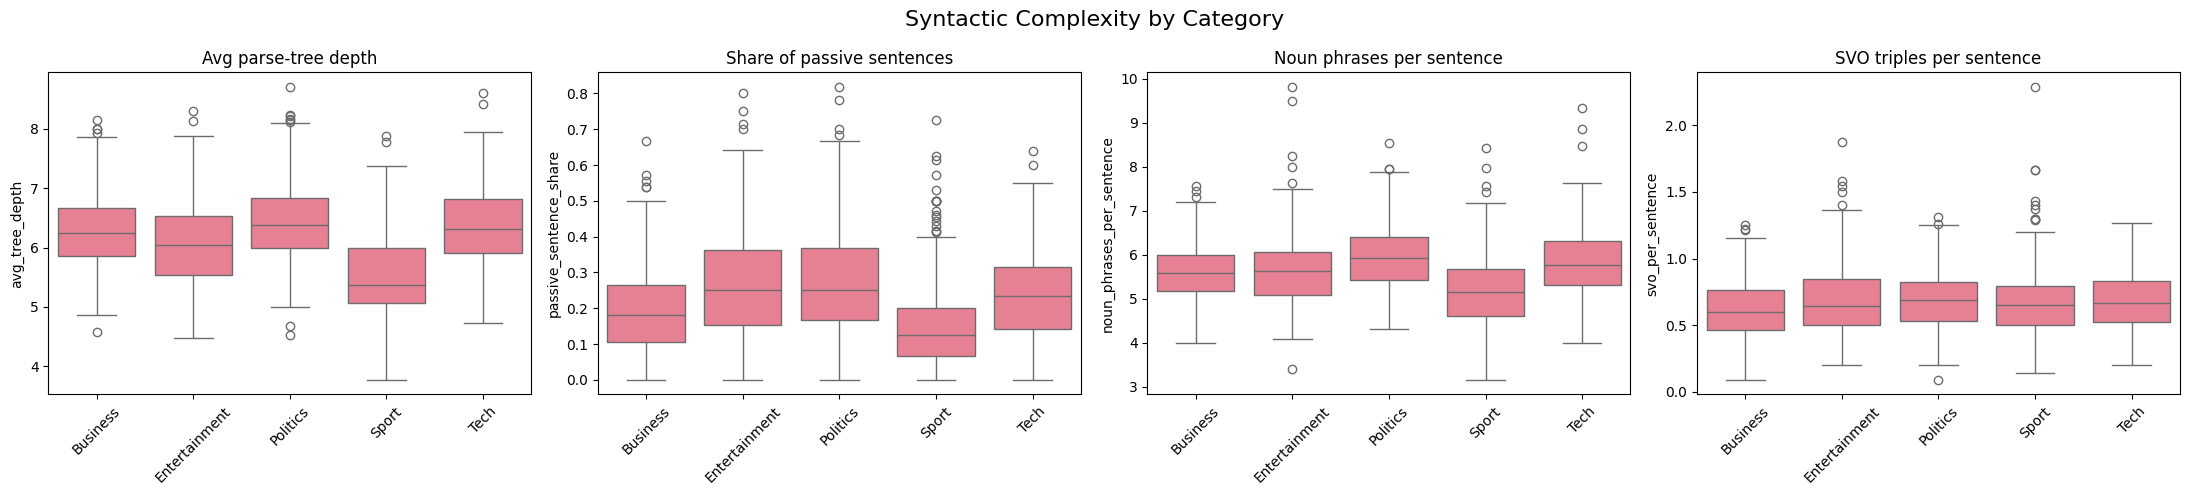

In [ ]:
# 💡 STUDENT TASK: compare syntactic complexity across categories
syntax_df = pd.DataFrame([{
    'article_id': r['article_id'],
    'category': r['category'],
    'avg_sentence_length': s['avg_sentence_length'],
    'avg_tree_depth': r['avg_tree_depth'],
    'max_tree_depth': r['max_tree_depth'],
    'passive_sentence_share': r['passive_sentence_share'],
    'noun_phrases_per_sentence': len(r['noun_phrases']) / max(r['num_sentences'], 1),
    'svo_per_sentence': len(r['svo_triples']) / max(r['num_sentences'], 1),
} for r, s in zip(syntactic_results, style_df.to_dict('records'))])

complexity_cols = ['avg_sentence_length', 'avg_tree_depth', 'max_tree_depth',
                   'passive_sentence_share', 'noun_phrases_per_sentence', 'svo_per_sentence']
print("🧩 SYNTACTIC COMPLEXITY BY CATEGORY (means)")
print(syntax_df.groupby('category')[complexity_cols].mean().round(3))

plot_cols = [('avg_tree_depth', 'Avg parse-tree depth'),
             ('passive_sentence_share', 'Share of passive sentences'),
             ('noun_phrases_per_sentence', 'Noun phrases per sentence'),
             ('svo_per_sentence', 'SVO triples per sentence')]
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (col, title) in zip(axes, plot_cols):
    sns.boxplot(data=syntax_df, x='category', y=col, order=categories, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
plt.suptitle('Syntactic Complexity by Category', fontsize=16)
plt.tight_layout()
save_figure('m5_syntactic_complexity', fig)
plt.show()

In [ ]:
# 💡 STUDENT TASK: extract action patterns – who did what to whom
PRONOUNS = {'i', 'you', 'he', 'she', 'it', 'we', 'they', 'who', 'which', 'that',
            'this', 'there', 'what', 'one', 'me', 'him', 'her', 'us', 'them'}

svo_df = pd.DataFrame([{'article_id': r['article_id'], 'category': r['category'],
                        'agent': a, 'action': v, 'patient': p}
                       for r in syntactic_results for (a, v, p) in r['svo_triples']])

if svo_df.empty:
    print("⚠️ No SVO triples found.")
else:
    print(f"🎭 Total SVO triples: {len(svo_df)}")
    print(f"   Agents that are pronouns (he/it/they…): {svo_df['agent'].isin(PRONOUNS).mean():.0%}")
    print("\nTriples per category:")
    print(svo_df['category'].value_counts())

    named = svo_df[~svo_df['agent'].isin(PRONOUNS)]   # 'who' = a real noun, not a pronoun
    for cat in categories:
        sub = named[named['category'] == cat]
        if sub.empty:
            continue
        print(f"\n📰 {cat.upper()}")
        print(f"  Top actions: {', '.join(sub['action'].value_counts().head(6).index)}")
        print(f"  Top agents:  {', '.join(sub['agent'].value_counts().head(6).index)}")
        for _, t in sub.sample(min(3, len(sub)), random_state=RANDOM_STATE).iterrows():
            print(f"     → {t['agent']}  [{t['action']}]  {t['patient']}")

    save_object(svo_df, 'svo_triples')

🎭 Total SVO triples: 17230
   Agents that are pronouns (he/it/they…): 38%

Triples per category:
category
Sport            3987
Politics         3659
Tech             3597
Business         3169
Entertainment    2818
Name: count, dtype: int64

📰 BUSINESS
  Top actions: have, tell, take, hit, make, face
  Top agents:  government, company, firm, firms, economy, analysts
     → timewarner  [project]  earnings growth
     → figures  [top]  analysts expectations
     → result job creation  [become]  issue

📰 ENTERTAINMENT
  Top actions: win, take, include, have, play, make
  Top agents:  film, people, band, aviator, films, bbc
     → producers morgan creek  [shelve]  schrader version
     → story  [feature]  dan ashcroft
     → charles  [love]  company collection

📰 POLITICS
  Top actions: tell, have, take, make, give, win
  Top agents:  government, mr blair, people, labour, party, tories
     → bit  [go]  miss
     → threshold gordon brown  [hit]  time buyers
     → policies  [cause]  failu

🔗 TOP 5 DEPENDENCY RELATIONS PER CATEGORY
  Business       prep (0.115), pobj (0.109), det (0.094), compound (0.092), nsubj (0.079)
  Entertainment  prep (0.109), compound (0.108), pobj (0.106), det (0.095), nsubj (0.078)
  Politics       prep (0.102), det (0.098), pobj (0.098), nsubj (0.089), compound (0.083)
  Sport          prep (0.107), pobj (0.096), det (0.091), nsubj (0.091), compound (0.086)
  Tech           prep (0.106), pobj (0.100), det (0.090), nsubj (0.084), compound (0.076)

📈 MOST OVER-REPRESENTED RELATIONS PER CATEGORY (vs. average across categories)
  Business       nmod (+75%, modifier of nominal), nummod (+30%, numeric modifier), mark (+12%, marker)
  Entertainment  appos (+36%, appositional modifier), compound (+21%, compound), nsubjpass (+19%, nominal subject (passive))
  Politics       ccomp (+36%, clausal complement), neg (+29%, negation modifier), acl (+21%, clausal modifier of noun (adjectival clause))
  Sport          npadvmod (+39%, noun phrase as adverbial mo

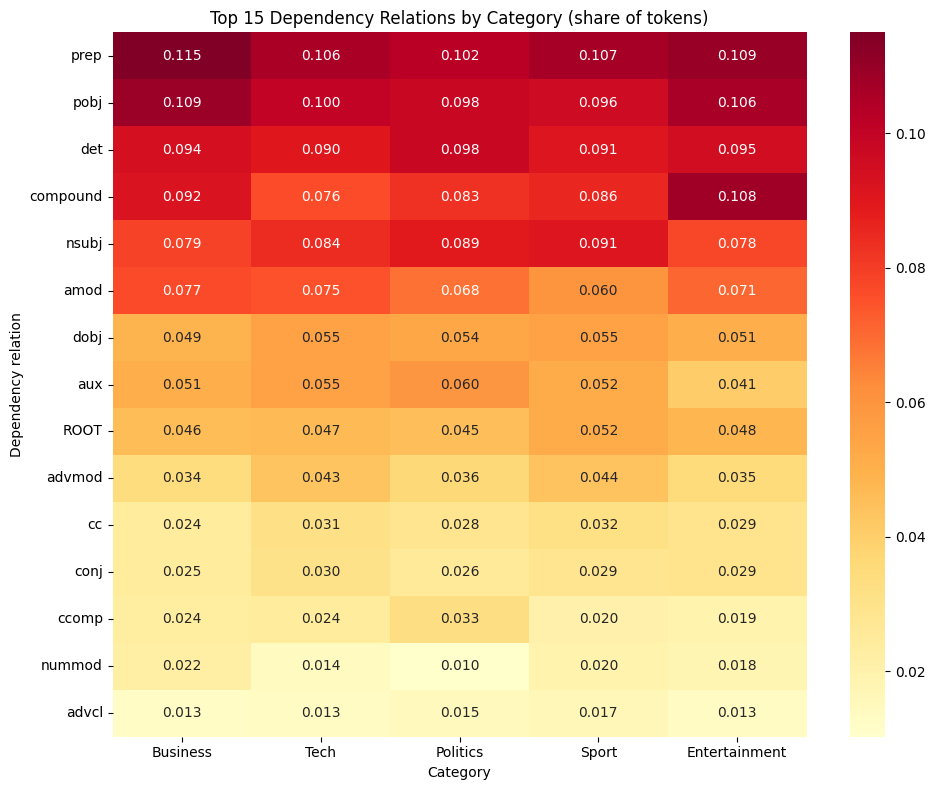

In [ ]:
# 💡 STUDENT TASK: most common dependency relations per category
dep_totals = defaultdict(Counter)
for r in syntactic_results:
    dep_totals[r['category']].update(r['dependency_counts'])

dep_counts_df = pd.DataFrame(dep_totals).fillna(0).T                        # categories x relations
dep_share = dep_counts_df.div(dep_counts_df.sum(axis=1), axis=0)           # proportions per category

print("🔗 TOP 5 DEPENDENCY RELATIONS PER CATEGORY")
for cat in categories:
    top5 = dep_share.loc[cat].nlargest(5)
    print(f"  {cat:<14} " + ', '.join(f"{d} ({v:.3f})" for d, v in top5.items()))

# Relations that are relatively MORE frequent in a category than on average (ignoring rare ones)
common = dep_share.columns[dep_share.mean() > 0.005]
relative = (dep_share[common] - dep_share[common].mean()) / dep_share[common].mean()
print("\n📈 MOST OVER-REPRESENTED RELATIONS PER CATEGORY (vs. average across categories)")
for cat in categories:
    top3 = relative.loc[cat].nlargest(3)
    print(f"  {cat:<14} " + ', '.join(f"{d} (+{v:.0%}, {spacy.explain(d)})" for d, v in top3.items()))

top_deps = dep_share.mean().nlargest(15).index
plt.figure(figsize=(10, 8))
sns.heatmap(dep_share[top_deps].T, annot=True, fmt='.3f', cmap='YlOrRd')
plt.title('Top 15 Dependency Relations by Category (share of tokens)')
plt.xlabel('Category')
plt.ylabel('Dependency relation')
plt.tight_layout()
save_figure('m5_dependency_heatmap')
plt.show()

In [ ]:
# Optional STUDENT TASK: create syntax/style features for classification (used again in Module 7)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold

SYNTAX_FEATURE_COLS = ['avg_sentence_length', 'avg_tree_depth', 'max_tree_depth',
                       'passive_sentence_share', 'noun_phrases_per_sentence', 'svo_per_sentence']
STYLE_FEATURE_COLS = ['noun_share', 'propn_share', 'verb_share', 'adj_share',
                      'adv_share', 'num_share', 'noun_verb_ratio', 'lexical_diversity']

linguistic_features = pd.concat([syntax_df[['article_id'] + SYNTAX_FEATURE_COLS].reset_index(drop=True),
                                 style_df[STYLE_FEATURE_COLS].reset_index(drop=True)], axis=1)
save_object(linguistic_features, 'linguistic_features')

# How much can grammar ALONE tell us about the category? (no words at all)
X_ling = linguistic_features[SYNTAX_FEATURE_COLS + STYLE_FEATURE_COLS].values
ling_pipe = Pipeline([('scale', StandardScaler()),
                      ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ling_scores = cross_val_score(ling_pipe, X_ling, df['category'], cv=cv, scoring='accuracy')
majority_baseline = df['category'].value_counts(normalize=True).max()

print(f"🧪 {X_ling.shape[1]} syntax/style features per article")
print(f"   Accuracy with syntax/style features only: {ling_scores.mean():.3f} ± {ling_scores.std():.3f}")
print(f"   Majority-class baseline (always guess the largest class): {majority_baseline:.3f}")
print(f"   For comparison – best TF-IDF setting (Module 3): {tfidf_results.loc[0, 'cv_accuracy']:.3f}")

💾 Saved linguistic_features_full.pkl
🧪 14 syntax/style features per article
   Accuracy with syntax/style features only: 0.560 ± 0.019
   Majority-class baseline (always guess the largest class): 0.239
   For comparison – best TF-IDF setting (Module 3): 0.975


### 🔍 Syntax & Semantics Findings (my interpretation)

**Syntactic complexity:** The deepest parse trees are in Politics (avg depth 6.45), the shallowest in Sport (5.47). Tech has the highest maximum depth (11.57). Politics uses the most passive voice (27.0% of sentences) and Sport the least (15.1%); Entertainment 26.5%, Tech 23.7%, Business 19.3%. Politics also has the most noun phrases per sentence (5.97), Sport the fewest (5.18). This may be because political articles often describe complex policies, government decisions, and statements involving multiple people or organizations, while sports articles tend to use more direct language to report match events and results.

**Who did what to whom:** 38% of agents are pronouns (17,230 triples in total), which limits the analysis because pronouns such as "he," "she," and "they" do not clearly identify the people or organizations involved without additional context.
Typical actions per category: Business have, tell, take, hit, make, face; Politics tell, have, take, make, give, win; Sport have, win, take, tell, make, play (Entertainment: win, take, include, have, play, make; Tech: have, use, make, offer, take, tell).
An interesting extracted triple was "woodsman — win — satyajit ray award", which shows how subject–verb–object extraction can capture meaningful relationships between a film, an action, and an award.
An incorrect triple was "fights — become — man", probably because the dependency parser may have misidentified the subject, verb, or object: the headline ("moya fights back…") is joined to the first sentence without punctuation, so the headline verb "fights" was parsed as a noun and treated as the subject. The same pattern appears in other articles ("lifts", "tops", "pitches", and "launches" in the WorldCom article: "- launch defence lawyers").

**Dependency relations:** The top relations are similar in all categories (prep, pobj, det, compound, nsubj – the same five everywhere), because all five categories use the same basic grammatical structures, including prepositional phrases, noun phrases, determiners, and subjects.
Over-represented relations: nmod (+75%) and nummod (+30%) in Business; appos (+36%), compound (+21%) and nsubjpass (+19%) in Entertainment; ccomp (+36%), neg (+29%) and acl (+21%) in Politics; npadvmod (+39%), appos (+36%) and neg (+34%) in Sport; relcl (+29%), acomp (+17%) and xcomp (+14%) in Tech, which reflects differences in writing style and subject matter. Business articles frequently include numerical and descriptive information, Entertainment articles identify people or works with additional descriptions, Politics articles use more reported statements and negations, Sport articles include time-related expressions, descriptions attached to names and negations, and Tech articles use relative clauses and adjective or verb complements.

**Syntax features for classification:** Syntax/style features alone reached 56.0% (± 1.9) accuracy vs. 23.9% majority baseline and 97.5% for TF-IDF. This means grammar carries some information about the topic, and combining it with TF-IDF in Module 7 may improve classification by combining lexical information from word frequencies with grammatical patterns and writing-style features.

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [ ]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()


def label_from_compound(compound, threshold=0.05):
    """VADER's standard thresholds: >= 0.05 positive, <= -0.05 negative, otherwise neutral."""
    if compound >= threshold:
        return 'positive'
    if compound <= -threshold:
        return 'negative'
    return 'neutral'


def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

    VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos / neu / neg: share of positive / neutral / negative words (0 to 1)
    plus 'sentiment_label' (positive / neutral / negative).
    """
    if not text or pd.isna(text):
        return {'compound': 0.0, 'pos': 0.0, 'neu': 1.0, 'neg': 0.0, 'sentiment_label': 'neutral'}
    scores = sia.polarity_scores(str(text))
    scores['sentiment_label'] = label_from_compound(scores['compound'])
    return scores


def analyze_sentence_sentiment(text):
    """Score every sentence separately and average – avoids the 'saturation' of long texts near ±1."""
    sentences = [s for s in sent_tokenize(str(text)) if s.strip()] if text else []
    if not sentences:
        return {'avg_sentence_compound': 0.0, 'share_pos_sentences': 0.0, 'share_neg_sentences': 0.0}
    compounds = [sia.polarity_scores(s)['compound'] for s in sentences]
    return {'avg_sentence_compound': float(np.mean(compounds)),
            'share_pos_sentences': float(np.mean([c >= 0.05 for c in compounds])),
            'share_neg_sentences': float(np.mean([c <= -0.05 for c in compounds]))}


def get_lead(text):
    """The 'lead' = first sentence (in BBC data it also contains the headline)."""
    sentences = sent_tokenize(str(text)) if text else []
    return sentences[0] if sentences else ''


def run_sentiment(data):
    """Sentiment for every article: lead, whole article, and sentence average."""
    rows = []
    for row in data.itertuples(index=False):
        lead_s = analyze_sentiment(get_lead(row.full_text))
        full_s = analyze_sentiment(row.full_text)
        sent_s = analyze_sentence_sentiment(row.full_text)
        rows.append({
            'article_id': row.article_id,
            'category': row.category,
            'lead_sentiment': lead_s['compound'],          # replaces the starter's title_sentiment
            'lead_label': lead_s['sentiment_label'],
            'full_sentiment': full_s['compound'],          # whole-article VADER score (starter)
            'full_label': full_s['sentiment_label'],
            'avg_sentence_sentiment': sent_s['avg_sentence_compound'],
            'sentence_label': label_from_compound(sent_s['avg_sentence_compound']),
            'share_pos_sentences': sent_s['share_pos_sentences'],
            'share_neg_sentences': sent_s['share_neg_sentences'],
            'pos_score': full_s['pos'],
            'neu_score': full_s['neu'],
            'neg_score': full_s['neg'],
        })
    return pd.DataFrame(rows)


print("😊 Analyzing sentiment...")
sentiment_df = cached('sentiment_results', lambda: run_sentiment(df))

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")
print("\n📝 Sample sentiment results:")
print(sentiment_df[['category', 'lead_sentiment', 'full_sentiment', 'avg_sentence_sentiment', 'full_label']].head())

😊 Analyzing sentiment...
⏱️ 'sentiment_results' computed in 17.6s
💾 Saved sentiment_results_full.pkl
✅ Sentiment analysis complete!
📊 Analyzed 1432 articles

📝 Sample sentiment results:
   category  lead_sentiment  full_sentiment  avg_sentence_sentiment full_label
0  Business         -0.6705         -0.9701               -0.225483   negative
1  Business          0.8555          0.7623                0.105971   positive
2  Business         -0.7650         -0.9318               -0.085245   negative
3      Tech         -0.0920          0.9554                0.124368   positive
4  Business         -0.2263         -0.9486               -0.086288   negative


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         avg_sentence_sentiment  \
                        mean     std     min     max                   mean   
category                                                                      
Business              0.2394  0.8355 -0.9985  0.9995                 0.0544   
Entertainment         0.5796  0.6964 -0.9978  0.9999                 0.1924   
Politics              0.0386  0.8811 -0.9984  0.9999                 0.0186   
Sport                 0.5447  0.7236 -0.9967  0.9996                 0.1429   
Tech                  0.5324  0.7457 -0.9991  0.9993                 0.0945   

                      pos_score neu_score neg_score  
                  std      mean      mean      mean  
category                                             
Business       0.1894    0.0920    0.8373    0.0706  
Entertainment  0.2441    0.1352    0.8099    0.0549  
Politics       0.1737    0.

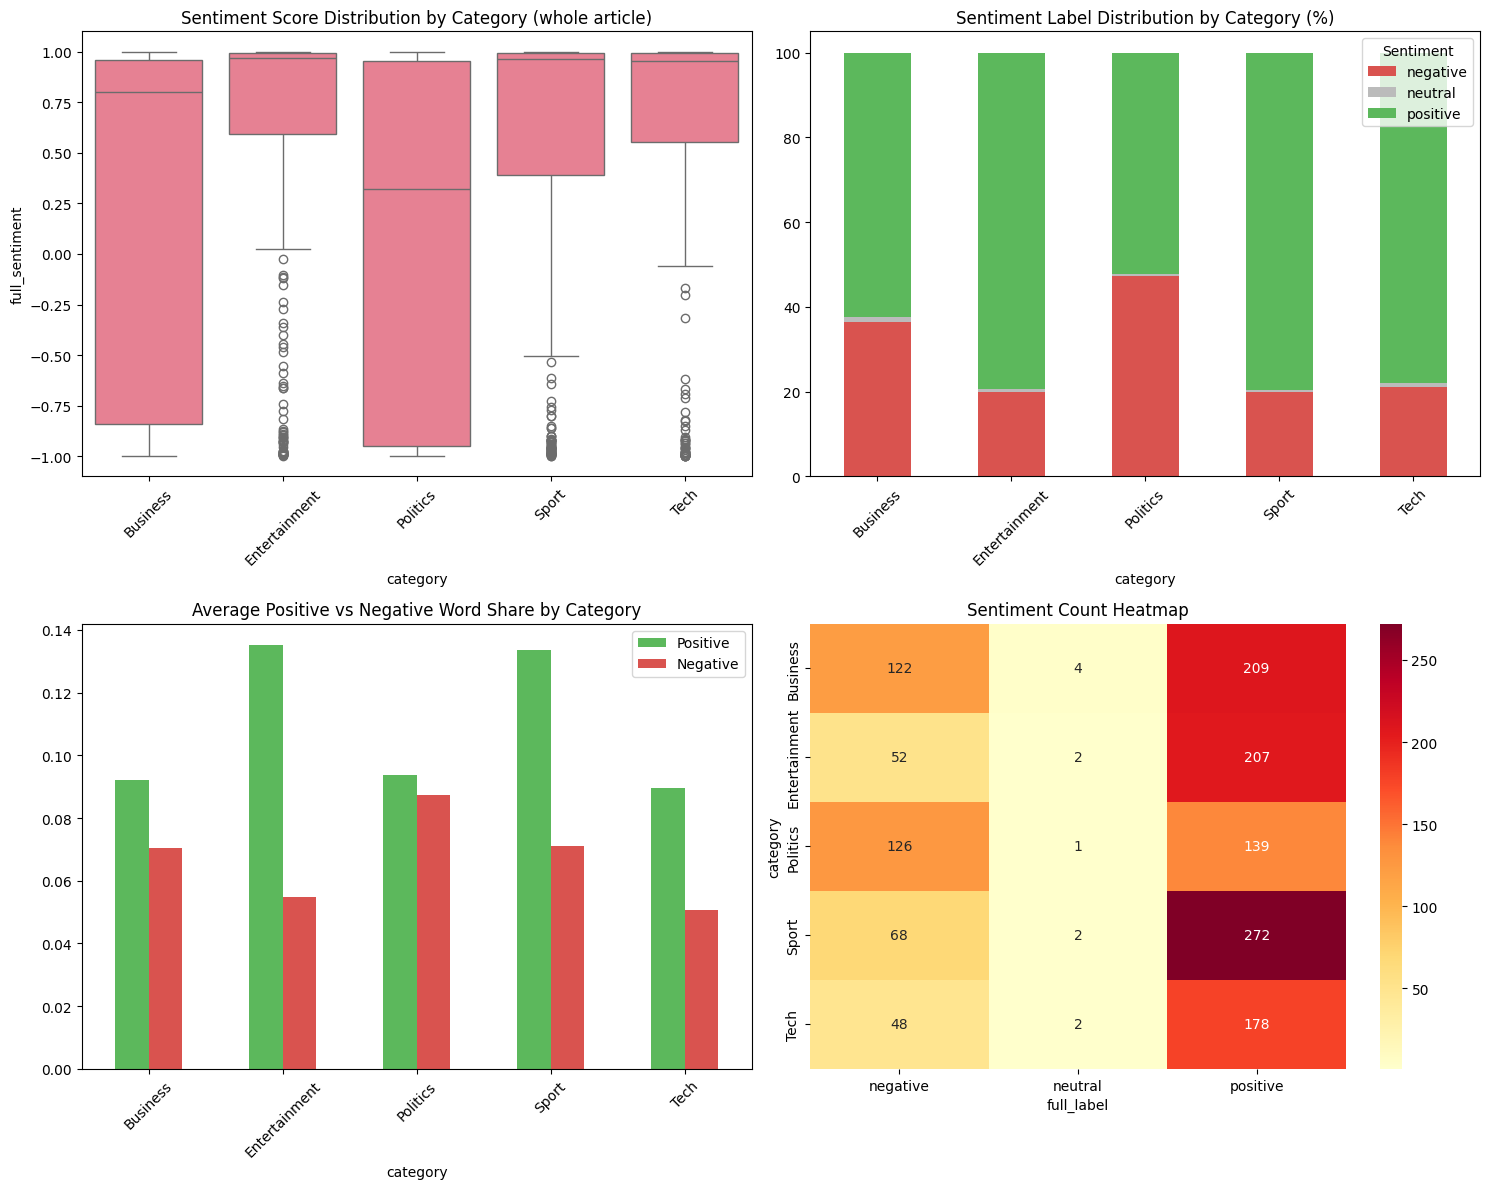

In [ ]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'avg_sentence_sentiment': ['mean', 'std'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)
print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category (fixed label order -> consistent colours)
label_order = ['negative', 'neutral', 'positive']
sentiment_dist = (sentiment_df.groupby(['category', 'full_label']).size()
                  .unstack(fill_value=0).reindex(columns=label_order, fill_value=0))
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100
print("\n📊 Sentiment distribution (%) by category (whole-article score):")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', order=categories, ax=axes[0, 0])
axes[0, 0].set_title('Sentiment Score Distribution by Category (whole article)')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0, 1], stacked=True, color=['#d9534f', '#bbbbbb', '#5cb85c'])
axes[0, 1].set_title('Sentiment Label Distribution by Category (%)')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1, 0], color=['#5cb85c', '#d9534f'])
axes[1, 0].set_title('Average Positive vs Negative Word Share by Category')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = (sentiment_df.pivot_table(values='full_sentiment', index='category',
                                            columns='full_label', aggfunc='count', fill_value=0)
                   .reindex(columns=label_order, fill_value=0).astype(int))
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1, 1], cmap='YlOrRd')
axes[1, 1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
save_figure('m6_sentiment_overview', fig)
plt.show()

📏 SATURATION CHECK (|compound| > 0.9)
   Whole-article score:    70.4% of articles
   Sentence-average score: 0.0% of articles

🔁 AGREEMENT BETWEEN MEASURES
   Lead label = whole-article label:    61.0%
   Whole-article = sentence-avg label:  83.5%
   Correlation lead vs whole article:   0.496

Whole-article label (rows) vs sentence-average label (columns):
sentence_label  negative  neutral  positive
full_label                                 
negative             315       93         8
neutral                0        9         2
positive              12      121       872

📊 Sentence-average label distribution (%) by category:
sentence_label  negative  neutral  positive
category                                   
Business            28.4     19.7      51.9
Entertainment       15.7      9.2      75.1
Politics            36.5     20.3      43.2
Sport               16.4     14.0      69.6
Tech                16.7     13.6      69.7
🖼️ Figure saved: m6_sentiment_saturation.png


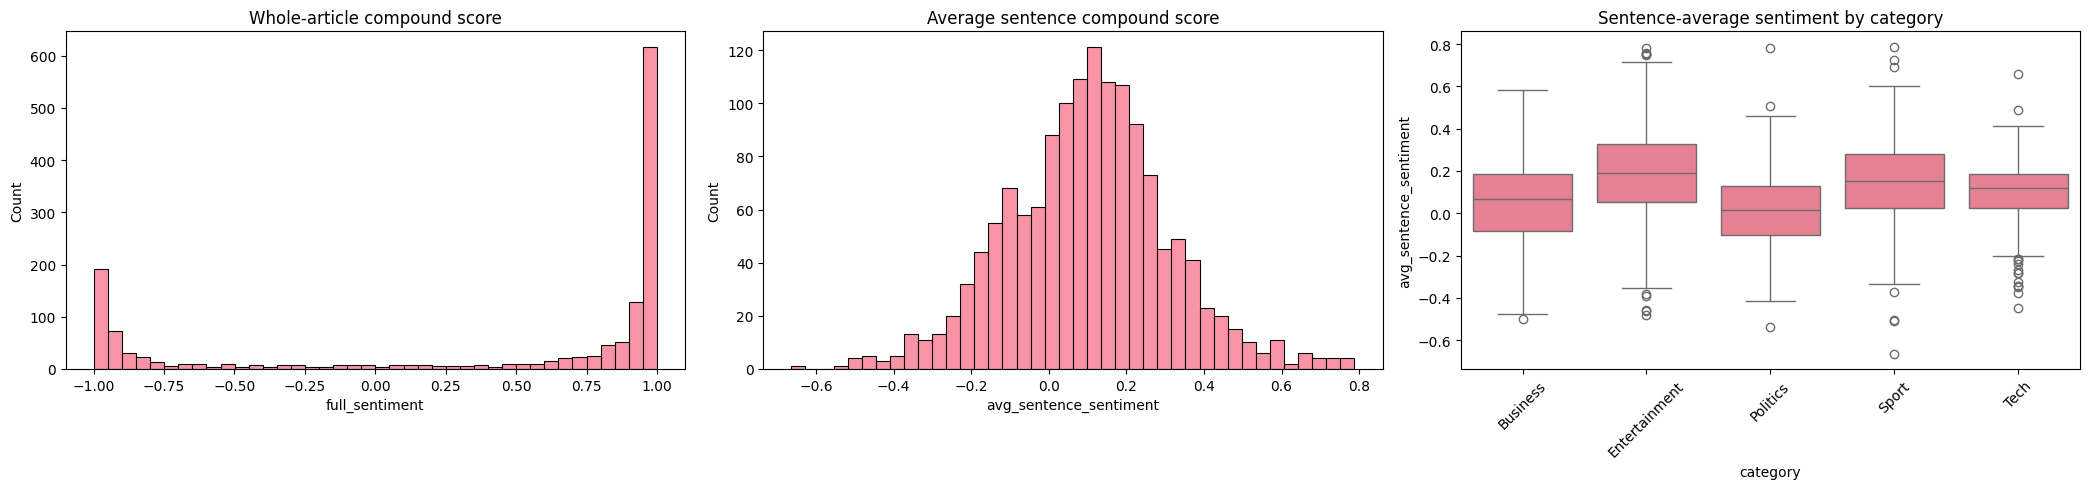

In [ ]:
# 💡 STUDENT TASK: title (lead) vs content sentiment + does VADER saturate on long articles?
sat_full = (sentiment_df['full_sentiment'].abs() > 0.9).mean()
sat_sent = (sentiment_df['avg_sentence_sentiment'].abs() > 0.9).mean()
print("📏 SATURATION CHECK (|compound| > 0.9)")
print(f"   Whole-article score:    {sat_full:.1%} of articles")
print(f"   Sentence-average score: {sat_sent:.1%} of articles")

print("\n🔁 AGREEMENT BETWEEN MEASURES")
print(f"   Lead label = whole-article label:    {(sentiment_df['lead_label'] == sentiment_df['full_label']).mean():.1%}")
print(f"   Whole-article = sentence-avg label:  {(sentiment_df['full_label'] == sentiment_df['sentence_label']).mean():.1%}")
print(f"   Correlation lead vs whole article:   {sentiment_df['lead_sentiment'].corr(sentiment_df['full_sentiment']):.3f}")
print("\nWhole-article label (rows) vs sentence-average label (columns):")
print(pd.crosstab(sentiment_df['full_label'], sentiment_df['sentence_label']))

print("\n📊 Sentence-average label distribution (%) by category:")
print((pd.crosstab(sentiment_df['category'], sentiment_df['sentence_label'], normalize='index') * 100).round(1))

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
sns.histplot(sentiment_df['full_sentiment'], bins=40, ax=axes[0])
axes[0].set_title('Whole-article compound score')
sns.histplot(sentiment_df['avg_sentence_sentiment'], bins=40, ax=axes[1])
axes[1].set_title('Average sentence compound score')
sns.boxplot(data=sentiment_df, x='category', y='avg_sentence_sentiment', order=categories, ax=axes[2])
axes[2].set_title('Sentence-average sentiment by category')
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
save_figure('m6_sentiment_saturation', fig)
plt.show()

In [ ]:
# Sanity check: most positive / negative articles + which words drive VADER's scores
def show_extremes(score_col='avg_sentence_sentiment', n=3):
    """Print the n most positive and most negative articles for a sentiment column."""
    for title, subset in [('😊 MOST POSITIVE', sentiment_df.nlargest(n, score_col)),
                          ('😞 MOST NEGATIVE', sentiment_df.nsmallest(n, score_col))]:
        print(f"\n{title} (by {score_col})")
        for _, r in subset.iterrows():
            text = df.loc[df['article_id'] == r['article_id'], 'content'].iloc[0]
            print(f"  [{r['category']} | id={r['article_id']}] sentence-avg={r['avg_sentence_sentiment']:.3f}, "
                  f"whole={r['full_sentiment']:.3f}")
            print(f"     {text[:200]}...")


def vader_word_contributions(texts):
    """Sum of VADER lexicon values per word over a set of texts (which words push scores up/down)."""
    totals = Counter()
    for t in texts:
        for w in re.findall(r"[a-z']+", str(t).lower()):
            if w in sia.lexicon:
                totals[w] += sia.lexicon[w]
    return totals


show_extremes()

print("\n🔍 WORDS THAT DRIVE VADER SCORES PER CATEGORY")
for cat in categories:
    contrib = vader_word_contributions(df.loc[df['category'] == cat, 'full_text'])
    ranked = sorted(contrib.items(), key=lambda x: x[1])
    print(f"\n  {cat}")
    print(f"    pushes NEGATIVE: {', '.join(w for w, _ in ranked[:7])}")
    print(f"    pushes POSITIVE: {', '.join(w for w, _ in ranked[::-1][:7])}")


😊 MOST POSITIVE (by avg_sentence_sentiment)
  [Sport | id=2147] sentence-avg=0.788, whole=0.998
     gatlin and hayes win owen awards american olympic stars justin gatlin and joanna hayes have been named the winners of the 2004 jesse owens awards  usa track & field s (usatf) top honour.  gatlin  22  ...
  [Politics | id=1239] sentence-avg=0.783, whole=0.994
     sainsbury s labour election gift science minister lord sainsbury has made a £2m donation to the labour party for its general election fund.  it is the latest hefty donation to the party by the billion...
  [Entertainment | id=148] sentence-avg=0.780, whole=0.999
     bennett play takes theatre prizes the history boys by alan bennett has been named best new play in the critics  circle theatre awards.  set in a grammar school  the play also earned a best actor prize...

😞 MOST NEGATIVE (by avg_sentence_sentiment)
  [Sport | id=298] sentence-avg=-0.664, whole=-0.986
     pountney handed ban and fine northampton coach budge pountn

In [ ]:
# Emotion analysis: NRC Emotion Lexicon via nrclex (optional extra package) with a built-in fallback
import subprocess, sys

EMOTIONS = ['anger', 'anticipation', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'trust']

# Fallback lexicon (small, illustrative – used ONLY if nrclex is unavailable)
FALLBACK_EMOTION_LEXICON = {
    'anger': {'anger', 'angry', 'attack', 'furious', 'outrage', 'row', 'clash', 'protest', 'criticise',
              'condemn', 'fury', 'hostile', 'rage', 'blame', 'fight', 'dispute', 'violent', 'accuse'},
    'anticipation': {'expect', 'expected', 'plan', 'future', 'hope', 'await', 'prepare', 'upcoming',
                     'forecast', 'predict', 'target', 'launch', 'soon', 'prospect', 'intend', 'aim'},
    'disgust': {'disgust', 'scandal', 'corrupt', 'corruption', 'abuse', 'shame', 'sleaze', 'fraud',
                'offensive', 'vile', 'spam', 'hate', 'appalling', 'obscene', 'cheat', 'bribe'},
    'fear': {'fear', 'afraid', 'risk', 'threat', 'danger', 'dangerous', 'warn', 'warning', 'crisis',
             'terror', 'terrorism', 'worry', 'worried', 'concern', 'panic', 'alarm', 'virus', 'war'},
    'joy': {'joy', 'happy', 'win', 'won', 'victory', 'celebrate', 'success', 'delight', 'love', 'best',
            'award', 'triumph', 'enjoy', 'pleased', 'glad', 'proud', 'cheer', 'fun'},
    'sadness': {'sad', 'death', 'died', 'die', 'loss', 'lose', 'lost', 'grief', 'tragedy', 'mourn',
                'decline', 'fail', 'failure', 'injury', 'injured', 'victim', 'suffer', 'poor'},
    'surprise': {'surprise', 'surprising', 'shock', 'shocked', 'unexpected', 'sudden', 'stun', 'stunned',
                 'amazing', 'remarkable', 'astonish', 'dramatic', 'upset', 'twist', 'reveal', 'incredible'},
    'trust': {'trust', 'reliable', 'confidence', 'confident', 'agree', 'agreement', 'support', 'loyal',
              'honest', 'official', 'secure', 'safe', 'guarantee', 'promise', 'partner', 'faith'},
}

# Try to import nrclex; install it quietly if missing
try:
    from nrclex import NRCLex
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'nrclex'], check=False)
    try:
        from nrclex import NRCLex
    except ImportError:
        NRCLex = None

_NRC_INSTANCE = None   # the lexicon is loaded once and reused for every article


def _make_nrclex(text):
    """Return an object holding the emotion results for `text`.

    nrclex 4.x: NRCLex() loads the lexicon; load_raw_text(text) RETURNS a result object.
    nrclex 3.x: NRCLex(text) analyses the text and stores the results on itself.
    """
    global _NRC_INSTANCE
    if _NRC_INSTANCE is None:
        try:
            _NRC_INSTANCE = NRCLex()           # 4.x
        except TypeError:
            return NRCLex(text)                # 3.x (needs the text in the constructor)
    result = _NRC_INSTANCE.load_raw_text(text)
    return result if result is not None else _NRC_INSTANCE


def _get_attr(obj, names):
    """First existing attribute from `names` (calls it if it is a method); None if none exist."""
    for name in names:
        value = getattr(obj, name, None)
        if value is not None:
            return value() if callable(value) else value
    return None


RAW_SCORE_NAMES = ['raw_emotion_scores', 'emotion_scores', 'raw_scores']
AFFECT_DICT_NAMES = ['affect_dict', 'word_affects', 'affects']

# Decide which backend works in this runtime
EMOTION_BACKEND = 'fallback'
if NRCLex is not None:
    try:
        _probe = _make_nrclex("we celebrate a happy victory but fear the threat")
        print(f"🔎 nrclex result type: {type(_probe).__name__}")
        print(f"   public attributes: {[a for a in dir(_probe) if not a.startswith('_')]}")
        _probe_scores = _get_attr(_probe, RAW_SCORE_NAMES)
        print(f"   probe scores: {_probe_scores}")
        if _probe_scores:
            EMOTION_BACKEND = 'nrclex'
        else:
            print("⚠️ nrclex returned no emotion scores – using fallback lexicon")
    except Exception as e:
        print(f"⚠️ nrclex installed but not usable ({e!r}) – using fallback lexicon")
print(f"🎭 Emotion backend: {EMOTION_BACKEND}")


def emotion_profile(text):
    """Return ({emotion: share of words, dominant_emotion, emotion_word_share}, {emotion: trigger words})."""
    text = '' if text is None else str(text)
    words = re.findall(r"[a-z]+", text.lower())
    n_words = max(len(words), 1)

    if EMOTION_BACKEND == 'nrclex':
        result = _make_nrclex(text)
        raw = dict(_get_attr(result, RAW_SCORE_NAMES) or {})
        raw['anticipation'] = raw.get('anticipation', raw.get('anticip', 0))   # key differs across versions
        affect = dict(_get_attr(result, AFFECT_DICT_NAMES) or {})
        triggers = {e: [w for w, emos in affect.items() if e in emos] for e in EMOTIONS}
    else:
        raw = {e: sum(w in FALLBACK_EMOTION_LEXICON[e] for w in words) for e in EMOTIONS}
        triggers = {e: sorted({w for w in words if w in FALLBACK_EMOTION_LEXICON[e]}) for e in EMOTIONS}

    counts = {e: raw.get(e, 0) for e in EMOTIONS}
    total = sum(counts.values())
    profile = {e: counts[e] / n_words for e in EMOTIONS}
    profile['dominant_emotion'] = max(EMOTIONS, key=counts.get) if total else 'none'
    profile['emotion_word_share'] = total / n_words
    return profile, triggers


def run_emotions(data):
    """Emotion profile for every article + trigger-word counts per (category, emotion)."""
    rows, trigger_counts = [], defaultdict(Counter)
    for row in data.itertuples(index=False):
        profile, triggers = emotion_profile(row.full_text)
        profile.update({'article_id': row.article_id, 'category': row.category})
        rows.append(profile)
        for e, ws in triggers.items():
            trigger_counts[(row.category, e)].update(ws)
    return pd.DataFrame(rows), dict(trigger_counts)


emotion_df, emotion_triggers = cached(f'emotion_{EMOTION_BACKEND}', lambda: run_emotions(df))
print(f"✅ Emotion profiles for {len(emotion_df)} articles")
print(emotion_df[['category', 'dominant_emotion', 'emotion_word_share'] + EMOTIONS[:4]].head())

🔎 nrclex result type: NRCLex
   public attributes: ['affect_dict', 'affect_frequencies', 'affect_list', 'load_raw_text', 'load_token_list', 'raw_emotion_scores', 'sentences', 'text', 'top_emotions', 'words']
   probe scores: {'anticipation': 2, 'joy': 2, 'positive': 2, 'trust': 2, 'anger': 2, 'fear': 2, 'negative': 2}
🎭 Emotion backend: nrclex
⏱️ 'emotion_nrclex' computed in 10.0s
💾 Saved emotion_nrclex_full.pkl
✅ Emotion profiles for 1432 articles
   category dominant_emotion  emotion_word_share     anger  anticipation  \
0  Business             fear            0.217241  0.041379      0.013793   
1  Business            trust            0.217252  0.025559      0.015974   
2  Business            trust            0.150515  0.008247      0.010309   
3      Tech     anticipation            0.066023  0.000000      0.020934   
4  Business            trust            0.291908  0.037572      0.031792   

    disgust      fear  
0  0.027586  0.051724  
1  0.006390  0.031949  
2  0.006186  0.022

🎭 EMOTION WORDS PER 100 WORDS (by category)
               anger  anticipation  disgust  fear   joy  sadness  surprise  \
category                                                                     
Business        1.62          3.33     0.72  2.16  1.68     1.76      0.91   
Entertainment   1.82          3.75     0.92  1.74  3.39     1.81      2.04   
Politics        1.99          3.10     0.97  2.80  1.56     1.90      0.95   
Sport           1.54          2.89     0.62  1.80  1.90     1.70      1.32   
Tech            1.21          2.73     0.53  1.58  1.41     1.20      0.88   

               trust  
category              
Business        4.78  
Entertainment   4.64  
Politics        5.18  
Sport           3.47  
Tech            3.17  

🎭 EMOTION MIX (% of all emotion words in the category)
               anger  anticipation  disgust  fear   joy  sadness  surprise  \
category                                                                     
Business         9.5          19.7  

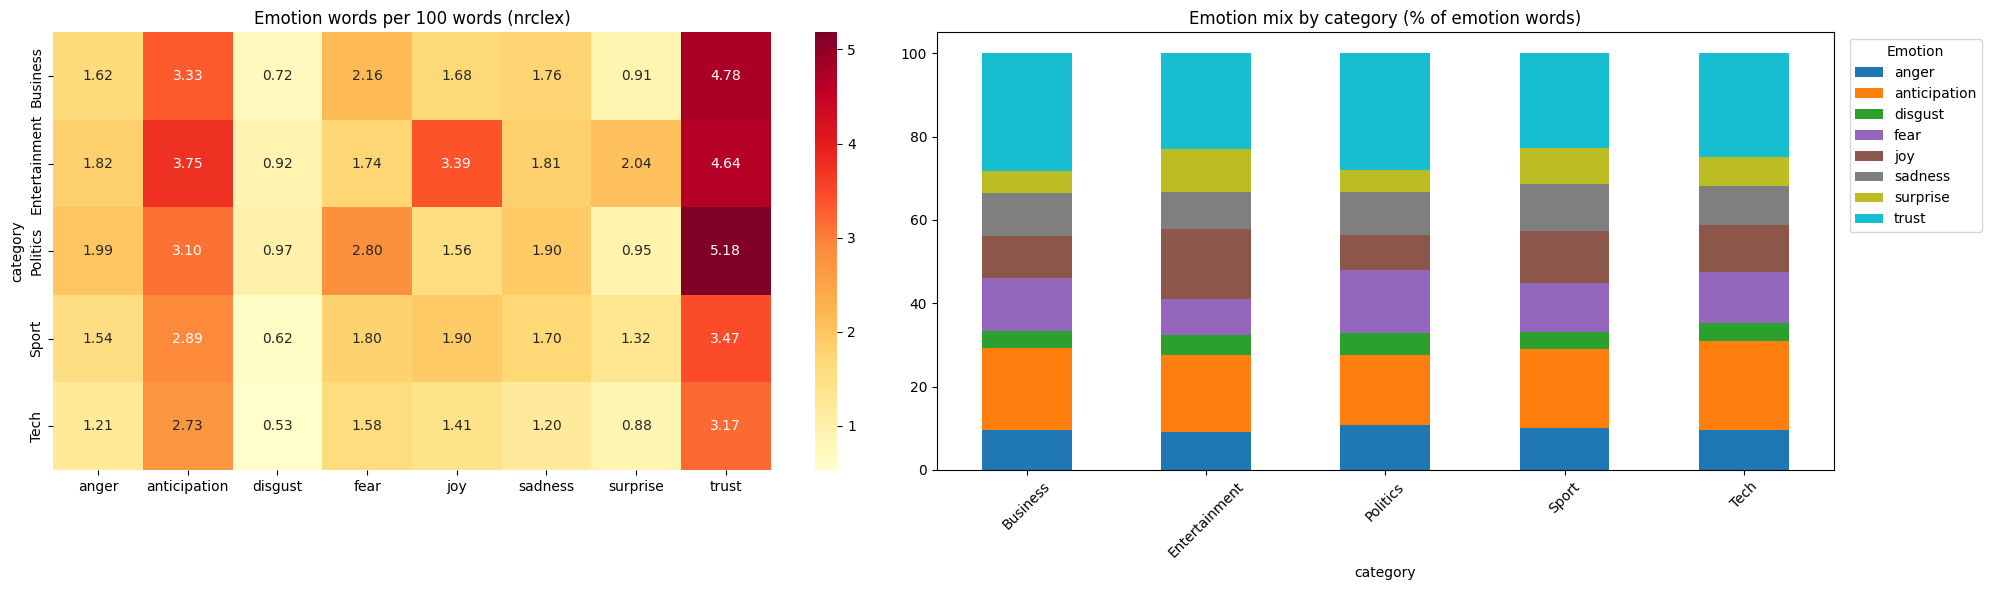


🔍 TOP TRIGGER WORDS FOR EACH CATEGORY'S TWO STRONGEST EMOTIONS
  Business       trust         analyst, share, economy, bank, deal, level
  Business       anticipation  analyst, share, time, expected, deal, plan
  Entertainment  trust         star, show, award, director, top, series
  Entertainment  anticipation  star, award, time, top, success, winner
  Politics       trust         leader, general, spokesman, law, chancellor, policy
  Politics       anticipation  plan, public, time, expected, council, vote
  Sport          trust         champion, team, coach, good, victory, title
  Sport          anticipation  time, champion, good, start, victory, top
  Tech           trust         system, show, good, found, director, content
  Tech           anticipation  time, good, network, mobile, analyst, top


In [ ]:
# Emotion distribution per category
emotion_by_cat = emotion_df.groupby('category')[EMOTIONS].mean()
emotion_mix = emotion_by_cat.div(emotion_by_cat.sum(axis=1), axis=0) * 100

print("🎭 EMOTION WORDS PER 100 WORDS (by category)")
print((emotion_by_cat * 100).round(2))
print("\n🎭 EMOTION MIX (% of all emotion words in the category)")
print(emotion_mix.round(1))
print("\n👑 DOMINANT EMOTION PER ARTICLE (% of articles in each category)")
print((pd.crosstab(emotion_df['category'], emotion_df['dominant_emotion'], normalize='index') * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
sns.heatmap(emotion_by_cat * 100, annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[0])
axes[0].set_title(f'Emotion words per 100 words ({EMOTION_BACKEND})')
emotion_mix.plot(kind='bar', stacked=True, ax=axes[1], colormap='tab10')
axes[1].set_title('Emotion mix by category (% of emotion words)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Emotion', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
save_figure('m6_emotions', fig)
plt.show()

# Which words trigger the two strongest emotions in each category?
print("\n🔍 TOP TRIGGER WORDS FOR EACH CATEGORY'S TWO STRONGEST EMOTIONS")
for cat in categories:
    for emo in emotion_by_cat.loc[cat].nlargest(2).index:
        top = emotion_triggers.get((cat, emo), Counter()).most_common(6)
        print(f"  {cat:<14} {emo:<13} {', '.join(w for w, _ in top)}")

### 🔍 Sentiment & Emotion Findings (my interpretation)

**Sentiment by category:** The most positive category is Entertainment (mean 0.580 whole-article / 0.192 sentence-average), followed by Sport (0.545 / 0.143); the most negative is Politics (0.039 / 0.019). Business: 0.239 / 0.054, Tech: 0.532 / 0.095. Entertainment has the highest share of positive words (pos 0.135, just ahead of Sport 0.134), Politics the highest share of negative words (neg 0.087).
This largely fits the hypothesis that sports are more positive and politics more negative because sports news often covers victories, achievements, and celebrations, while political news frequently discusses conflicts, criticism, and controversial issues.

**Saturation:** 70.4% of articles have a whole-article score beyond ±0.9, vs. 0.0% with the sentence average. 236 of 1,432 articles change label when using the sentence average (mostly positive → neutral: 121, and negative → neutral: 93). I will use the sentence average as the main sentiment measure because it reduces the saturation effect of long articles and provides a more balanced representation of sentiment across individual sentences.

**Lead vs. whole article:** The lead and the whole article agree in 61.0% of cases (correlation 0.496). This suggests that the lead provides a useful indication of the article's overall sentiment, but it does not always represent the tone of the entire article.

**Sanity check:** The most positive article was "gatlin and hayes win owen awards" (Sport, sentence-avg 0.788), which is really positive because winning awards is associated with success and recognition, which generally convey a positive tone.
The most negative was "pountney handed ban and fine" (Sport, sentence-avg −0.664), which makes sense because a ban and a fine are punishments, and the article describes a coach being disciplined for calling a referee "a disgrace".

**VADER's limits on news text:** Words like "slam," "penalty," and "cut" push Sport and Business articles negative although in that context they mean neutral descriptions of events, such as a tennis Grand Slam, a penalty kick in football, or an interest-rate cut.
Other limits: Lowercasing removes capitalization cues, long articles can produce extreme compound scores, and neutral journalistic reporting may contain negative words without expressing a negative opinion. VADER can also struggle with context, sarcasm, and words whose sentiment depends on how they are used.

**Emotions:** Trust is the strongest emotion in every category (per 100 words: Politics 5.18, Business 4.78, Entertainment 4.64, Sport 3.47, Tech 3.17) and the dominant emotion in about 57% of all articles (Politics 72.9%, Business 64.8%, Entertainment 51.7%, Tech 50.9%, Sport 46.5%). Anticipation is second everywhere (16.8–21.5% of emotion words) and dominant in about 24% of articles. Entertainment has the most joy (3.39), surprise (2.04) and anticipation (3.75); Politics the most fear (2.80), anger (1.99), disgust (0.97) and sadness (1.90).
Trigger words show that the same word can be associated with an emotion even when the surrounding context does not express that emotion (e.g. "share" counted as trust in Business), which means the NRC Emotion Lexicon can identify broad emotional patterns but may misrepresent the intended meaning when it counts words without fully considering their context.
Emotion backend used: nrclex (NRC Emotion Lexicon).

**Sentiment as a classification feature:** Given the overlap between categories in the boxplots, I expect sentiment to help a little in Module 7 because some categories have noticeably different sentiment and emotion patterns, particularly Entertainment and Sport for joy and Politics for negative emotions. However, these features overlap across categories and are not enough to identify the news topic reliably on their own. Combining them with TF-IDF and syntax features may improve classification.

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# Prepare features for classification
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler

# Feature groups (built from Modules 2–6)
SENTIMENT_COLS = ['full_sentiment', 'avg_sentence_sentiment', 'pos_score', 'neu_score', 'neg_score',
                  'share_pos_sentences', 'share_neg_sentences']
LENGTH_COLS = ['char_count', 'word_count', 'n_sentences']
LINGUISTIC_COLS = SYNTAX_FEATURE_COLS + STYLE_FEATURE_COLS     # 14 POS/syntax features (Module 5)
EMOTION_COLS = list(EMOTIONS)                                   # 8 NRC emotions (Module 6)
ALL_NUMERIC_COLS = SENTIMENT_COLS + LENGTH_COLS + LINGUISTIC_COLS + EMOTION_COLS


def article_feature_row(full_text, spacy_res=None):
    """Compute ALL model features for one article – used for training AND for new articles.

    full_text: raw article text (contractions repaired). spacy_res: cached spaCy-pass result
    for this article (training); if None the text is parsed now (new articles).
    """
    full_text = '' if full_text is None else str(full_text)
    if spacy_res is None:
        doc = _to_doc(full_text)
        style = compute_style_metrics(doc) if doc is not None else {}
        syntax = extract_syntactic_features(doc) if doc is not None else {}
    else:
        style, syntax = spacy_res['style'], spacy_res['syntax']

    full_s = analyze_sentiment(full_text)
    sent_s = analyze_sentence_sentiment(full_text)
    emotions, _ = emotion_profile(full_text)
    n_sent = max(syntax.get('num_sentences', 0), 1)

    row = {
        'text_processed': preprocess_text(full_text),
        # sentiment
        'full_sentiment': full_s['compound'], 'avg_sentence_sentiment': sent_s['avg_sentence_compound'],
        'pos_score': full_s['pos'], 'neu_score': full_s['neu'], 'neg_score': full_s['neg'],
        'share_pos_sentences': sent_s['share_pos_sentences'], 'share_neg_sentences': sent_s['share_neg_sentences'],
        # length
        'char_count': len(full_text), 'word_count': len(full_text.split()),
        'n_sentences': style.get('n_sentences', 0),
        # syntax (same definitions as Module 5)
        'avg_sentence_length': style.get('avg_sentence_length', 0.0),
        'avg_tree_depth': syntax.get('avg_tree_depth', 0.0),
        'max_tree_depth': syntax.get('max_tree_depth', 0),
        'passive_sentence_share': syntax.get('passive_sentence_share', 0.0),
        'noun_phrases_per_sentence': len(syntax.get('noun_phrases', [])) / n_sent,
        'svo_per_sentence': len(syntax.get('svo_triples', [])) / n_sent,
    }
    row.update({c: style.get(c, 0.0) for c in STYLE_FEATURE_COLS})   # POS/style (Module 4)
    row.update({e: emotions[e] for e in EMOTIONS})                    # emotions (Module 6)
    return row


def build_pipeline(classifier, numeric_cols=(), use_text=True):
    """TF-IDF on 'text_processed' + MinMax-scaled numeric features -> classifier.

    Everything is fitted INSIDE the pipeline, i.e. on training data only (no leakage).
    MinMaxScaler(clip=True) keeps numeric features in [0, 1], so Multinomial NB accepts them.
    """
    transformers = []
    if use_text:
        transformers.append(('tfidf', TfidfVectorizer(**BEST_TFIDF_PARAMS), 'text_processed'))
    if len(numeric_cols) > 0:
        transformers.append(('num', MinMaxScaler(clip=True), list(numeric_cols)))
    return Pipeline([('features', ColumnTransformer(transformers)), ('clf', classifier)])


print("🔧 Preparing features for classification...")
feature_df = cached('model_features', lambda: pd.DataFrame(
    [article_feature_row(t, r) for t, r in zip(df['full_text'], spacy_results)]))

# Consistency check: processed text must match Module 2
n_mismatch = (feature_df['text_processed'].values != df['full_text_processed'].values).sum()
print(f"✅ Feature table: {feature_df.shape[0]} articles × {len(ALL_NUMERIC_COLS)} numeric features + text")
print(f"   Processed-text mismatches vs. Module 2: {n_mismatch} (should be 0)")

# Target variable + stratified split

🔧 Preparing features for classification...
⏱️ 'model_features' computed in 29.9s
💾 Saved model_features_full.pkl
✅ Feature table: 1432 articles × 32 numeric features + text
   Processed-text mismatches vs. Module 2: 0 (should be 0)


In [ ]:
# Consistency check: processed text must match Module 2
n_mismatch = (feature_df['text_processed'].values != df['full_text_processed'].values).sum()
print(f"✅ Feature table: {feature_df.shape[0]} articles × {len(ALL_NUMERIC_COLS)} numeric features + text")
print(f"   Processed-text mismatches vs. Module 2: {n_mismatch} (should be 0)")

# Target variable + stratified split (indices kept for error analysis later)
y = df['category'].values
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2,
                                       stratify=y, random_state=RANDOM_STATE)
X_train = feature_df.iloc[idx_train].reset_index(drop=True)
X_test = feature_df.iloc[idx_test].reset_index(drop=True)
y_train, y_test = y[idx_train], y[idx_test]

print(f"\n📈 Data split:")
print(f"  Training set: {len(X_train)} articles | Test set: {len(X_test)} articles")
print(f"  Classes: {np.unique(y)}")

✅ Feature table: 1432 articles × 32 numeric features + text
   Processed-text mismatches vs. Module 2: 0 (should be 0)

📈 Data split:
  Training set: 1145 articles | Test set: 287 articles
  Classes: ['Business' 'Entertainment' 'Politics' 'Sport' 'Tech']


🤖 Training multiple classifiers (TF-IDF features only)...

🔄 Training Naive Bayes...
  ✅ Test accuracy: 0.9477 | macro-F1: 0.9432
  📊 CV macro-F1: 0.9675 (± 0.0090) | train time: 1.82s

🔄 Training Logistic Regression...
  ✅ Test accuracy: 0.9477 | macro-F1: 0.9432
  📊 CV macro-F1: 0.9692 (± 0.0099) | train time: 3.28s

🔄 Training Linear SVM...
  ✅ Test accuracy: 0.9686 | macro-F1: 0.9657
  📊 CV macro-F1: 0.9765 (± 0.0065) | train time: 1.38s

🔄 Training SVM (RBF)...
  ✅ Test accuracy: 0.9547 | macro-F1: 0.9497
  📊 CV macro-F1: 0.9767 (± 0.0100) | train time: 4.46s

🔄 Training Random Forest...
  ✅ Test accuracy: 0.9408 | macro-F1: 0.9373
  📊 CV macro-F1: 0.9515 (± 0.0141) | train time: 5.12s

🏆 CLASSIFIER COMPARISON (TF-IDF only)
                     cv_accuracy   cv_f1  cv_f1_std  test_accuracy  \
SVM (RBF)                 0.9773  0.9767     0.0100         0.9547   
Linear SVM                0.9773  0.9765     0.0065         0.9686   
Logistic Regression       0.9703  0.9692     0.0099

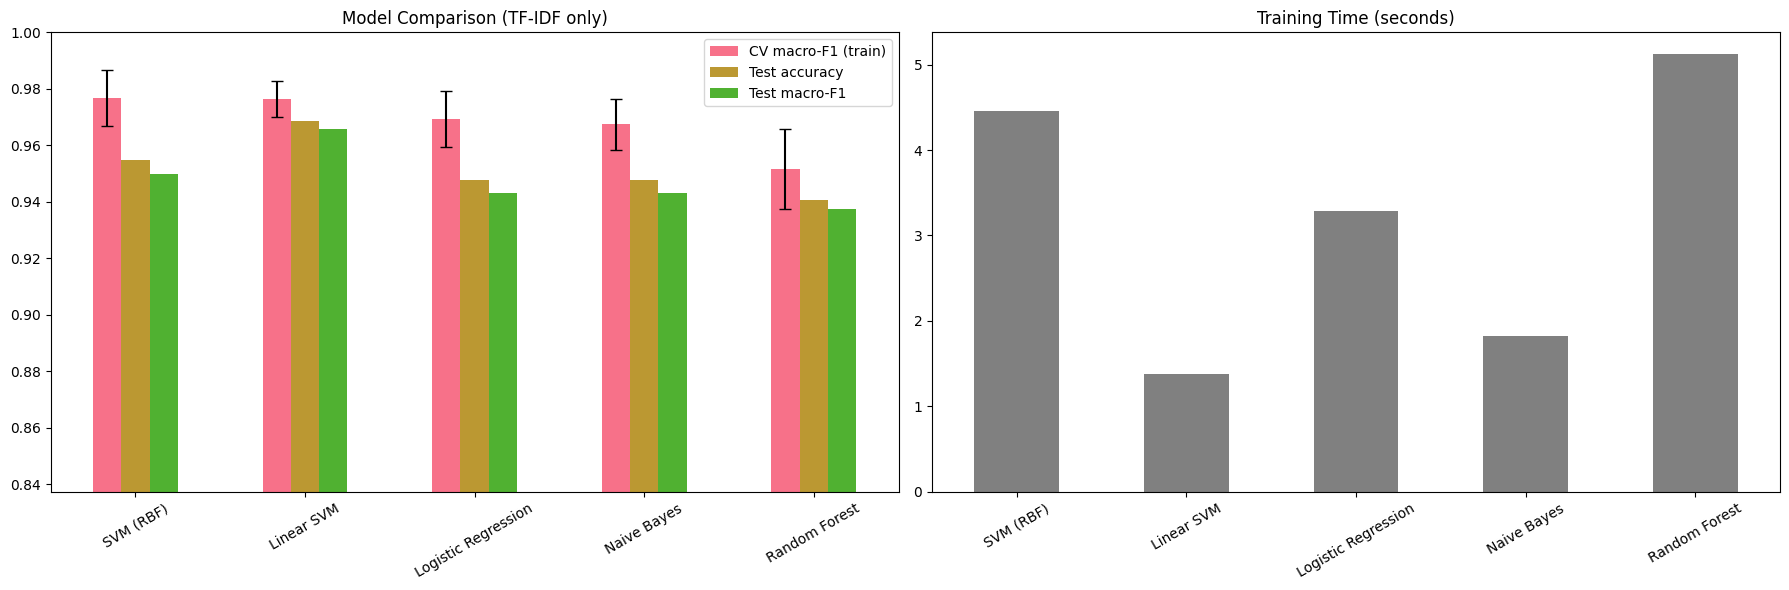


🥇 Best model by CV macro-F1 (provisional): SVM (RBF)


In [ ]:
# Train and evaluate multiple classifiers
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import precision_recall_fscore_support

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def get_classifiers():
    """Fresh, unfitted classifiers to compare (random_state fixed for reproducibility)."""
    return {
        'Naive Bayes': MultinomialNB(),
        'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        'Linear SVM': LinearSVC(random_state=RANDOM_STATE),
        'SVM (RBF)': SVC(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    }


def evaluate_model(classifier, numeric_cols=(), use_text=True):
    """5-fold CV on the training set + one fit/evaluation on the test set. Returns (fitted pipeline, metrics)."""
    pipe = build_pipeline(classifier, numeric_cols, use_text)
    cv_res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=['accuracy', 'f1_macro'])
    start = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - start
    y_pred = pipe.predict(X_test)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    return pipe, {
        'cv_accuracy': cv_res['test_accuracy'].mean(), 'cv_f1': cv_res['test_f1_macro'].mean(),
        'cv_f1_std': cv_res['test_f1_macro'].std(),
        'test_accuracy': accuracy_score(y_test, y_pred), 'test_precision': prec,
        'test_recall': rec, 'test_f1': f1, 'train_time_s': fit_time, 'predictions': y_pred,
    }


print("🤖 Training multiple classifiers (TF-IDF features only)...")
results, trained_models = {}, {}
for name, classifier in get_classifiers().items():
    print(f"\n🔄 Training {name}...")
    trained_models[name], results[name] = evaluate_model(classifier)
    r = results[name]
    print(f"  ✅ Test accuracy: {r['test_accuracy']:.4f} | macro-F1: {r['test_f1']:.4f}")
    print(f"  📊 CV macro-F1: {r['cv_f1']:.4f} (± {r['cv_f1_std']:.4f}) | train time: {r['train_time_s']:.2f}s")
    results[name]['accuracy'] = r['test_accuracy']          # key used by the comprehensive analysis cell

print("\n🏆 CLASSIFIER COMPARISON (TF-IDF only)")
print("=" * 50)
metric_cols = ['cv_accuracy', 'cv_f1', 'cv_f1_std', 'test_accuracy', 'test_precision',
               'test_recall', 'test_f1', 'train_time_s']
comparison_df = (pd.DataFrame({name: {m: results[name][m] for m in metric_cols} for name in results}).T
                 .sort_values('cv_f1', ascending=False))
print(comparison_df.round(4))

# Visualize the comparison
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
plot_df = comparison_df[['cv_f1', 'test_accuracy', 'test_f1']]
plot_df.plot(kind='bar', ax=axes[0], yerr={'cv_f1': comparison_df['cv_f1_std']}, capsize=4)
axes[0].set_ylim(max(0, plot_df.values.min() - 0.1), 1.0)
axes[0].set_title('Model Comparison (TF-IDF only)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(['CV macro-F1 (train)', 'Test accuracy', 'Test macro-F1'])
comparison_df['train_time_s'].plot(kind='bar', ax=axes[1], color='gray')
axes[1].set_title('Training Time (seconds)')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
save_figure('m7_model_comparison', fig)
plt.show()

# Provisional best model – chosen on CROSS-VALIDATION, not on the test set
best_model_name = comparison_df.index[0]
print(f"\n🥇 Best model by CV macro-F1 (provisional): {best_model_name}")

🧪 Comparing feature combinations (this is the slowest cell of Module 7)...
  Non-text only (sent+len+ling+emo)    Naive Bayes          F1=0.4423
  Non-text only (sent+len+ling+emo)    Logistic Regression  F1=0.6440
  Non-text only (sent+len+ling+emo)    Linear SVM           F1=0.6634
  Non-text only (sent+len+ling+emo)    SVM (RBF)            F1=0.6519
  Non-text only (sent+len+ling+emo)    Random Forest        F1=0.6543
  TF-IDF only                          Naive Bayes          F1=0.9675
  TF-IDF only                          Logistic Regression  F1=0.9692
  TF-IDF only                          Linear SVM           F1=0.9765
  TF-IDF only                          SVM (RBF)            F1=0.9767
  TF-IDF only                          Random Forest        F1=0.9515
  TF-IDF + sentiment + length          Naive Bayes          F1=0.9473
  TF-IDF + sentiment + length          Logistic Regression  F1=0.9591
  TF-IDF + sentiment + length          Linear SVM           F1=0.9801
  TF-IDF + sent

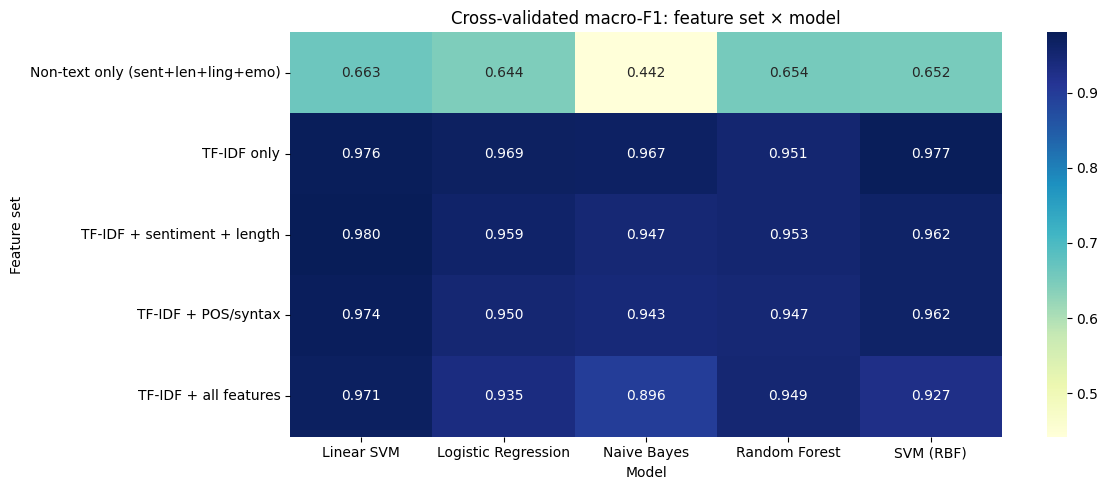


🥇 Best combination: Linear SVM + 'TF-IDF + sentiment + length' (CV macro-F1 0.9801 ± 0.0068)


In [ ]:
# 💡 STUDENT TASK: try different feature combinations (5-fold CV on the training set)
FEATURE_SETS = {
    'Non-text only (sent+len+ling+emo)': dict(numeric_cols=ALL_NUMERIC_COLS, use_text=False),
    'TF-IDF only':                       dict(numeric_cols=[], use_text=True),
    'TF-IDF + sentiment + length':       dict(numeric_cols=SENTIMENT_COLS + LENGTH_COLS, use_text=True),
    'TF-IDF + POS/syntax':               dict(numeric_cols=LINGUISTIC_COLS, use_text=True),
    'TF-IDF + all features':             dict(numeric_cols=ALL_NUMERIC_COLS, use_text=True),
}


def compare_feature_sets():
    """CV macro-F1 and accuracy for every (feature set, model) combination."""
    rows = []
    for set_name, cfg in FEATURE_SETS.items():
        for model_name, clf in get_classifiers().items():
            pipe = build_pipeline(clf, cfg['numeric_cols'], cfg['use_text'])
            res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=['accuracy', 'f1_macro'])
            rows.append({'feature_set': set_name, 'model': model_name,
                         'n_numeric': len(cfg['numeric_cols']), 'use_text': cfg['use_text'],
                         'cv_f1': res['test_f1_macro'].mean(), 'cv_f1_std': res['test_f1_macro'].std(),
                         'cv_accuracy': res['test_accuracy'].mean()})
            print(f"  {set_name:<36} {model_name:<20} F1={rows[-1]['cv_f1']:.4f}")
    return pd.DataFrame(rows)


print("🧪 Comparing feature combinations (this is the slowest cell of Module 7)...")
combo_df = cached('feature_set_comparison', compare_feature_sets)

combo_pivot = (combo_df.pivot(index='feature_set', columns='model', values='cv_f1')
               .reindex(list(FEATURE_SETS.keys())))
print("\n📊 CV MACRO-F1 BY FEATURE SET × MODEL")
print(combo_pivot.round(4))

plt.figure(figsize=(12, 5))
sns.heatmap(combo_pivot, annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('Cross-validated macro-F1: feature set × model')
plt.xlabel('Model')
plt.ylabel('Feature set')
plt.tight_layout()
save_figure('m7_feature_combinations')
plt.show()

# Best combination: highest CV F1; ties -> fewer extra features (simpler model)
best_combo = combo_df.sort_values(['cv_f1', 'n_numeric'], ascending=[False, True]).iloc[0]
BEST_MODEL_NAME = best_combo['model']
BEST_FEATURE_SET = best_combo['feature_set']
print(f"\n🥇 Best combination: {BEST_MODEL_NAME} + '{BEST_FEATURE_SET}' "
      f"(CV macro-F1 {best_combo['cv_f1']:.4f} ± {best_combo['cv_f1_std']:.4f})")

In [ ]:
# 💡 STUDENT TASK: hyperparameter tuning with a small GridSearchCV (training set only)
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

PARAM_GRIDS = {
    'Naive Bayes':         {'clf__alpha': [0.01, 0.1, 0.5, 1.0]},
    'Logistic Regression': {'clf__C': [0.5, 1, 5, 20]},
    'Linear SVM':          {'clf__C': [0.05, 0.1, 0.5, 1, 5]},
    'SVM (RBF)':           {'clf__C': [1, 10, 50], 'clf__gamma': ['scale', 1.0]},
    'Random Forest':       {'clf__n_estimators': [300, 600], 'clf__max_depth': [None, 40]},
}


def safe_name(text):
    """Make a string safe for file names (e.g. 'TF-IDF + POS/syntax' -> 'TF_IDF_POS_syntax')."""
    return re.sub(r'[^A-Za-z0-9]+', '_', text).strip('_')


best_cfg = FEATURE_SETS[BEST_FEATURE_SET]
FINAL_NUMERIC_COLS, FINAL_USE_TEXT = list(best_cfg['numeric_cols']), best_cfg['use_text']
param_grid = dict(PARAM_GRIDS[BEST_MODEL_NAME])
if FINAL_USE_TEXT:
    param_grid['features__tfidf__ngram_range'] = [(1, 1), (1, 2)]


def run_grid_search():
    """Grid search over the best model's key hyperparameters (5-fold CV, macro-F1)."""
    base = build_pipeline(get_classifiers()[BEST_MODEL_NAME], FINAL_NUMERIC_COLS, FINAL_USE_TEXT)
    gs = GridSearchCV(base, param_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
    gs.fit(X_train, y_train)
    return gs


n_settings = int(np.prod([len(v) for v in param_grid.values()]))
print(f"🔎 GridSearch: {BEST_MODEL_NAME} + '{BEST_FEATURE_SET}' – {n_settings} settings × 5 folds")
grid_search = cached(f'grid_{safe_name(BEST_MODEL_NAME)}_{safe_name(BEST_FEATURE_SET)}', run_grid_search)

grid_table = (pd.DataFrame(grid_search.cv_results_)
              [['params', 'mean_test_score', 'std_test_score', 'rank_test_score']]
              .sort_values('rank_test_score'))
print("\n🏆 TOP SETTINGS (CV macro-F1)")
print(grid_table.head(10).to_string(index=False))
print(f"\n🥇 Best params: {grid_search.best_params_}")
print(f"   Tuned CV macro-F1: {grid_search.best_score_:.4f}  (untuned: {best_combo['cv_f1']:.4f})")

tuned_pipeline = grid_search.best_estimator_

🔎 GridSearch: Linear SVM + 'TF-IDF + sentiment + length' – 10 settings × 5 folds
⏱️ 'grid_Linear_SVM_TF_IDF_sentiment_length' computed in 39.5s
💾 Saved grid_Linear_SVM_TF_IDF_sentiment_length_full.pkl

🏆 TOP SETTINGS (CV macro-F1)
                                                  params  mean_test_score  std_test_score  rank_test_score
   {'clf__C': 1, 'features__tfidf__ngram_range': (1, 2)}         0.980111        0.006835                1
 {'clf__C': 0.5, 'features__tfidf__ngram_range': (1, 2)}         0.979193        0.007858                2
   {'clf__C': 5, 'features__tfidf__ngram_range': (1, 2)}         0.979014        0.009371                3
   {'clf__C': 5, 'features__tfidf__ngram_range': (1, 1)}         0.977332        0.006708                4
   {'clf__C': 1, 'features__tfidf__ngram_range': (1, 1)}         0.976417        0.005745                5
 {'clf__C': 0.5, 'features__tfidf__ngram_range': (1, 1)}         0.975545        0.004609                6
 {'clf__C': 0.1, 'fe

🎯 Feature selection on 5010 features...
  k=250   F1=0.9632
  k=500   F1=0.9776
  k=1000  F1=0.9728
  k=2000  F1=0.9747
  k=all   F1=0.9801
⏱️ 'selectk_Linear_SVM_TF_IDF_sentiment_length' computed in 30.7s
💾 Saved selectk_Linear_SVM_TF_IDF_sentiment_length_full.pkl
   k  cv_f1  cv_f1_std
 250 0.9632     0.0199
 500 0.9776     0.0097
1000 0.9728     0.0078
2000 0.9747     0.0108
 all 0.9801     0.0068
🖼️ Figure saved: m7_feature_selection.png


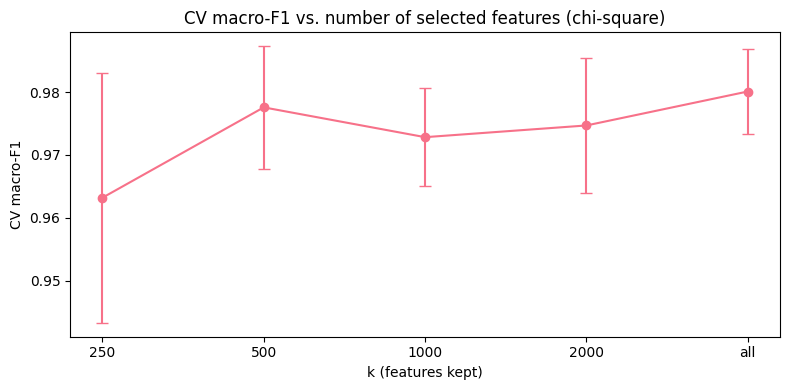


✅ Decision: keep k = all features

🏷️ Top 15 features by chi-square:
film, labour, user, tory, blair, election, award, party, actor, technology, computer, software, currency_usd, oscar, microsoft
   Highest-ranked non-text feature: full_sentiment (rank 48 of 5010)


In [ ]:
# 💡 STUDENT TASK: feature selection with SelectKBest + chi-square (inside the pipeline)
from sklearn.feature_selection import SelectKBest, chi2


def add_feature_selection(pipeline, k):
    """Unfitted copy of the pipeline with SelectKBest(chi2, k) between features and classifier."""
    p = clone(pipeline)
    return Pipeline(p.steps[:-1] + [('select', SelectKBest(chi2, k=k)), p.steps[-1]])


n_features_total = tuned_pipeline.named_steps['features'].transform(X_train.head(1)).shape[1]
K_VALUES = [k for k in [250, 500, 1000, 2000] if k < n_features_total] + ['all']


def run_selection():
    """CV macro-F1 for each number of selected features k."""
    rows = []
    for k in K_VALUES:
        res = cross_validate(add_feature_selection(tuned_pipeline, k), X_train, y_train,
                             cv=CV, scoring='f1_macro')
        rows.append({'k': str(k), 'cv_f1': res['test_score'].mean(), 'cv_f1_std': res['test_score'].std()})
        print(f"  k={str(k):<5} F1={rows[-1]['cv_f1']:.4f}")
    return pd.DataFrame(rows)


print(f"🎯 Feature selection on {n_features_total} features...")
selection_df = cached(f'selectk_{safe_name(BEST_MODEL_NAME)}_{safe_name(BEST_FEATURE_SET)}', run_selection)
print(selection_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
plt.errorbar(selection_df['k'], selection_df['cv_f1'], yerr=selection_df['cv_f1_std'], marker='o', capsize=4)
plt.title('CV macro-F1 vs. number of selected features (chi-square)')
plt.xlabel('k (features kept)')
plt.ylabel('CV macro-F1')
plt.tight_layout()
save_figure('m7_feature_selection')
plt.show()

# Use selection only if it beats the tuned model without selection
best_sel = selection_df.loc[selection_df['cv_f1'].idxmax()]
if best_sel['k'] != 'all' and best_sel['cv_f1'] > grid_search.best_score_:
    BEST_K = int(best_sel['k'])
    final_pipeline = add_feature_selection(tuned_pipeline, BEST_K)
else:
    BEST_K = 'all'
    final_pipeline = clone(tuned_pipeline)
final_pipeline.fit(X_train, y_train)
print(f"\n✅ Decision: keep k = {BEST_K} features")

# Which features does chi-square rank highest? (are any non-text features near the top?)
feat_step = final_pipeline.named_steps['features']
feat_names = feat_step.get_feature_names_out()
chi_scores, _ = chi2(feat_step.transform(X_train), y_train)
chi_rank = pd.Series(np.nan_to_num(chi_scores), index=feat_names).sort_values(ascending=False)
print("\n🏷️ Top 15 features by chi-square:")
print(', '.join(n.split('__', 1)[1] for n in chi_rank.index[:15]))
num_ranks = [i + 1 for i, n in enumerate(chi_rank.index) if n.startswith('num__')]
if num_ranks:
    best_num = chi_rank.index[num_ranks[0] - 1].split('__', 1)[1]
    print(f"   Highest-ranked non-text feature: {best_num} (rank {num_ranks[0]} of {len(chi_rank)})")

In [ ]:
# 💡 STUDENT TASK: check and handle class imbalance
dist = pd.DataFrame({'train': pd.Series(y_train).value_counts(),
                     'test': pd.Series(y_test).value_counts()})
dist['train_%'] = (dist['train'] / dist['train'].sum() * 100).round(1)
print("⚖️ CLASS DISTRIBUTION")
print(dist)
print(f"Imbalance ratio (train, largest/smallest): {dist['train'].max() / dist['train'].min():.2f}")

USED_CLASS_WEIGHT = None
if 'class_weight' in final_pipeline.named_steps['clf'].get_params():
    base_f1 = cross_validate(final_pipeline, X_train, y_train, cv=CV, scoring='f1_macro')['test_score']
    balanced = clone(final_pipeline).set_params(clf__class_weight='balanced')
    bal_f1 = cross_validate(balanced, X_train, y_train, cv=CV, scoring='f1_macro')['test_score']
    print(f"\nCV macro-F1 without class weights: {base_f1.mean():.4f} ± {base_f1.std():.4f}")
    print(f"CV macro-F1 with class_weight='balanced': {bal_f1.mean():.4f} ± {bal_f1.std():.4f}")
    if bal_f1.mean() > base_f1.mean():
        final_pipeline = balanced.fit(X_train, y_train)
        USED_CLASS_WEIGHT = 'balanced'
    print(f"✅ Decision: class_weight = {USED_CLASS_WEIGHT}")
else:
    print(f"\nℹ️ {BEST_MODEL_NAME} has no class_weight option – stratified splits already keep class proportions equal.")

⚖️ CLASS DISTRIBUTION
               train  test  train_%
Sport            273    69     23.8
Business         268    67     23.4
Politics         213    53     18.6
Entertainment    209    52     18.3
Tech             182    46     15.9
Imbalance ratio (train, largest/smallest): 1.50

CV macro-F1 without class weights: 0.9801 ± 0.0068
CV macro-F1 with class_weight='balanced': 0.9809 ± 0.0072
✅ Decision: class_weight = balanced


📊 DETAILED EVALUATION: Linear SVM (tuned)
   Feature set: TF-IDF + sentiment + length | class_weight: balanced | calibrated: True
   Test accuracy before calibration: 0.9617
   Test accuracy: 0.9617 | macro-F1: 0.9582

📋 Classification Report:
               precision    recall  f1-score   support

     Business      0.970     0.970     0.970        67
Entertainment      0.945     1.000     0.972        52
     Politics      0.943     0.943     0.943        53
        Sport      0.972     1.000     0.986        69
         Tech      0.976     0.870     0.920        46

     accuracy                          0.962       287
    macro avg      0.961     0.957     0.958       287
 weighted avg      0.962     0.962     0.961       287

🖼️ Figure saved: m7_confusion_matrix.png


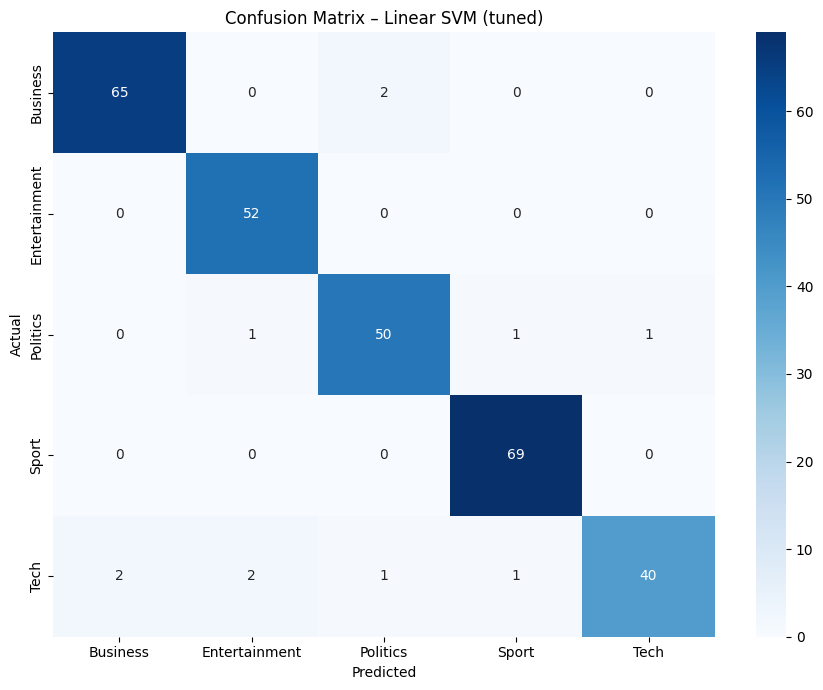


🔍 Top Features by Category:

📰 Business: currency_usd (1.45), firm (1.41), company (1.30), bank (1.25), investment (1.11), business (1.03), economic (1.01), market (0.93), economy (0.93), rate (0.86)

📰 Entertainment: film (1.83), show (1.49), singer (1.30), star (1.27), music (1.25), album (1.20), band (1.15), actor (1.02), song (0.86), festival (0.80)

📰 Politics: party (1.32), labour (1.24), minister (1.17), secretary (1.17), blair (1.17), election (1.09), tory (1.04), common (1.03), britain (0.90), government (0.89)

📰 Sport: match (1.15), coach (1.07), player (1.05), club (1.04), game (0.96), champion (0.93), injury (0.91), season (0.85), win (0.81), team (0.80)

📰 Tech: computer (1.42), user (1.33), technology (1.26), online (1.09), software (1.09), people (1.01), website (0.86), net (0.84), digital (0.84), machine (0.78)


In [ ]:
# Detailed evaluation of the best model (on the held-out TEST set – used only here)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score


def make_deployable(pipeline):
    """Ensure predict_proba exists (needed for NewsBot confidence). LinearSVC/RBF-SVC get calibrated."""
    if hasattr(pipeline, 'predict_proba'):
        return pipeline, False
    p = clone(pipeline)
    calibrated = CalibratedClassifierCV(estimator=p.steps[-1][1], cv=5)
    return Pipeline(p.steps[:-1] + [('clf', calibrated)]).fit(X_train, y_train), True


best_model, was_calibrated = make_deployable(final_pipeline)
suffix = f", k={BEST_K}" if BEST_K != 'all' else ''
best_model_name = f"{BEST_MODEL_NAME} (tuned{suffix})"
best_predictions = best_model.predict(X_test)
results[best_model_name] = {'accuracy': accuracy_score(y_test, best_predictions)}

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print(f"   Feature set: {BEST_FEATURE_SET} | class_weight: {USED_CLASS_WEIGHT} | calibrated: {was_calibrated}")
print("=" * 60)
if was_calibrated:
    print(f"   Test accuracy before calibration: {accuracy_score(y_test, final_pipeline.predict(X_test)):.4f}")
print(f"   Test accuracy: {accuracy_score(y_test, best_predictions):.4f} | "
      f"macro-F1: {f1_score(y_test, best_predictions, average='macro'):.4f}")

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions, digits=3))

# Confusion matrix
labels = best_model.classes_
cm = confusion_matrix(y_test, best_predictions, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix – {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
save_figure('m7_confusion_matrix')
plt.show()


def top_features_per_class(pipeline, n=10):
    """Most influential features per class (works for linear models, NB and Random Forest)."""
    names = pipeline.named_steps['features'].get_feature_names_out()
    if 'select' in pipeline.named_steps:
        names = names[pipeline.named_steps['select'].get_support()]
    names = np.array([nm.replace('tfidf__', '').replace('num__', '[num] ') for nm in names])
    clf = pipeline.named_steps['clf']
    if hasattr(clf, 'coef_'):
        weights = clf.coef_
    elif hasattr(clf, 'feature_log_prob_'):
        weights = clf.feature_log_prob_ - clf.feature_log_prob_.mean(axis=0)   # vs. average class
    elif hasattr(clf, 'feature_importances_'):
        top = np.argsort(clf.feature_importances_)[::-1][:20]
        print("🌲 Top 20 features (Random Forest, all classes): " + ', '.join(names[top]))
        return
    else:
        print("ℹ️ This model has no direct feature weights (e.g. RBF SVM) – see the chi-square ranking in M7-e.")
        return
    for i, cls in enumerate(clf.classes_):
        top = np.argsort(weights[i])[::-1][:n]
        print(f"\n📰 {cls}: " + ', '.join(f"{names[j]} ({weights[i][j]:.2f})" for j in top))


print("\n🔍 Top Features by Category:")
top_features_per_class(final_pipeline)

In [ ]:
# 💡 STUDENT TASK: error analysis – which articles are misclassified, and why?
from sklearn.model_selection import cross_val_predict

classes_ = best_model.classes_
test_proba = best_model.predict_proba(X_test)
test_meta = df.iloc[idx_test].reset_index(drop=True)
eval_df = pd.DataFrame({
    'article_id': test_meta['article_id'], 'title': test_meta['title'],
    'true': y_test, 'pred': best_predictions, 'confidence': test_proba.max(axis=1),
    'runner_up': [classes_[np.argsort(p)[-2]] for p in test_proba],
})
test_errors = eval_df[eval_df['true'] != eval_df['pred']]
print(f"❌ Misclassified TEST articles: {len(test_errors)} of {len(eval_df)}")

# More examples: out-of-fold predictions on the TRAINING set (each article predicted by a model that never saw it)
oof_pred = cross_val_predict(clone(final_pipeline), X_train, y_train, cv=CV)
train_meta = df.iloc[idx_train].reset_index(drop=True)
oof_errors = train_meta.assign(true=y_train, pred=oof_pred)
oof_errors = oof_errors[oof_errors['true'] != oof_errors['pred']]
print(f"❌ Misclassified TRAINING articles (out-of-fold CV): {len(oof_errors)} of {len(train_meta)}")

all_errors = pd.concat([test_errors[['article_id', 'title', 'true', 'pred']].assign(source='test'),
                        oof_errors[['article_id', 'title', 'true', 'pred']].assign(source='cv')],
                       ignore_index=True)
if not all_errors.empty:
    print("\n🔀 Most common confusions (true → predicted):")
    print(all_errors.groupby(['true', 'pred']).size().sort_values(ascending=False).to_string())

tfidf_step = (final_pipeline.named_steps['features'].named_transformers_['tfidf']
              if FINAL_USE_TEXT else None)


def top_terms(processed_text, n=6):
    """Highest TF-IDF terms of one article (what the model 'saw')."""
    if tfidf_step is None:
        return '(no TF-IDF in this model)'
    row = tfidf_step.transform([processed_text]).toarray().ravel()
    vocab = tfidf_step.get_feature_names_out()
    return ', '.join(vocab[i] for i in row.argsort()[::-1][:n] if row[i] > 0)


print("\n📝 MISCLASSIFIED ARTICLES (up to 10)")
for _, e in all_errors.head(10).iterrows():
    mask = (df['article_id'] == e['article_id']).values
    print(f"\n[{e['source']}] id={e['article_id']} | true={e['true']} → predicted={e['pred']}")
    print(f"   text: {df.loc[mask, 'content'].iloc[0][:180]}...")
    print(f"   top terms: {top_terms(feature_df.loc[mask, 'text_processed'].iloc[0])}")

print("\n🤔 LEAST CONFIDENT CORRECT TEST PREDICTIONS (ambiguous articles)")
for _, r in eval_df[eval_df['true'] == eval_df['pred']].nsmallest(3, 'confidence').iterrows():
    print(f"   id={r['article_id']} {r['true']} (conf {r['confidence']:.2f}, runner-up {r['runner_up']}): {r['title']}...")

❌ Misclassified TEST articles: 11 of 287
❌ Misclassified TRAINING articles (out-of-fold CV): 21 of 1145

🔀 Most common confusions (true → predicted):
true           pred         
Business       Politics         7
Entertainment  Tech             4
Tech           Business         4
               Entertainment    3
Politics       Entertainment    2
               Business         2
               Tech             2
Tech           Politics         2
Business       Tech             1
               Entertainment    1
Sport          Politics         1
               Business         1
Politics       Sport            1
Tech           Sport            1

📝 MISCLASSIFIED ARTICLES (up to 10)

[test] id=1381 | true=Business → predicted=Politics
   text: world leaders gather to face uncertainty more than 2 000 business and political leaders from around the globe are arriving in the swiss mountain resort davos for the annual world e...
   top terms: gate, forum, brazilian, cause, microsoft, leader

In [ ]:
# Save the best model (full pipeline: TF-IDF + scaler + classifier) with joblib
import json
import sklearn

model_path = MODEL_DIR / f'newsbot_classifier_{RUN_TAG}.joblib'
meta_path = MODEL_DIR / f'newsbot_classifier_{RUN_TAG}.json'
joblib.dump(best_model, model_path)

metadata = {
    'model': best_model_name, 'base_model': BEST_MODEL_NAME, 'feature_set': BEST_FEATURE_SET,
    'uses_tfidf': FINAL_USE_TEXT, 'numeric_features': FINAL_NUMERIC_COLS,
    'best_params': {k: str(v) for k, v in grid_search.best_params_.items()},
    'selectkbest_k': str(BEST_K), 'class_weight': str(USED_CLASS_WEIGHT), 'calibrated': was_calibrated,
    'cv_macro_f1_tuned': round(float(grid_search.best_score_), 4),
    'test_accuracy': round(float(accuracy_score(y_test, best_predictions)), 4),
    'test_macro_f1': round(float(f1_score(y_test, best_predictions, average='macro')), 4),
    'n_train': len(X_train), 'n_test': len(X_test), 'run': RUN_TAG, 'random_state': RANDOM_STATE,
    'sklearn_version': sklearn.__version__, 'saved_at': time.strftime('%Y-%m-%d %H:%M'),
}
meta_path.write_text(json.dumps(metadata, indent=2))

# Reload test: the saved file must give identical predictions
loaded_model = joblib.load(model_path)
assert (loaded_model.predict(X_test) == best_predictions).all(), "Reloaded model predicts differently!"
print(f"💾 Model saved: {model_path.name} ({model_path.stat().st_size / 1e6:.1f} MB)")
print(f"📝 Metadata saved: {meta_path.name}")
print(json.dumps(metadata, indent=2))

💾 Model saved: newsbot_classifier_full.joblib (1.2 MB)
📝 Metadata saved: newsbot_classifier_full.json
{
  "model": "Linear SVM (tuned)",
  "base_model": "Linear SVM",
  "feature_set": "TF-IDF + sentiment + length",
  "uses_tfidf": true,
  "numeric_features": [
    "full_sentiment",
    "avg_sentence_sentiment",
    "pos_score",
    "neu_score",
    "neg_score",
    "share_pos_sentences",
    "share_neg_sentences",
    "char_count",
    "word_count",
    "n_sentences"
  ],
  "best_params": {
    "clf__C": "1",
    "features__tfidf__ngram_range": "(1, 2)"
  },
  "selectkbest_k": "all",
  "class_weight": "balanced",
  "calibrated": true,
  "cv_macro_f1_tuned": 0.9801,
  "test_accuracy": 0.9617,
  "test_macro_f1": 0.9582,
  "n_train": 1145,
  "n_test": 287,
  "run": "full",
  "random_state": 42,
  "sklearn_version": "1.6.1",
  "saved_at": "2026-10-19 21:48"
}


### 🔍 Classification Findings (my interpretation)

**Model comparison (TF-IDF only):** The best model by CV macro-F1 was SVM (RBF) (0.9767 ± 0.0100), practically tied with Linear SVM (0.9765 ± 0.0065), which had the best test accuracy (0.9686) and test macro-F1 (0.9657). The weakest was Random Forest (0.9515 ± 0.0141). The fastest model was Linear SVM (1.38 s), the slowest Random Forest (5.12 s).

I think Linear SVM performs best on this data because news classification uses high-dimensional, sparse TF-IDF features, and a linear decision boundary can effectively separate the categories based on their distinctive words.

**Feature combinations:** Non-text features alone reached 0.663 macro-F1 (best model: Linear SVM).

For Linear SVM, adding sentiment + length to TF-IDF changed F1 by +0.0036 (0.9765 → 0.9801); adding POS/syntax by −0.0026 (→ 0.9739); adding all features by −0.0053 (→ 0.9712). The drop was largest for Naive Bayes (0.9675 → 0.8961 with all features); Random Forest improved slightly with sentiment + length (0.9515 → 0.9525).

These differences are smaller than the CV standard deviation (≈0.0065–0.0068), so the additional features do not change performance noticeably in either direction.

This only partly matches my expectation from Modules 5–6 that sentiment, writing style, and syntactic features would provide complementary information and improve classification when combined with TF-IDF: sentiment + length gave a small gain, but POS/syntax features did not.

I continue with Linear SVM + TF-IDF + sentiment + length because it achieved the highest validation performance, uses informative category-specific words, and slightly outperformed the other feature combinations tested.

**Tuning:** GridSearch chose C = 1 with unigrams and bigrams (ngram_range (1, 2)), i.e. the default settings (CV macro-F1 0.9801 vs. 0.9801 untuned, +0.0000; std 0.0068). There was no improvement, because the default settings were already the best configuration in the grid.

**Feature selection:** Keeping all 5,010 features (k = all) gave the best CV macro-F1 (0.9801; k = 2000: 0.9747, k = 1000: 0.9728, k = 500: 0.9776, k = 250: 0.9632). The top chi-square features were film, labour, user, tory, blair, election, award, party, actor, technology, computer, software, currency_usd, oscar, microsoft, which shows that words associated with politics, entertainment, technology, and business are useful for distinguishing news categories (no Sport word appears in the top 15). The highest-ranked non-text feature was full_sentiment (rank 48 of 5,010), which shows that the word features are much more informative than the sentiment features. Keeping all features gave the best performance, so feature selection was not used.

**Class imbalance:** Imbalance ratio 1.50; `class_weight='balanced'` changed CV F1 from 0.9801 to 0.9809 (+0.0008), so it is used in the final model, although the gain is very small (much smaller than the std of ≈0.007) and the class imbalance was relatively moderate.

**Final test performance:** Accuracy 0.962, macro-F1 0.958 (11 errors out of 287 test articles; calibration did not change accuracy). The weakest class was Tech (F1 0.920, recall 0.870): 6 of 46 Tech test articles were misclassified (as Business 2, Entertainment 2, Politics 1, Sport 1); the other test errors were Business → Politics (2) and Politics → Entertainment, Sport and Tech (1 each). Including out-of-fold CV predictions on the training set, 32 articles were misclassified in total; the most common confusion was Business → Politics (7), and Tech is involved in 17 of the 32 errors (Business in 16).

This only partly matches my prediction from the Module 3 heatmap that Business and Tech would be confused (Business ↔ Tech accounts for 5 of the 32 errors: Tech → Business 4, Business → Tech 1). Instead, the most common error was Business → Politics, and Tech articles were confused with several other categories, suggesting that business- and technology-related terms can overlap with vocabulary from several other news categories.

**Error analysis:** A typical misclassified article was "world leaders gather to face uncertainty" (true Business, predicted Politics). Its top terms (gate, forum, brazilian, cause, microsoft, leader) show that the article contains a mixture of business and political vocabulary (forum, leader); in addition, "gate" is probably the lemmatized form of "Gates" (Bill Gates), another preprocessing artefact, so the article may resemble a political article even though its actual category is Business.

An ambiguous article (low confidence) was "man auctions ad space on forehead" (Tech, confidence 0.48, runner-up Entertainment), because words in its headline such as "auctions", "ad" and "forehead" describe an unusual human-interest story that relates to both technology (online auctions, advertising) and entertainment, creating overlap between the two categories.

The other two least-confident correct predictions were "holmes wins 2004 top tv moment" (Entertainment, 0.50, runner-up Sport) and "us duo in first spam conviction" (Tech, 0.50, runner-up Business).

**Business impact:** With 96.2% test accuracy, NewsBot could route articles with human review for my target users, because the high test accuracy suggests that it can automatically categorize most articles correctly, while human review of low-confidence predictions can help catch ambiguous or misclassified articles. The test set contains only 287 articles, so further evaluation on a larger dataset would be needed before relying on the system in production.

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [ ]:
# Apply NER to all articles
# (extract_entities() now lives in the spaCy pass cell; results come from that single pass)
FOCUS_ENTITY_TYPES = ['PERSON', 'ORG', 'GPE', 'DATE', 'MONEY']
KEY_ENTITY_TYPES = ['PERSON', 'ORG', 'GPE']        # "who / which organisation / where"


def normalize_entity(text):
    """Lowercase, single spaces, and drop leading titles/articles: 'mr blair' -> 'blair', 'the bbc' -> 'bbc'."""
    t = re.sub(r"\s+", " ", str(text)).strip().lower()
    return re.sub(r"^(the|mr|mrs|ms|dr)\s+", "", t)


print("🔍 Extracting named entities...")
all_entities, article_entities = [], []
for row, res in zip(df.itertuples(index=False), spacy_results):
    entities = [dict(e) for e in res['entities']]          # copies – the cache stays unchanged
    article_entities.append({'article_id': row.article_id, 'category': row.category,
                             'entities': entities, 'entity_count': len(entities)})
    for entity in entities:
        entity.update({'article_id': row.article_id, 'category': row.category,
                       'norm': normalize_entity(entity['text'])})
        all_entities.append(entity)

entities_all_df = pd.DataFrame(all_entities)                                  # every spaCy entity type
entities_df = entities_all_df[entities_all_df['label'].isin(FOCUS_ENTITY_TYPES)].copy()
key_entities_df = entities_df[entities_df['label'].isin(KEY_ENTITY_TYPES)].copy()

print("✅ Entity extraction complete!")
print(f"📊 Total entities found (all types): {len(entities_all_df)}")
print(f"🎯 Focus entities ({', '.join(FOCUS_ENTITY_TYPES)}): {len(entities_df)}")
print(f"📰 Articles processed: {len(article_entities)}")
print(f"\n🏷️ All entity types found: {entities_all_df['label'].value_counts().to_dict()}")
print("\n📝 Sample entities:")
print(entities_df[['text', 'label', 'category']].head(10))

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found (all types): 39687
🎯 Focus entities (PERSON, ORG, GPE, DATE, MONEY): 26785
📰 Articles processed: 1432

🏷️ All entity types found: {'DATE': 8437, 'PERSON': 7401, 'CARDINAL': 5892, 'GPE': 5520, 'ORG': 3724, 'NORP': 2669, 'MONEY': 1703, 'ORDINAL': 1576, 'PERCENT': 1228, 'TIME': 576, 'LOC': 490, 'QUANTITY': 186, 'FAC': 84, 'PRODUCT': 69, 'LANGUAGE': 51, 'EVENT': 42, 'LAW': 33, 'WORK_OF_ART': 6}

📝 Sample entities:
               text   label  category
1    cynthia cooper  PERSON  Business
2                us     GPE  Business
3              2002    DATE  Business
4             5.7bn   MONEY  Business
5          new york     GPE  Business
6         wednesday    DATE  Business
7   arthur andersen  PERSON  Business
8    early 2001 and    DATE  Business
9              2002    DATE  Business
10   scott sullivan  PERSON  Business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE      8437
PERSON    7401
GPE       5520
ORG       3724
MONEY     1703
Name: count, dtype: int64

📰 Entity types by news category:
label          DATE   GPE  MONEY   ORG  PERSON
category                                      
Business       2393  1594    906  1228     928
Entertainment  1642   775    345   537    1705
Politics       1322   947    222   509    1790
Sport          1958  1503     43   554    2385
Tech           1122   701    187   896     593

🔥 Most frequent entities:
  uk (GPE): 555 mentions
  us (GPE): 546 mentions
  britain (GPE): 283 mentions
  london (GPE): 274 mentions
  2004 (DATE): 250 mentions
  bbc (ORG): 249 mentions
  france (GPE): 239 mentions
  last year (DATE): 227 mentions
  2005 (DATE): 220 mentions
  china (GPE): 197 mentions
  blair (PERSON): 177 mentions
  this year (DATE): 169 mentions
  2003 (DATE): 164 mentions
  england (GPE): 161 mentions
  sunday (DATE): 151 mentions
🖼️ Figure saved:

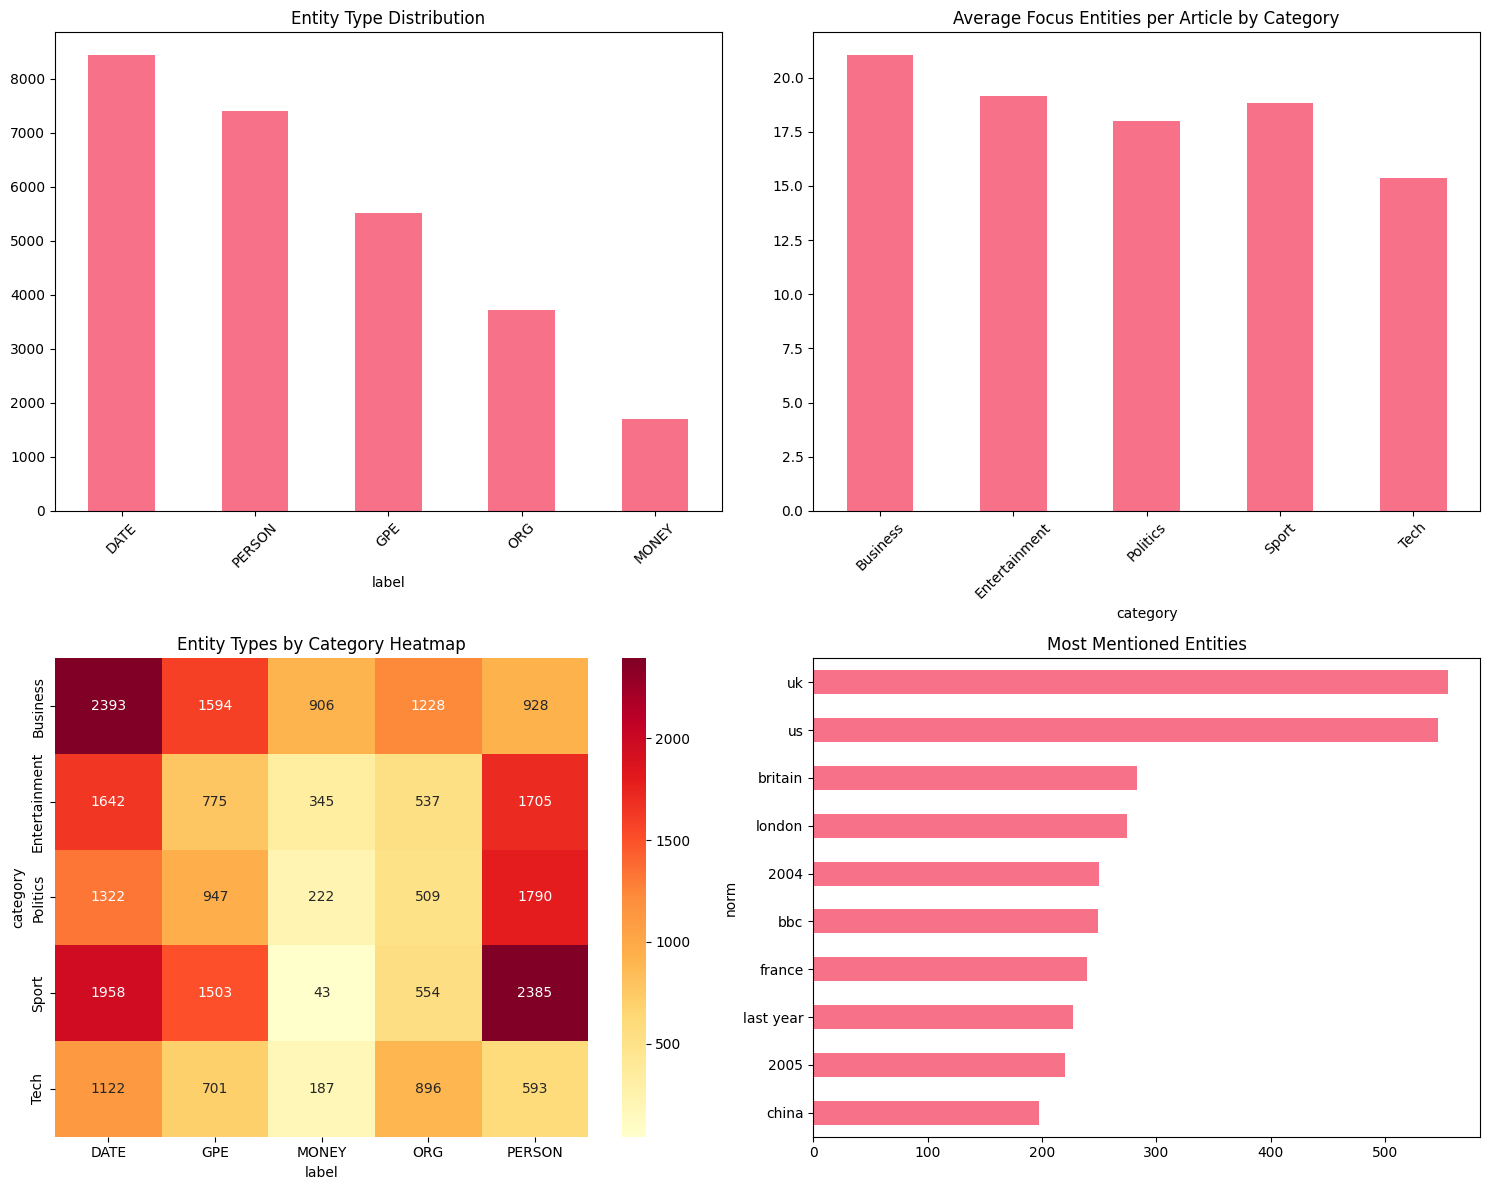

In [ ]:
# Analyze entity patterns (focus types: PERSON, ORG, GPE, DATE, MONEY)
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities (normalized text)
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['norm', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0, 0])
    axes[0, 0].set_title('Entity Type Distribution')
    axes[0, 0].tick_params(axis='x', rotation=45)

    # 2. Entities per article by category (fairer than totals: categories differ in size)
    entities_per_article = entities_df.groupby('category').size() / df['category'].value_counts()
    entities_per_article.plot(kind='bar', ax=axes[0, 1])
    axes[0, 1].set_title('Average Focus Entities per Article by Category')
    axes[0, 1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1, 0], cmap='YlOrRd')
    axes[1, 0].set_title('Entity Types by Category Heatmap')

    # 4. Top entities
    top_entities = entities_df['norm'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1, 1])
    axes[1, 1].set_title('Most Mentioned Entities')
    axes[1, 1].invert_yaxis()

    plt.tight_layout()
    save_figure('m8_entity_overview', fig)
    plt.show()
else:
    print("⚠️ No entities found – check the spaCy pass.")

In [ ]:
# How reliable is NER here? Casing demo + inspection of frequent entities
demo_lower = "tony blair met microsoft boss bill gates in london on monday to discuss a £2bn deal."
demo_cased = "Tony Blair met Microsoft boss Bill Gates in London on Monday to discuss a £2bn deal."
print("🔠 SAME SENTENCE, DIFFERENT CASING")
for label, sentence in [('lowercase (like BBC data)', demo_lower), ('original casing', demo_cased)]:
    found = [(e['text'], e['label']) for e in extract_entities(sentence)]
    print(f"  {label:<26} → {found}")

print("\n📏 Focus entities per article:")
print(entities_df.groupby('article_id').size().reindex(df['article_id'], fill_value=0).describe().round(1))
n_none = (entities_df.groupby('article_id').size().reindex(df['article_id'], fill_value=0) == 0).sum()
print(f"   Articles with NO focus entity: {n_none}")

print("\n🔎 MOST FREQUENT ENTITIES PER TYPE (check for errors yourself)")
for label in FOCUS_ENTITY_TYPES:
    top = entities_df[entities_df['label'] == label]['norm'].value_counts().head(10)
    print(f"  {label:<7} {', '.join(top.index)}")

print("\n🎲 Random sample of 10 entities (with context):")
for _, e in entities_df.sample(min(10, len(entities_df)), random_state=RANDOM_STATE).iterrows():
    text = df.loc[df['article_id'] == e['article_id'], 'full_text'].iloc[0]
    context = text[max(0, e['start'] - 30): e['end'] + 30].replace('\n', ' ')
    print(f"  {e['text']!r:<22} {e['label']:<7} …{context}…")

🔠 SAME SENTENCE, DIFFERENT CASING
  lowercase (like BBC data)  → [('tony blair', 'PERSON'), ('microsoft boss', 'ORG'), ('london', 'GPE'), ('monday', 'DATE'), ('2bn', 'MONEY')]
  original casing            → [('Tony Blair', 'PERSON'), ('Microsoft', 'ORG'), ('Bill Gates', 'PERSON'), ('London', 'GPE'), ('Monday', 'DATE'), ('2bn', 'MONEY')]

📏 Focus entities per article:
count    1432.0
mean       18.7
std        10.3
min         1.0
25%        12.0
50%        17.0
75%        23.0
max       118.0
dtype: float64
   Articles with NO focus entity: 0

🔎 MOST FREQUENT ENTITIES PER TYPE (check for errors yourself)
  PERSON  blair, eu, tony blair, michael howard, gordon brown, yukos, kennedy, williams, bush, howard
  ORG     bbc, microsoft, bbc news, sony, mci, gm, yahoo, google, campbell, european union
  GPE     uk, us, britain, london, france, china, england, india, japan, italy
  DATE    2004, last year, 2005, this year, 2003, sunday, tuesday, wednesday, friday, monday
  MONEY   million dolla

🤝 TOP 10 CO-OCCURRING ENTITY PAIRS (number of shared articles)
  uk (GPE) ↔ britain (GPE): 74
  uk (GPE) ↔ london (GPE): 71
  uk (GPE) ↔ us (GPE): 65
  tony blair (PERSON) ↔ blair (PERSON): 56
  britain (GPE) ↔ tony blair (PERSON): 37
  uk (GPE) ↔ bbc (ORG): 33
  uk (GPE) ↔ bbc news (ORG): 33
  britain (GPE) ↔ blair (PERSON): 33
  uk (GPE) ↔ tony blair (PERSON): 31
  us (GPE) ↔ new york (GPE): 31
🖼️ Figure saved: m8_cooccurrence_heatmap.png


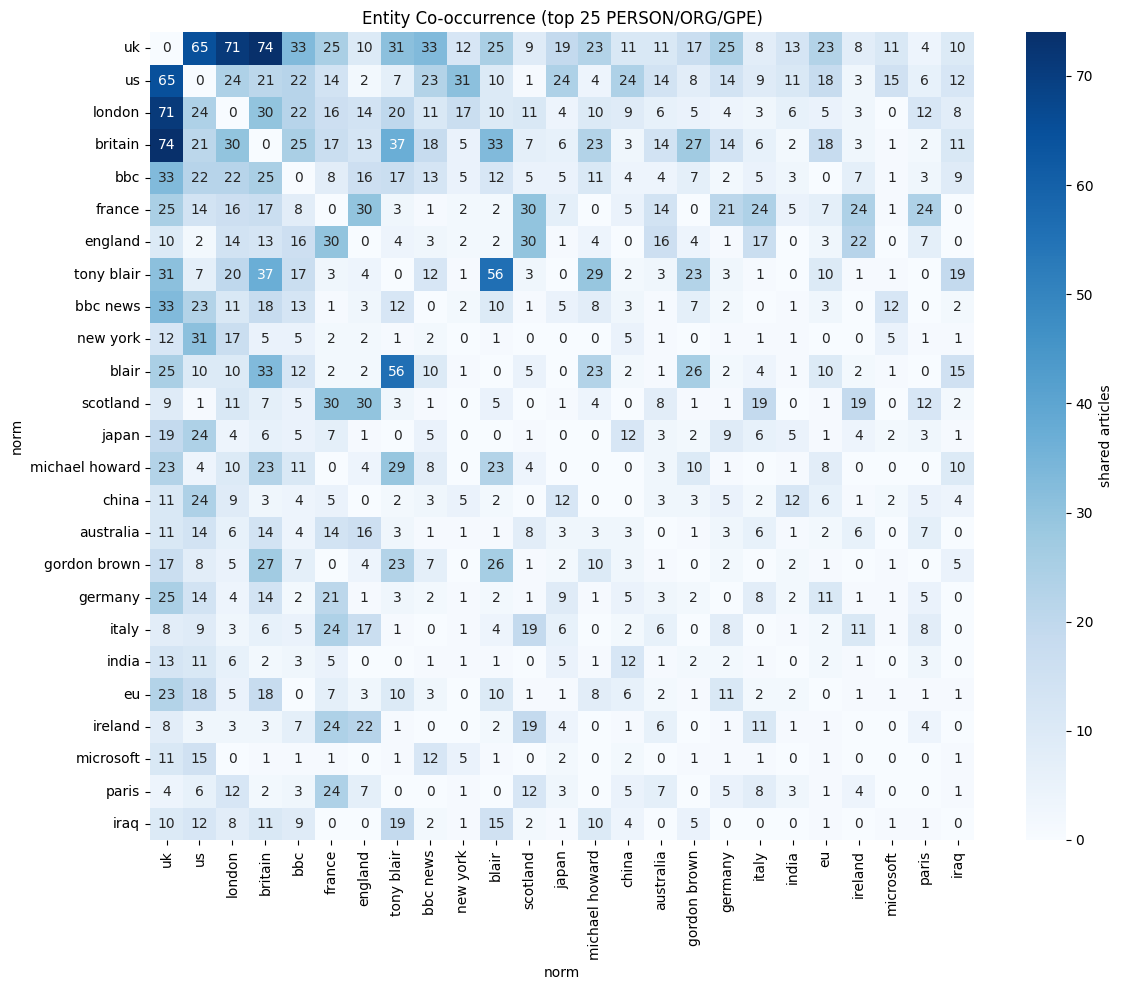

🖼️ Figure saved: m8_cooccurrence_network.png


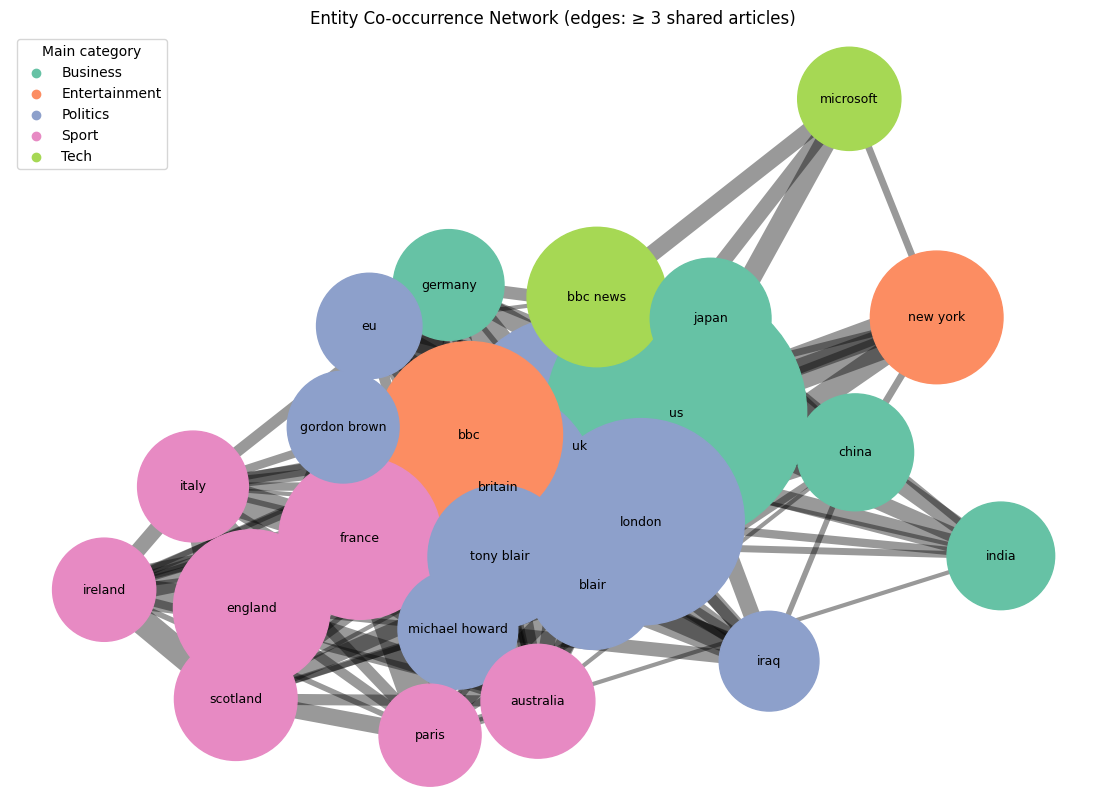

🕸️ Network: 25 entities, 182 links


In [ ]:
# 💡 STUDENT TASK: entity co-occurrence network (top PERSON / ORG / GPE entities)
TOP_N_ENTITIES = 25
MIN_COOCCURRENCE = 2 if SAMPLE_MODE else 3

top_entity_counts = key_entities_df.groupby('norm')['article_id'].nunique().nlargest(TOP_N_ENTITIES)
entity_main_category = key_entities_df.groupby('norm')['category'].agg(lambda s: s.value_counts().idxmax())
entity_type = key_entities_df.groupby('norm')['label'].agg(lambda s: s.value_counts().idxmax())

# Count how often two top entities appear in the same article
article_sets = (key_entities_df[key_entities_df['norm'].isin(top_entity_counts.index)]
                .groupby('article_id')['norm'].apply(set))
cooc = pd.DataFrame(0, index=top_entity_counts.index, columns=top_entity_counts.index)
for ents in article_sets:
    for a in ents:
        for b in ents:
            if a != b:
                cooc.loc[a, b] += 1

pairs = [(a, b, cooc.loc[a, b]) for i, a in enumerate(cooc.index) for b in cooc.columns[i + 1:] if cooc.loc[a, b] > 0]
pairs = sorted(pairs, key=lambda x: -x[2])
print("🤝 TOP 10 CO-OCCURRING ENTITY PAIRS (number of shared articles)")
for a, b, w in pairs[:10]:
    print(f"  {a} ({entity_type[a]}) ↔ {b} ({entity_type[b]}): {w}")

plt.figure(figsize=(12, 10))
sns.heatmap(cooc, cmap='Blues', annot=cooc.values, fmt='d', cbar_kws={'label': 'shared articles'})
plt.title(f'Entity Co-occurrence (top {TOP_N_ENTITIES} PERSON/ORG/GPE)')
plt.tight_layout()
save_figure('m8_cooccurrence_heatmap')
plt.show()

# Network graph (networkx is preinstalled in Colab; the heatmap above is the fallback)
try:
    import networkx as nx
    G = nx.Graph()
    for ent, n_art in top_entity_counts.items():
        G.add_node(ent, size=n_art, category=entity_main_category[ent])
    for a, b, w in pairs:
        if w >= MIN_COOCCURRENCE:
            G.add_edge(a, b, weight=w)
    G.remove_nodes_from([n for n in list(G.nodes) if G.degree(n) == 0])   # hide isolated entities

    palette = dict(zip(categories, sns.color_palette('Set2', len(categories))))
    pos = nx.spring_layout(G, k=0.8, seed=RANDOM_STATE)
    plt.figure(figsize=(14, 10))
    nx.draw_networkx_edges(G, pos, width=[G[u][v]['weight'] for u, v in G.edges], alpha=0.4)
    nx.draw_networkx_nodes(G, pos, node_size=[G.nodes[n]['size'] * 120 for n in G.nodes],
                           node_color=[palette[G.nodes[n]['category']] for n in G.nodes])
    nx.draw_networkx_labels(G, pos, font_size=9)
    for cat, color in palette.items():
        plt.scatter([], [], color=color, label=cat)
    plt.legend(title='Main category', loc='upper left')
    plt.title(f'Entity Co-occurrence Network (edges: ≥ {MIN_COOCCURRENCE} shared articles)')
    plt.axis('off')
    save_figure('m8_cooccurrence_network')
    plt.show()
    print(f"🕸️ Network: {G.number_of_nodes()} entities, {G.number_of_edges()} links")
except ImportError:
    print("ℹ️ networkx not available – the co-occurrence heatmap above shows the same information.")

🔗 Relations between two named entities: 258 (of 17230 SVO triples)
        source    action    target  count category
lord goldsmith      warn     blair      4 Politics
 lord falconer      tell bbc radio      3 Politics
        miller  easterby   k maggs      3    Sport
        howard      tell       mps      2 Politics
            us      push     japan      2     Tech
        peston      tell  bbc news      2 Politics
           mps criticise     blair      2 Politics
michael howard    accuse     blair      2 Politics
         brown      tell     blair      2 Politics
         brown      tell       mps      2 Politics
      driscoll    horgan   connell      2    Sport
     argentina     shock   ireland      1    Sport
  alan milburn      join     brown      1 Politics
   alan duncan    accuse     brown      1 Politics
     allardyce      sign   candela      1    Sport
🖼️ Figure saved: m8_relationship_graph.png


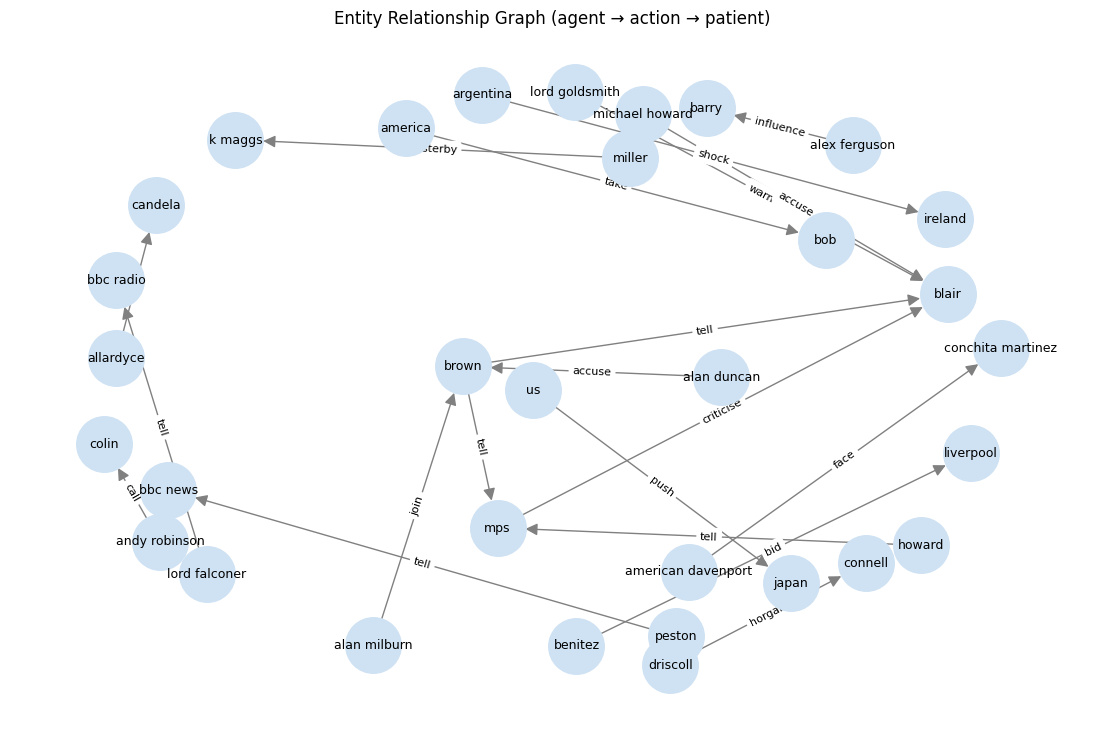

In [ ]:
# 💡 STUDENT TASK: entity relationship graph – "who did what to whom" between NAMED entities
if 'svo_df' not in globals():
    svo_df = load_object('svo_triples')
known_entities = set(key_entities_df['norm'])


def match_entity(phrase):
    """Map an SVO phrase to a known entity: full phrase, else its last 3/2/1 words ('prime minister tony blair' -> 'tony blair')."""
    p = normalize_entity(phrase)
    if p in known_entities:
        return p
    words = p.split()
    for n in (3, 2, 1):
        candidate = ' '.join(words[-n:])
        if len(words) >= n and candidate in known_entities:
            return candidate
    return None


relations = svo_df.assign(source=svo_df['agent'].map(match_entity),
                          target=svo_df['patient'].map(match_entity)).dropna(subset=['source', 'target'])
relations = relations[relations['source'] != relations['target']]
print(f"🔗 Relations between two named entities: {len(relations)} (of {len(svo_df)} SVO triples)")

rel_summary = (relations.groupby(['source', 'action', 'target'])
               .agg(count=('article_id', 'size'), category=('category', lambda s: s.value_counts().idxmax()))
               .reset_index().sort_values('count', ascending=False))
print(rel_summary.head(15).to_string(index=False))

try:
    import networkx as nx
    top_rel = rel_summary.head(20)
    if not top_rel.empty:
        D = nx.DiGraph()
        for _, r in top_rel.iterrows():
            D.add_edge(r['source'], r['target'], label=r['action'])
        pos = nx.spring_layout(D, k=1.2, seed=RANDOM_STATE)
        plt.figure(figsize=(14, 9))
        nx.draw_networkx(D, pos, node_color='#cfe2f3', node_size=1600, font_size=9,
                         arrows=True, arrowsize=18, edge_color='gray')
        nx.draw_networkx_edge_labels(D, pos, edge_labels=nx.get_edge_attributes(D, 'label'), font_size=8)
        plt.title('Entity Relationship Graph (agent → action → patient)')
        plt.axis('off')
        save_figure('m8_relationship_graph')
        plt.show()
except ImportError:
    print("ℹ️ networkx not available – see the relation table above.")

😐 Average sentence-level sentiment of all articles: 0.100
   Entities mentioned in ≥ 5 articles: 331

😊 ENTITIES IN THE MOST POSITIVE COVERAGE
           norm  label  n_articles  mean_sentiment  share_negative
  paul giamatti PERSON           6           0.607             0.0
     jamie foxx PERSON          12           0.517             0.0
imelda staunton PERSON          16           0.503             0.0
     mike leigh PERSON           8           0.496             0.0
          franz    ORG          11           0.410             0.0
    ray charles PERSON          13           0.403             0.0
       ethiopia    GPE           8           0.387             0.0
   harry potter PERSON          10           0.387             0.0
 jason gardener PERSON           6           0.376             0.0
    alicia keys PERSON           5           0.367             0.0

😞 ENTITIES IN THE MOST NEGATIVE COVERAGE
          norm  label  n_articles  mean_sentiment  share_negative
scott sulliv

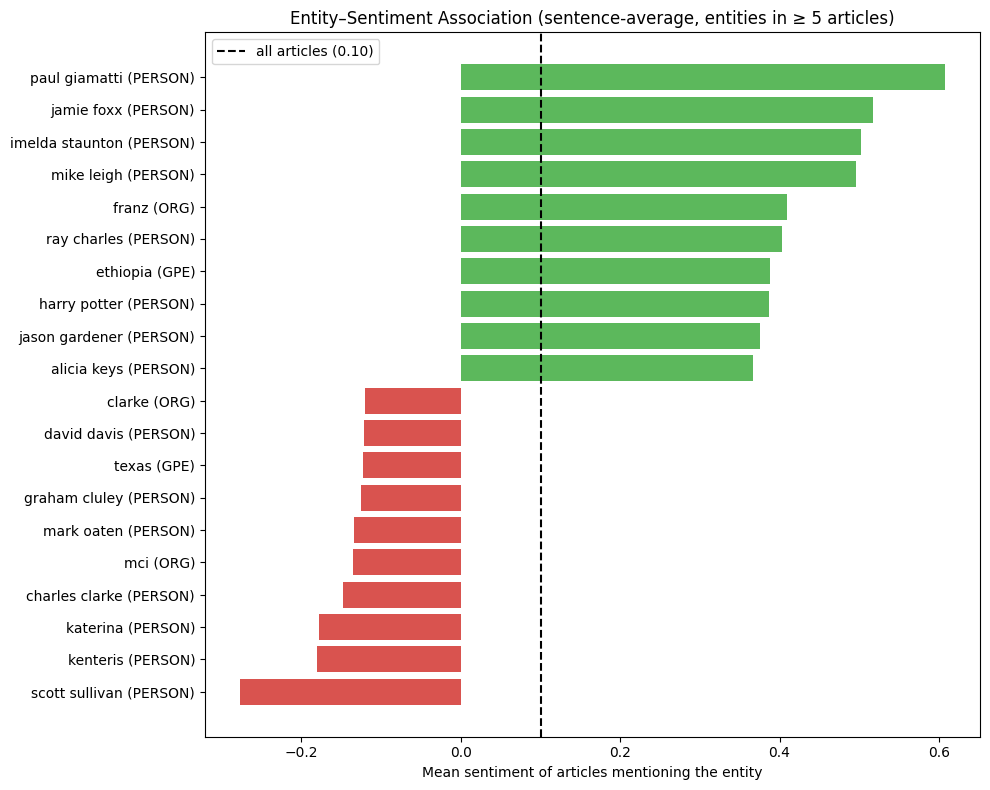

In [ ]:
# 💡 STUDENT TASK: which entities appear in positive vs. negative articles?
MIN_ARTICLES = 3 if SAMPLE_MODE else 5

entity_articles = key_entities_df[['norm', 'label', 'article_id']].drop_duplicates()
entity_sentiment = entity_articles.merge(
    sentiment_df[['article_id', 'avg_sentence_sentiment', 'sentence_label']], on='article_id')
entity_sent_summary = (entity_sentiment.groupby(['norm', 'label'])
                       .agg(n_articles=('article_id', 'nunique'),
                            mean_sentiment=('avg_sentence_sentiment', 'mean'),
                            share_negative=('sentence_label', lambda s: (s == 'negative').mean()))
                       .reset_index())
entity_sent_summary = entity_sent_summary[entity_sent_summary['n_articles'] >= MIN_ARTICLES]

overall = sentiment_df['avg_sentence_sentiment'].mean()
print(f"😐 Average sentence-level sentiment of all articles: {overall:.3f}")
print(f"   Entities mentioned in ≥ {MIN_ARTICLES} articles: {len(entity_sent_summary)}")
top_pos = entity_sent_summary.nlargest(10, 'mean_sentiment')
top_neg = entity_sent_summary.nsmallest(10, 'mean_sentiment')
print("\n😊 ENTITIES IN THE MOST POSITIVE COVERAGE")
print(top_pos.round(3).to_string(index=False))
print("\n😞 ENTITIES IN THE MOST NEGATIVE COVERAGE")
print(top_neg.round(3).to_string(index=False))

plot_df = pd.concat([top_pos, top_neg]).drop_duplicates('norm').sort_values('mean_sentiment')
plt.figure(figsize=(10, 8))
plt.barh(plot_df['norm'] + ' (' + plot_df['label'] + ')', plot_df['mean_sentiment'],
         color=['#d9534f' if v < overall else '#5cb85c' for v in plot_df['mean_sentiment']])
plt.axvline(overall, color='black', linestyle='--', label=f'all articles ({overall:.2f})')
plt.title(f'Entity–Sentiment Association (sentence-average, entities in ≥ {MIN_ARTICLES} articles)')
plt.xlabel('Mean sentiment of articles mentioning the entity')
plt.legend()
plt.tight_layout()
save_figure('m8_entity_sentiment')
plt.show()

📊 AVERAGE ENTITIES OF EACH TYPE PER ARTICLE
label          PERSON   ORG   GPE  DATE  MONEY
category                                      
Business         2.77  3.67  4.76  7.14   2.70
Entertainment    6.53  2.06  2.97  6.29   1.32
Politics         6.73  1.91  3.56  4.97   0.83
Sport            6.97  1.62  4.39  5.73   0.13
Tech             2.60  3.93  3.07  4.92   0.82
🖼️ Figure saved: m8_entity_types_by_category.png


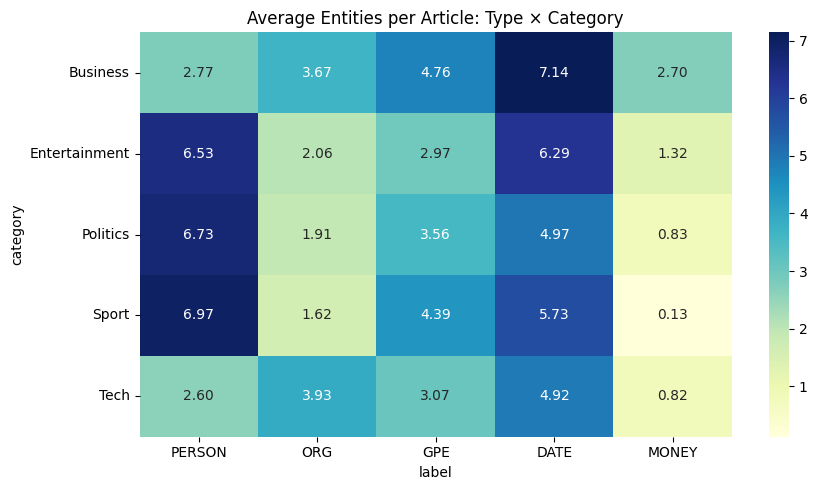


🏆 TOP 5 KEY ENTITIES PER CATEGORY (by number of articles)
  Business       us (GPE, 126), uk (GPE, 67), china (GPE, 42), london (GPE, 35), india (GPE, 34)
  Entertainment  uk (GPE, 73), us (GPE, 70), london (GPE, 49), bbc (ORG, 37), los angeles (GPE, 36)
  Politics       britain (GPE, 91), uk (GPE, 84), tony blair (PERSON, 83), blair (PERSON, 65), michael howard (PERSON, 62)
  Sport          france (GPE, 69), england (GPE, 64), scotland (GPE, 41), bbc (ORG, 39), ireland (GPE, 33)
  Tech           uk (GPE, 72), us (GPE, 65), bbc news (ORG, 44), microsoft (ORG, 44), sony (ORG, 33)

🌉 BRIDGE ENTITIES (appear in ≥ 3 categories): 156
            n_categories  n_articles                                      categories
norm                                                                                
uk                     5         301  Business, Entertainment, Politics, Sport, Tech
us                     5         295  Business, Entertainment, Politics, Sport, Tech
london                

In [ ]:
# 💡 STUDENT TASK: cross-category entity patterns
type_per_article = (entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
                    .div(df['category'].value_counts(), axis=0)[FOCUS_ENTITY_TYPES])
print("📊 AVERAGE ENTITIES OF EACH TYPE PER ARTICLE")
print(type_per_article.round(2))

plt.figure(figsize=(9, 5))
sns.heatmap(type_per_article, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Average Entities per Article: Type × Category')
plt.tight_layout()
save_figure('m8_entity_types_by_category')
plt.show()

print("\n🏆 TOP 5 KEY ENTITIES PER CATEGORY (by number of articles)")
for cat in categories:
    sub = key_entities_df[key_entities_df['category'] == cat]
    top = sub.groupby(['norm', 'label'])['article_id'].nunique().nlargest(5)
    print(f"  {cat:<14} " + ', '.join(f"{n} ({l}, {c})" for (n, l), c in top.items()))

# "Bridge" entities: named in 3+ different categories
spread = key_entities_df.groupby('norm').agg(n_categories=('category', 'nunique'),
                                             n_articles=('article_id', 'nunique'),
                                             categories=('category', lambda s: ', '.join(sorted(set(s)))))
bridges = spread[spread['n_categories'] >= 3].sort_values(['n_categories', 'n_articles'], ascending=False)
print(f"\n🌉 BRIDGE ENTITIES (appear in ≥ 3 categories): {len(bridges)}")
print(bridges.head(12).to_string())

### 🔍 Named Entity Findings (my interpretation)

**Overview:** spaCy found 39,687 entities in total, 26,785 of the five focus types. The most common type is DATE (8,437), followed by PERSON (7,401), GPE (5,520), ORG (3,724) and MONEY (1,703). Business has the most focus entities per article (≈21.0), followed by Entertainment (≈19.2) and Sport (≈18.8); Tech has the fewest (≈15.3). Every article contains at least 1 focus entity (median 17).

**NER quality (small model + lowercased text):** In the casing demo, the lowercase sentence gave 5 entities and the original-casing version 6: the lowercase version missed "Bill Gates" completely and returned "microsoft boss" instead of "Microsoft" as the ORG. Errors I found in the frequent/sample lists: "eu" labelled as PERSON instead of ORG (it is the second most frequent PERSON, after "blair"), and "ludovico nitoglia", a rugby player, labelled as GPE instead of PERSON. This means lowercasing can reduce named entity recognition accuracy because capitalization provides an important clue for distinguishing people, organizations, and common words. The small spaCy model can also make mistakes when identifying entity boundaries and types.

**Co-occurrence:** The strongest pair was uk ↔ britain (74 shared articles), followed by uk ↔ london (71) and uk ↔ us (65); the strongest person pair was tony blair ↔ blair (56), which is actually the same person counted under two names. The network (25 entities, 182 links) shows clusters for geographical locations such as the UK, London, and Britain, as well as political figures such as Tony Blair and Michael Howard, which reflects how news articles often discuss related places, people, and organizations together. These connections can reveal recurring topics and relationships across the dataset.

**Relationships:** 258 relations connected two named entities (out of 17,230 SVO triples); the most frequent was lord goldsmith → warn → blair (4 times), and us → push → japan appeared twice. An interesting one was "US → push → Japan", which shows how subject–verb–object extraction can identify a potential relationship between countries and an action. However, the extracted triple lacks the surrounding context needed to understand exactly what happened, so it should be checked against the original sentence.

**Entity–sentiment:** Average sentence-level sentiment of all articles is 0.100 (331 entities appear in ≥ 5 articles). Entities in the most positive coverage: paul giamatti (0.607, 6 articles), jamie foxx (0.517, 12), imelda staunton (0.503, 16), mike leigh (0.496), ray charles (0.403); most negative: scott sullivan (−0.277, all 5 articles negative), kenteris (−0.181), katerina (−0.179), charles clarke (−0.148, 18 articles), mci (−0.135), mark oaten (−0.134). This does not mean these entities are viewed negatively, because the scores measure the sentiment of the articles mentioning them, not necessarily the sentiment expressed toward the entities themselves. For example, a negative article about a political controversy might mention a politician without criticizing that person directly. The results also depend on how sentiment is measured and the topics covered in the dataset.

**Cross-category patterns:** Sport uses the most PERSON entities per article (6.97, just ahead of Politics with 6.73), Business the most MONEY (2.70), DATE (7.14) and GPE (4.76), and Tech the most ORG (3.93). 156 bridge entities appear in ≥ 3 categories; 30 appear in all five, including uk, us, london, britain, bbc, france, england and tony blair, which shows that some people, places, and organizations are relevant across multiple news topics. These shared entities help connect categories, but may be less useful for distinguishing one category from another.

**Business value:** For my target users, entity tracking could identify frequently mentioned companies, people, and locations; monitor how their coverage changes over time; detect relationships between organizations and events; and generate alerts when a company appears in negative coverage. Combining entity recognition with sentiment analysis and category classification could help users find relevant news more quickly, although alerts should be reviewed in context to avoid misleading conclusions.

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [ ]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses (Modules 1–8).

    Returns a dictionary of FACTS computed from the results. Business recommendations are
    deliberately not hard-coded: I write them myself in the markdown cell below, based on these facts.
    """
    insights = {
        'dataset_overview': {}, 'classification_performance': {}, 'sentiment_insights': {},
        'emotion_insights': {}, 'entity_insights': {}, 'linguistic_patterns': {},
        'business_recommendations': [],      # -> see my markdown cell "Business Recommendations"
    }

    # Dataset overview
    insights['dataset_overview'] = {
        'run': RUN_TAG,
        'total_articles': len(df),
        'categories': sorted(df['category'].unique().tolist()),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean(),
    }

    # Classification performance (final model = tuned pipeline from Module 7)
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'feature_set': BEST_FEATURE_SET,
        'best_accuracy': results[best_model_name]['accuracy'],
        'test_macro_f1': f1_score(y_test, best_predictions, average='macro'),
        'cv_macro_f1': grid_search.best_score_,
        'n_test_articles': len(y_test),
        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()},
    }

    # Sentiment insights (main measure: sentence-average, chosen in Module 6)
    sent_cat = sentiment_df.groupby('category')['avg_sentence_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'measure': 'avg_sentence_sentiment',
        'most_positive_category': max(sent_cat, key=sent_cat.get),
        'most_negative_category': min(sent_cat, key=sent_cat.get),
        'sentiment_by_category': sent_cat,
        'overall_sentiment': sentiment_df['avg_sentence_sentiment'].mean(),
        'whole_article_saturation_share': (sentiment_df['full_sentiment'].abs() > 0.9).mean(),
    }

    # Emotion insights
    emo_cat = emotion_df.groupby('category')[EMOTIONS].mean()
    insights['emotion_insights'] = {
        'backend': EMOTION_BACKEND,
        'strongest_emotion_per_category': emo_cat.idxmax(axis=1).to_dict(),
        'second_emotion_per_category': {c: emo_cat.loc[c].nlargest(2).index[1] for c in emo_cat.index},
        'category_with_most_of_each_emotion': emo_cat.idxmax(axis=0).to_dict(),
    }

    # Entity insights
    if not entities_df.empty:
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['norm'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entities_df.groupby('category').size().to_dict(),
            'most_mentioned_entities': entities_df['norm'].value_counts().head(5).to_dict(),
            'bridge_entities_in_all_categories':
                spread[spread['n_categories'] == df['category'].nunique()].index.tolist(),
        }

    # Linguistic patterns (POS / style from Module 4, syntax from Module 5)
    syn_cat = syntax_df.groupby('category')[['avg_tree_depth', 'passive_sentence_share']].mean()
    insights['linguistic_patterns'] = {
        'highest_noun_verb_ratio': style_by_category['noun_verb_ratio'].idxmax(),
        'most_numbers': style_by_category['num_share'].idxmax(),
        'fewest_numbers': style_by_category['num_share'].idxmin(),
        'longest_sentences': style_by_category['avg_sentence_length'].idxmax(),
        'shortest_sentences': style_by_category['avg_sentence_length'].idxmin(),
        'deepest_parse_trees': syn_cat['avg_tree_depth'].idxmax(),
        'most_passive_voice': syn_cat['passive_sentence_share'].idxmax(),
        'syntax_style_only_accuracy': ling_scores.mean(),
    }
    return insights


# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()
print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

overview = analysis_results['dataset_overview']
print(f"\n📊 DATASET OVERVIEW ({overview['run']} run):")
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

perf = analysis_results['classification_performance']
print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
print(f"  Best Model: {perf['best_model']} ({perf['feature_set']})")
print(f"  Test Accuracy: {perf['best_accuracy']:.4f} | Test macro-F1: {perf['test_macro_f1']:.4f} "
      f"| CV macro-F1: {perf['cv_macro_f1']:.4f} ({perf['n_test_articles']} test articles)")

sent = analysis_results['sentiment_insights']
print(f"\n😊 SENTIMENT INSIGHTS (sentence-average):")
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")
print(f"  Whole-article scores beyond ±0.9: {sent['whole_article_saturation_share']:.1%}")

emo = analysis_results['emotion_insights']
print(f"\n🎭 EMOTION INSIGHTS ({emo['backend']}):")
for cat, e1 in emo['strongest_emotion_per_category'].items():
    print(f"  {cat:<14} strongest: {e1:<13} second: {emo['second_emotion_per_category'][cat]}")

if analysis_results['entity_insights']:
    ent = analysis_results['entity_insights']
    print(f"\n🔍 ENTITY INSIGHTS:")
    print(f"  Total Entities: {ent['total_entities']} | Unique: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")
    print(f"  Most mentioned: {', '.join(ent['most_mentioned_entities'].keys())}")
    print(f"  In all categories: {', '.join(ent['bridge_entities_in_all_categories'])}")

ling = analysis_results['linguistic_patterns']
print(f"\n✍️ LINGUISTIC PATTERNS:")
print(f"  Highest noun/verb ratio: {ling['highest_noun_verb_ratio']} | Most numbers: {ling['most_numbers']} "
      f"| Fewest numbers: {ling['fewest_numbers']}")
print(f"  Longest sentences: {ling['longest_sentences']} | Shortest: {ling['shortest_sentences']}")
print(f"  Deepest parse trees: {ling['deepest_parse_trees']} | Most passive voice: {ling['most_passive_voice']}")
print(f"  Accuracy from syntax/style features only: {ling['syntax_style_only_accuracy']:.3f}")

print("\n💡 BUSINESS RECOMMENDATIONS: see my markdown cell below (written from these results).")

# Save all facts as JSON (for the README / report)
summary_path = PROJECT_DIR / 'results' / f'insights_summary_{RUN_TAG}.json'
summary_path.write_text(json.dumps(analysis_results, indent=2,
                                   default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
print(f"\n💾 Insights saved: {summary_path.name}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW (full run):
  Total Articles: 1432
  Categories: Business, Entertainment, Politics, Sport, Tech
  Average Article Length: 2221 characters
  Average Words per Article: 380 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: Linear SVM (tuned) (TF-IDF + sentiment + length)
  Test Accuracy: 0.9617 | Test macro-F1: 0.9582 | CV macro-F1: 0.9801 (287 test articles)

😊 SENTIMENT INSIGHTS (sentence-average):
  Most Positive Category: Entertainment
  Most Negative Category: Politics
  Overall Sentiment: 0.1004
  Whole-article scores beyond ±0.9: 70.4%

🎭 EMOTION INSIGHTS (nrclex):
  Business       strongest: trust         second: anticipation
  Entertainment  strongest: trust         second: anticipation
  Politics       strongest: trust         second: anticipation
  Sport          strongest: trust         second: anticipation
  Tech           strongest: trust   

🖼️ Figure saved: summary_dashboard.png


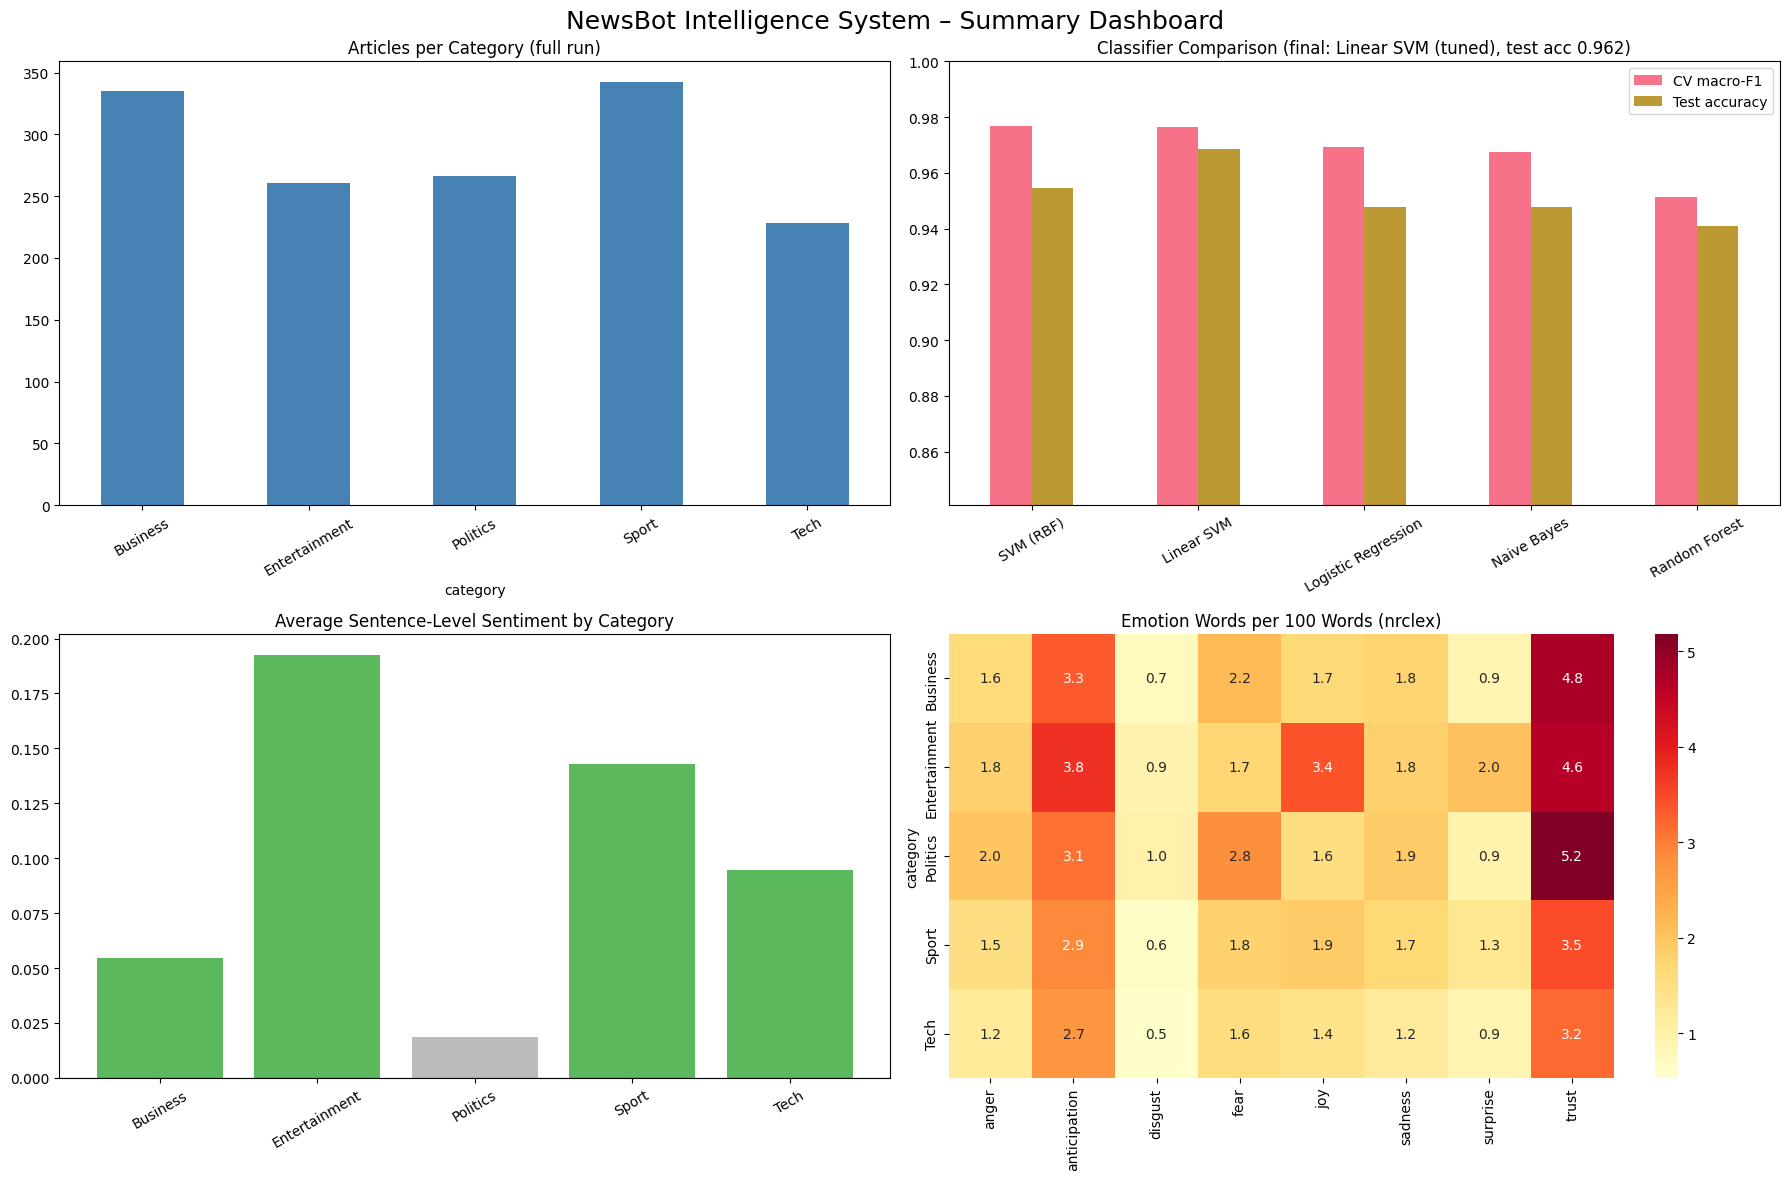

In [ ]:
# Summary dashboard – the key results in one figure
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

df['category'].value_counts().reindex(categories).plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title(f'Articles per Category ({RUN_TAG} run)')
axes[0, 0].tick_params(axis='x', rotation=30)

comparison_df[['cv_f1', 'test_accuracy']].plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_ylim(max(0, comparison_df[['cv_f1', 'test_accuracy']].values.min() - 0.1), 1.0)
axes[0, 1].set_title(f'Classifier Comparison (final: {best_model_name}, test acc {perf["best_accuracy"]:.3f})')
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].legend(['CV macro-F1', 'Test accuracy'])

sent_series = pd.Series(sent['sentiment_by_category']).reindex(categories)
axes[1, 0].bar(sent_series.index, sent_series.values,
               color=['#5cb85c' if v >= 0.05 else '#d9534f' if v <= -0.05 else '#bbbbbb' for v in sent_series])
axes[1, 0].axhline(0, color='black', linewidth=0.8)
axes[1, 0].set_title('Average Sentence-Level Sentiment by Category')
axes[1, 0].tick_params(axis='x', rotation=30)

sns.heatmap(emotion_df.groupby('category')[EMOTIONS].mean() * 100, annot=True, fmt='.1f',
            cmap='YlOrRd', ax=axes[1, 1])
axes[1, 1].set_title(f'Emotion Words per 100 Words ({EMOTION_BACKEND})')

plt.suptitle('NewsBot Intelligence System – Summary Dashboard', fontsize=18)
plt.tight_layout()
save_figure('summary_dashboard', fig)
plt.show()

### 💡 Business Recommendations (my own, based on the results above)

*Target users (from my business case):* **Journalists, news readers, and media analysts who need to categorize articles, monitor important entities, and identify trends across different news topics.**

| # | Finding (with number) | Recommendation | Who benefits | Caveat / risk |
|---|---|---|---|---|
| 1 | **Classification:** 96.2% test accuracy (macro-F1 0.958, CV macro-F1 0.980, 287 test articles); the weakest class is Tech (F1 0.920); Business → Politics is the most common confusion (7 of 32 errors incl. out-of-fold predictions), and Tech is involved in 17 of the 32 errors. | **Use Linear SVM with TF-IDF + sentiment + length features to automatically categorize articles, but send low-confidence predictions and Business–Politics and Tech-related ambiguities for human review.** | Journalists, editors, and readers who need articles organized by topic. | The test set contains 287 articles from a single source (BBC). More testing on a larger and more diverse dataset is needed before production use. |
| 2 | **Sentiment:** Politics is the most negative category (sentence-average 0.019, inside VADER's neutral range) and Entertainment the most positive (0.192); Business (0.054) is just above the neutral range; 70.4% of whole-article scores saturate beyond ±0.9. | **Use sentence-level sentiment to summarize the general tone of news categories and identify potentially positive or negative coverage. Avoid relying on whole-article scores alone.** | Media analysts, journalists, and readers interested in tracking trends in news sentiment. | Sentiment tools can misinterpret context and neutral reporting. Article sentiment does not necessarily represent an author's opinion or whether a mentioned person or company is viewed negatively. |
| 3 | **Entities:** 26,785 focus entities (8,559 unique); most mentioned: UK, US, Britain, London, 2004; 30 entities appear in all five categories; NER errors occur on lowercased text (e.g., "EU" as PERSON); UK politicians appear in some of the most negative coverage (e.g., Charles Clarke −0.148, Mark Oaten −0.134). | **Build entity tracking to identify frequently mentioned people, organizations, and locations, and generate alerts when relevant entities appear in new or potentially negative coverage.** | Journalists, media monitoring teams, businesses, and public relations professionals. | Named entity recognition can mislabel entities, especially in lowercased text. Sentiment reflects the surrounding articles, not necessarily sentiment toward the entity itself. Alerts should be verified in context. |
| 4 | **Emotions / linguistic patterns:** Trust is the strongest and anticipation the second-strongest emotion in all five categories; Politics has the deepest parse trees, the most passive voice and the longest sentences; syntax/style features alone reach 56.0% accuracy; adding POS/syntax features to TF-IDF lowered macro-F1 slightly (−0.003), while sentiment + length raised it slightly (+0.004). | **Use emotion and linguistic features for supplementary analysis and reporting, but keep TF-IDF as the primary classification feature. Explore whether these additional features provide value for specific analytical tasks rather than automatically combining them with the classifier.** | Researchers, journalists, and analysts who study writing styles, reporting patterns, and emotional language. | The emotion lexicon may misinterpret words without context, and similar grammatical patterns occur across categories. Adding more features can reduce classification performance rather than improve it. |

**What I would NOT recommend yet, and why:**

I would not recommend using NewsBot for fully automated editorial decisions or treating its sentiment and entity scores as definitive judgments about people, companies, or political issues. Although the classifier achieved 96.2% test accuracy, the test set contains only 287 articles from a single source, and the Tech and Business categories are involved in most of the observed classification errors (17 and 16 of 32), either as the true or as the predicted label. Sentiment and emotion analysis can also misinterpret context, while named entity recognition may produce incorrect labels. Before deployment, I would test the system on a larger and more diverse dataset, monitor its errors, and include human review for uncertain predictions. I would also avoid adding all linguistic features to the classifier without further testing because they reduced macro-F1 in the experiments.

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Deployment note:** This pipeline could be deployed as a web service, batch processor, or integrated into content management systems, but low-confidence predictions should still go to human review (see my Business Recommendations).

In [ ]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    Encapsulates:
    - preprocessing (same functions as training: expand_contractions, preprocess_text)
    - the saved classification pipeline (TF-IDF [+ numeric features] -> classifier)
    - entity extraction, sentiment, emotion and keyword analysis
    - insight generation

    Features for classification are computed EXACTLY as in training (article_feature_row), so
    there are no dummy features. Title is optional (the BBC training data has no separate title).
    """

    def __init__(self, classifier, numeric_cols=None, confidence_threshold=0.8):
        self.classifier = classifier
        self.nlp = nlp                                  # spaCy model
        self.sentiment_analyzer = sia                   # VADER (used by analyze_sentiment)
        self.numeric_cols = list(FINAL_NUMERIC_COLS if numeric_cols is None else numeric_cols)
        self.confidence_threshold = confidence_threshold
        try:   # fitted TF-IDF vectorizer inside the pipeline -> used for keywords
            self.vectorizer = classifier.named_steps['features'].named_transformers_['tfidf']
        except (AttributeError, KeyError):
            self.vectorizer = None

    @classmethod
    def from_saved(cls, model_path, **kwargs):
        """Create the system from the model file saved with joblib in Module 7."""
        return cls(joblib.load(model_path), **kwargs)

    def preprocess_article(self, title, content):
        """Return (raw text with original casing, lowercased text like the training data, processed text)."""
        title = '' if title is None or pd.isna(title) else str(title).strip()
        content = '' if content is None or pd.isna(content) else str(content).strip()
        if title:
            joiner = ' ' if title[-1] in '.!?' else '. '
            full_text = f"{title}{joiner}{content}"
        else:
            full_text = content
        raw_text = expand_contractions(full_text)       # keeps casing -> better NER
        model_text = raw_text.lower()                   # BBC training text is lowercased
        processed_text = preprocess_text(model_text)    # same as Module 2
        return raw_text, model_text, processed_text

    def _model_features(self, model_text, processed_text):
        """Feature table in exactly the format the pipeline was trained on."""
        if self.numeric_cols:
            row = article_feature_row(model_text)        # identical feature code as training
        else:
            row = {'text_processed': processed_text}     # TF-IDF-only model needs just the text
        return pd.DataFrame([row])

    def classify_article(self, model_text, processed_text):
        """Classify article category; returns (prediction, {category: probability})."""
        features = self._model_features(model_text, processed_text)
        prediction = self.classifier.predict(features)[0]
        probabilities = self.classifier.predict_proba(features)[0]
        class_probs = dict(zip(self.classifier.classes_, probabilities))
        return prediction, class_probs

    def extract_entities(self, text):
        """Focus entities (PERSON, ORG, GPE, DATE, MONEY) from the ORIGINAL-casing text, without duplicates."""
        seen, result = set(), []
        for e in extract_entities(text):
            key = (e['text'].lower(), e['label'])
            if e['label'] in FOCUS_ENTITY_TYPES and key not in seen:
                seen.add(key)
                result.append(e)
        return result

    def analyze_sentiment(self, text):
        """VADER whole-text scores + sentence-average (the main measure, see Module 6)."""
        scores = analyze_sentiment(text)
        scores.update(analyze_sentence_sentiment(text))
        scores['sentence_label'] = label_from_compound(scores['avg_sentence_compound'])
        return scores

    def analyze_emotions(self, text, top_n=3):
        """Top NRC emotions (per 100 words, only emotions that actually occur) and their trigger words."""
        profile, triggers = emotion_profile(text)
        ranked = [e for e in sorted(EMOTIONS, key=lambda e: profile[e], reverse=True) if profile[e] > 0]
        return {'dominant': profile['dominant_emotion'],
                'top': [(e, round(profile[e] * 100, 2)) for e in ranked[:top_n]],
                'triggers': {e: list(triggers.get(e, []))[:5] for e in ranked[:top_n]}}

    def extract_keywords(self, processed_text, n=8):
        """Highest TF-IDF terms of the article (vocabulary learned during training)."""
        if self.vectorizer is None or not processed_text:
            return []
        row = self.vectorizer.transform([processed_text]).toarray().ravel()
        vocab = self.vectorizer.get_feature_names_out()
        return [vocab[i] for i in row.argsort()[::-1][:n] if row[i] > 0]

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        Returns: predicted category with confidence, probabilities, entities, sentiment,
        emotions, keywords and insights.
        """
        raw_text, model_text, processed_text = self.preprocess_article(title, content)
        if not processed_text:
            raise ValueError("The article is empty after preprocessing – please provide more text.")

        category, category_probs = self.classify_article(model_text, processed_text)
        entity_text = expand_contractions(str(content)) if content else raw_text
        entities = self.extract_entities(entity_text)    # body only: Title-Case headlines confuse NER
        sentiment = self.analyze_sentiment(raw_text)
        emotions = self.analyze_emotions(raw_text)
        keywords = self.extract_keywords(processed_text)
        insights = self.generate_insights(category, entities, sentiment, category_probs, emotions, keywords)

        content = '' if content is None else str(content)
        return {
            'title': title or '(no title)',
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'emotions': emotions,
            'keywords': keywords,
            'insights': insights,
        }

    def generate_insights(self, category, entities, sentiment, category_probs, emotions=None, keywords=None):
        """Generate actionable insights"""
        insights = []

        # Classification insights (incl. ambiguity between the top two categories)
        ranked = sorted(category_probs.items(), key=lambda x: x[1], reverse=True)
        (top_cat, top_p), (second_cat, second_p) = ranked[0], ranked[1]
        if top_p >= self.confidence_threshold:
            insights.append(f"✅ High confidence {category} classification ({top_p:.0%})")
        elif top_p - second_p < 0.2:
            insights.append(f"⚠️ Ambiguous: {top_cat} ({top_p:.0%}) vs. {second_cat} ({second_p:.0%}) – consider manual review")
        else:
            insights.append(f"⚠️ Moderate confidence {category} ({top_p:.0%}) – consider manual review")

        # Sentiment insights (sentence-average, VADER thresholds ±0.05)
        s = sentiment['avg_sentence_compound']
        icon = {'positive': '😊', 'negative': '😞'}.get(sentiment['sentence_label'], '😐')
        insights.append(f"{icon} {sentiment['sentence_label'].capitalize()} sentiment "
                        f"(sentence-average {s:.3f}; whole text {sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set(e['label'] for e in entities)
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")
            key_entities = [e['text'] for e in entities if e['label'] in KEY_ENTITY_TYPES][:4]
            if key_entities:
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        # Emotion and keyword insights
        if emotions and emotions['dominant'] != 'none':
            top = ', '.join(f"{e} ({v})" for e, v in emotions['top'])
            insights.append(f"🎭 Dominant emotion: {emotions['dominant']} – top emotions per 100 words: {top}")
        if keywords:
            insights.append(f"🔑 Keywords: {', '.join(keywords)}")
        return insights


# Initialize the complete system FROM THE SAVED MODEL FILE (proves the saved model works)
newsbot = NewsBotIntelligenceSystem.from_saved(model_path)

print("🤖 NewsBot Intelligence System initialized!")
print(f"   Model: {best_model_name} ({BEST_FEATURE_SET}) loaded from {model_path.name}")
print(f"   Extra numeric features: {newsbot.numeric_cols if newsbot.numeric_cols else 'none (TF-IDF only)'}")
print("✅ Ready to process new articles")

🤖 NewsBot Intelligence System initialized!
   Model: Linear SVM (tuned) (TF-IDF + sentiment + length) loaded from newsbot_classifier_full.joblib
   Extra numeric features: ['full_sentiment', 'avg_sentence_sentiment', 'pos_score', 'neu_score', 'neg_score', 'share_pos_sentences', 'share_neg_sentences', 'char_count', 'word_count', 'n_sentences']
✅ Ready to process new articles


In [ ]:
# Test the complete system with new articles
def print_newsbot_report(result, max_entities=6):
    """Pretty-print one NewsBot result."""
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")
    print("📊 Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat:<14} {prob:.3f} {'█' * int(prob * 30)}")
    s = result['sentiment']
    print(f"\n😊 Sentiment: {s['sentence_label']} (sentence-average {s['avg_sentence_compound']:.3f}, "
          f"whole text {s['compound']:.3f})")
    print(f"🎭 Emotions: {result['emotions']['top']}")
    print(f"🔑 Keywords: {', '.join(result['keywords'])}")
    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:max_entities]:
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print("\n🔍 No entities detected")
    print("\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")


print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Starter test articles (kept)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.',
        'source': 'starter notebook example'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.',
        'source': 'starter notebook example'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.',
        'source': 'starter notebook example'
    },
]

# 📌 MY REAL ARTICLES for the video demo – paste title + text from news websites (cite the source URL).
#    Use at least 2 different categories, and make one deliberately AMBIGUOUS
#    (e.g. a tech company's earnings, a sports sponsorship deal, a film's box-office record).
my_articles = [
    {'title': '', 'content': '', 'source': ''},   # 1. real article – category: ___
    {'title': '', 'content': '', 'source': ''},   # 2. real article – different category: ___
    {'title': '', 'content': '', 'source': ''},   # 3. AMBIGUOUS real article: ___
]
my_articles = [a for a in my_articles if a['content'].strip()]   # empty slots are skipped
if not my_articles:
    print("ℹ️ No real articles pasted yet – fill in `my_articles` before recording the video.\n")

summary_rows = []
for i, article in enumerate(test_articles + my_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}  (source: {article.get('source') or 'n/a'})")
    print("-" * 40)
    try:
        result = newsbot.process_article(article['title'], article['content'])
    except ValueError as e:
        print(f"⚠️ Skipped: {e}")
        continue
    print_newsbot_report(result)
    ranked = sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True)
    summary_rows.append({'title': result['title'][:45], 'predicted': ranked[0][0],
                         'confidence': round(ranked[0][1], 3), 'runner_up': ranked[1][0],
                         'sentiment': result['sentiment']['sentence_label'],
                         'dominant_emotion': result['emotions']['dominant'],
                         'n_entities': len(result['entities'])})

print("\n" + "=" * 60)
print("📋 SUMMARY OF ALL TEST ARTICLES")
print(pd.DataFrame(summary_rows).to_string(index=False))
print("\n🎉 NewsBot Intelligence System testing complete!")

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM
ℹ️ No real articles pasted yet – fill in `my_articles` before recording the video.


📰 TEST ARTICLE 1  (source: starter notebook example)
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: Business (76.28% confidence)
📊 Category Probabilities:
  Business       0.763 ██████████████████████
  Tech           0.107 ███
  Entertainment  0.053 █
  Politics       0.047 █
  Sport          0.030 

😊 Sentiment: positive (sentence-average 0.265, whole text 0.660)
🎭 Emotions: [('joy', 5.13), ('trust', 5.13), ('anticipation', 2.56)]
🔑 Keywords: microsoft, said deal, enhance, acquisition, corporation, strengthen, intelligence, currency_usd

🔍 Entities Found (6):
  Microsoft Corporatio

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report: MT_Report_Mourinho_Hernanto_ITAI2373 (with a link to my GitHub repository)
- [ ] Reflective journal: NewsBot_Reflection_Mourinho_Hernanto.pdf (exactly 2 pages)
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Project Planning:** How did I plan and manage a solo project with a tight deadline?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*